<a href="https://colab.research.google.com/github/Lautaro912/proyecto-ypf-el-nino-salto-grande/blob/main/Propuesta_Proyecto_YPF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ENSO y caudal mensual en Salto Grande Arriba
## Primera entrega: análisis exploratorio de datos

**Fundación YPF — Formación en Ciencia de Datos**  
**Grupo 13 — Comisión 4**  
**Integrantes:** Francisco Quarin y Lautaro Moya

**Estado:** EDA retrospectivo. No se ha entrenado un modelo predictivo.

> Esta copia revisada conserva los resultados guardados de las celdas que no cambiaron. Las celdas de código modificadas o agregadas deben ejecutarse en Colab. Las cifras históricas del texto corresponden a la versión de los datos analizada originalmente; pueden cambiar si se actualizan las fuentes.


# 1. Contexto e introducción

¿Qué relación existe entre el océano y la energía que utilizamos? Una parte de esa conexión pasa por la disponibilidad de agua para la generación hidroeléctrica.

ENSO —El Niño–Oscilación del Sur— es un fenómeno de interacción entre el océano y la atmósfera del Pacífico tropical. Sus fases cálida, fría y neutral se relacionan con cambios en la circulación atmosférica. Sus efectos sobre las precipitaciones dependen de la región, la estación del año y las características de cada episodio; no corresponde asumir que El Niño produce sequías en todas las cuencas. [Timmermann et al., 2018](https://doi.org/10.1038/s41586-018-0252-6).

Este proyecto se concentra en el **caudal medio mensual registrado en Salto Grande Arriba, en la cuenca del río Uruguay**, y en su asociación con los índices ONI, RONI y SOI. La fuente hidrológica es la serie 24743 del INA. Hasta completar la verificación de sus metadatos, no se considera que esta medición sea equivalente al aporte natural total al embalse.

La primera entrega examina la calidad, la cobertura, la distribución y la evolución temporal de los datos. El análisis conjunto utiliza 1996–2025, un intervalo de treinta años calendario completos dentro de la cobertura disponible. Los análisis individuales conservan la cobertura completa de cada archivo.

La relación con la planificación hidroeléctrica constituye la motivación del trabajo. No se incluyen datos de generación, demanda ni operación del embalse, por lo que este análisis no cuantifica impactos sobre la seguridad del suministro eléctrico.


## Pregunta de investigación

¿Qué asociaciones contemporáneas se observan entre los índices ONI, RONI y SOI y el caudal medio mensual registrado en Salto Grande Arriba durante 1996–2025?

“Contemporáneas” significa que los registros se comparan según el mes de referencia asignado. No implica que todos los índices se calcularan con información disponible durante ese mes. La alineación del RONI permanece provisional.


## Objetivo y alcance

**Objetivo general:** describir las características de las cuatro series y explorar sus asociaciones en un período común.

**Objetivos específicos:**

- Documentar fuentes, variables, unidades y cobertura.
- Identificar duplicados, valores ausentes, códigos de ausencia y huecos temporales.
- Examinar distribuciones, extremos, estacionalidad del caudal y autocorrelación de los índices.
- Integrar las series por año y mes sin modificar los dataframes originales.
- Describir las asociaciones mediante diagramas de dispersión y correlaciones de Pearson y Spearman.
- Registrar limitaciones y requisitos para una futura etapa predictiva.

Esta entrega no incluye pronósticos, optimización de modelos ni alertas operativas. El estudio de anomalías de caudal y rezagos se propone como continuación, una vez verificados los metadatos temporales.


# 2. Fuentes y trazabilidad

| Dataset | Fuente y archivo utilizado | Cobertura observada en la revisión original |
|---|---|---|
| Salto Grande Arriba | INA, estación 77, serie 24743; `salto_grande_arriba_24743_1995-2026.json` | Mayo de 1995–agosto de 2026; 375 registros |
| ONI | [NOAA/CPC, archivo de texto](https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt) | DJF 1950–JJA 2026; 919 registros |
| RONI | CSV local `roni.csv`, obtenido mediante [NOAA/PSL](https://psl.noaa.gov/data/timeseries/month/) | Enero de 1949–diciembre de 2026; 936 filas, incluidas 15 con código de ausencia |
| SOI de Troup | [Bureau of Meteorology](https://www.bom.gov.au/clim_data/IDCKGSH000/soi_monthly.txt); archivo local `soi_monthly.txt` | Enero de 1876–agosto de 2026; 1808 registros |

[Consulta de la serie hidrológica utilizada](https://alerta.ina.gob.ar/pub/gui/datos&auto=true&timeStart=1995-05-01&timeEnd=2026-09-01&seriesId=24743&siteCode=77&varId=48&format=csv).

**Pendientes de documentación:** fechas originales de descarga, versiones de los índices y enlace exacto del CSV RONI. No se infieren esos datos del nombre del archivo.

**Supuestos por verificar:**

1. Qué representa hidrológicamente la serie de Salto Grande y cómo se obtiene.
2. Qué ventana temporal corresponde a cada fecha del CSV RONI y si coincide con el producto trimestral documentado por CPC.
3. Qué información estaba disponible al emitir un eventual pronóstico, considerando fechas de publicación y revisiones.

El ONI se descarga en cada ejecución: su contenido puede actualizarse. Las fuentes locales también deben conservarse con su versión para reproducir las cifras de esta entrega.


## Carga de datos

Ajustar `carpeta` a la ubicación de los tres archivos locales en Google Drive. Ejecutar el notebook desde una sesión limpia y en orden.

Las transformaciones se realizan en series auxiliares o en un dataframe nuevo. La inspección directa de los originales no altera sus valores.


In [1]:
from google.colab import drive
import json
import pandas as pd
import matplotlib.pyplot as plt


drive.mount("/content/drive")

# Ubicación de los archivos
carpeta = "/content/drive/MyDrive/Data_Science_2026_Fund.YPF"

ruta_salto_grande = f"{carpeta}/salto_grande_arriba_24743_1995-2026.json"
ruta_soi= f"{carpeta}/soi_monthly.txt"
ruta_roni = f"{carpeta}/roni.csv"

# Salto Grande: archivo JSON
with open(ruta_salto_grande, "r", encoding="utf-8-sig") as archivo:
    datos_sg = json.load(archivo)

df_salto_grande = pd.DataFrame(datos_sg["data"])

# RONI: archivo CSV
df_roni = pd.read_csv(ruta_roni, encoding="utf-8-sig")

# SOI: archivo TXT con columnas separadas por coma, sin header
df_soi = pd.read_csv(ruta_soi, encoding="utf-8-sig",header=None,names=["anio_mes", "soi"],dtype={"anio_mes": "string"})

# ONI: archivo TXT con columnas separadas por espacios
url_oni = "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"
df_oni = pd.read_csv(url_oni, sep=r"\s+")


Mounted at /content/drive


# EDA: Exploratory Data Analysis

**Preguntas iniciales:**

- ¿Cuántas filas y columnas tiene?
- ¿Qué representa cada fila?
- ¿Qué tipo de dato tiene cada variable?
- ¿Existen valores faltantes?
- ¿Hay columnas que deberían tener otro tipo de dato?
- ¿Existen registros duplicados?

## Primer acercamiento a los 4 datasets

In [2]:
datasets = {
    "Salto Grande": df_salto_grande,
    "SOI": df_soi,
    "RONI": df_roni,
    "ONI": df_oni
}

for nombre, df in datasets.items():
    print(f"\n{nombre}: {df.shape[0]} filas y {df.shape[1]} columnas")
    print("Columnas:", df.columns.tolist())
    display(df.head())


Salto Grande: 375 filas y 5 columnas
Columnas: ['obs_id', 'timestart', 'timeend', 'valor', 'timeupdate']


,obs_id,timestart,timeend,valor,timeupdate
0,21634256802,1995-05-01T00:00:00,1995-06-01T00:00:00,2067.97,2022-11-14T10:29:01.137276
1,21634256803,1995-06-01T00:00:00,1995-07-01T00:00:00,7589.13,2022-11-14T10:29:01.137276
2,21634256804,1995-07-01T00:00:00,1995-08-01T00:00:00,2601.87,2022-11-14T10:29:01.137276
3,21634256805,1995-08-01T00:00:00,1995-09-01T00:00:00,572.32,2022-11-14T10:29:01.137276
4,21634256806,1995-09-01T00:00:00,1995-10-01T00:00:00,1625.33,2022-11-14T10:29:01.137276



SOI: 1808 filas y 2 columnas
Columnas: ['anio_mes', 'soi']


,anio_mes,soi
0,187601,11.3
1,187602,11.0
2,187603,0.2
3,187604,9.4
4,187605,6.8



RONI: 936 filas y 2 columnas
Columnas: ['Date', '  relative oceanic nino (RONI) index  missing value -99 https://psl.noaa.gov/data/timeseries/month/']


,Date,relative oceanic nino (RONI) index missing value -99 https://psl.noaa.gov/data/timeseries/month/
0,1949-01-01,-9999.0
1,1949-02-01,-9999.0
2,1949-03-01,-9999.0
3,1949-04-01,-9999.0
4,1949-05-01,-9999.0



ONI: 921 filas y 4 columnas
Columnas: ['SEAS', 'YR', 'TOTAL', 'ANOM']


,SEAS,YR,TOTAL,ANOM
0,DJF,1950,25.01,-1.32
1,JFM,1950,25.36,-1.20
2,FMA,1950,25.88,-1.12
3,MAM,1950,26.24,-1.08
4,AMJ,1950,26.35,-1.10


In [3]:
for nombre, df in datasets.items():
    print(f"\n{'=' * 40}\n{nombre}")
    print(f"Filas: {len(df)} | Columnas: {df.shape[1]}")

    resumen = pd.DataFrame({
        "variable": df.columns,
        "tipo_dato": df.dtypes.astype(str),
        "faltantes": df.isna().sum(),
        "faltantes_%": (df.isna().mean() * 100).round(2)
    })

    display(resumen)
    print("Filas completamente duplicadas:", df.duplicated().sum())
    display(df.head(3))


Salto Grande
Filas: 375 | Columnas: 5


,variable,tipo_dato,faltantes,faltantes_%
obs_id,obs_id,int64,0,0.0
timestart,timestart,object,0,0.0
timeend,timeend,object,0,0.0
valor,valor,float64,0,0.0
timeupdate,timeupdate,object,0,0.0


Filas completamente duplicadas: 0


,obs_id,timestart,timeend,valor,timeupdate
0,21634256802,1995-05-01T00:00:00,1995-06-01T00:00:00,2067.97,2022-11-14T10:29:01.137276
1,21634256803,1995-06-01T00:00:00,1995-07-01T00:00:00,7589.13,2022-11-14T10:29:01.137276
2,21634256804,1995-07-01T00:00:00,1995-08-01T00:00:00,2601.87,2022-11-14T10:29:01.137276



SOI
Filas: 1808 | Columnas: 2


,variable,tipo_dato,faltantes,faltantes_%
anio_mes,anio_mes,string,0,0.0
soi,soi,float64,0,0.0


... (6 outputs left out)


ONI
Filas: 921 | Columnas: 4


,variable,tipo_dato,faltantes,faltantes_%
SEAS,SEAS,object,0,0.0
YR,YR,int64,0,0.0
TOTAL,TOTAL,float64,0,0.0
ANOM,ANOM,float64,0,0.0


Filas completamente duplicadas: 0


,SEAS,YR,TOTAL,ANOM
0,DJF,1950,25.01,-1.32
1,JFM,1950,25.36,-1.20
2,FMA,1950,25.88,-1.12


In [4]:
display(df_salto_grande.tail(),df_oni.tail(), df_roni.tail(), df_soi.tail())

,obs_id,timestart,timeend,valor,timeupdate
370,27748676433,2026-04-01T00:00:00,2026-05-01T00:00:00,2976.0,2026-05-04T03:08:23.094164
371,28004286520,2026-05-01T00:00:00,2026-06-01T00:00:00,4302.0,2026-06-01T03:32:38.994319
372,28332464776,2026-06-01T00:00:00,2026-07-01T00:00:00,2723.0,2026-07-06T01:06:53.773841
373,28636137109,2026-07-01T00:00:00,2026-08-01T00:00:00,9361.0,2026-08-03T01:37:06.563541
374,29036352949,2026-08-01T00:00:00,2026-09-01T00:00:00,12768.0,2026-09-07T04:30:50.327387


,SEAS,YR,TOTAL,ANOM
916,AMJ,2026,28.74,0.95
917,MJJ,2026,29.02,1.39
918,JJA,2026,29.09,1.80
919,JAS,2026,29.12,2.16
920,ASO,2026,29.23,2.46


,Date,relative oceanic nino (RONI) index missing value -99 https://psl.noaa.gov/data/timeseries/month/
931,2026-08-01,1.67
932,2026-09-01,-9999.00
933,2026-10-01,-9999.00
934,2026-11-01,-9999.00
935,2026-12-01,-9999.00


,anio_mes,soi
1803,202604,-11.2
1804,202605,-14.5
1805,202606,-24.9
1806,202607,-29.1
1807,202608,-14.6


| Dataset | Qué representa cada fila |
|---|---|
| Salto Grande | Caudal medio mensual de la estación; `timestart` y `timeend` delimitan el intervalo y `timeupdate` indica la actualización. |
| ONI | Temperatura superficial y anomalía de un trimestre móvil, identificado por `SEAS` y `YR`. |
| RONI | Valor del archivo identificado por `Date`. La correspondencia exacta de esa fecha con la ventana de cálculo está pendiente de verificación. |
| SOI | Valor mensual del índice de Troup. `anio_mes` identifica el mes, no una medición diaria. |


## Diccionario de variables

| Dataset | Variable original | Significado y unidad | Tipo observado / tratamiento |
|---|---|---|---|
| Salto Grande | `obs_id` | Identificador de la observación | Entero; no es una medida física |
| Salto Grande | `timestart`, `timeend` | Límites del intervalo mensual | Texto; conversión auxiliar a fecha |
| Salto Grande | `timeupdate` | Fecha de actualización | Texto; no es la fecha del fenómeno |
| Salto Grande | `valor` | Caudal medio mensual (m³/s) | Decimal |
| ONI | `SEAS` | Trimestre móvil: DJF, JFM, etc. | Texto; categoría temporal cíclica |
| ONI | `YR` | Año de referencia del trimestre | Entero |
| ONI | `TOTAL` | Temperatura superficial media del trimestre (°C) | Decimal |
| ONI | `ANOM` | Anomalía térmica, valor del ONI (°C) | Decimal |
| RONI | `Date` | Etiqueta temporal del archivo | Texto; conversión auxiliar a mes |
| RONI | Segunda columna del CSV | Índice relativo; unidad y agregación a contrastar con la versión descargada | Decimal; `-9999` identifica ausencia en este archivo |
| SOI | `anio_mes` | Mes en formato AAAAMM | Texto; conversión auxiliar a mes |
| SOI | `soi` | SOI de Troup (adimensional) | Decimal |

Se conservan los nombres y tipos de los originales. Para la integración, `valor`, `ANOM` y los dos índices se renombran únicamente en las series auxiliares.


## Validación del calendario

Se verifican los meses antes de graficar y calcular autocorrelaciones. Un valor ausente y un mes que no tiene fila son problemas diferentes.

In [5]:
# Comprobaciones temporales auxiliares: los originales no se modifican.
mes_central = {
    "DJF": 1, "JFM": 2, "FMA": 3, "MAM": 4,
    "AMJ": 5, "MJJ": 6, "JJA": 7, "JAS": 8,
    "ASO": 9, "SON": 10, "OND": 11, "NDJ": 12
}

indices_mensuales = {
    "Salto Grande": pd.PeriodIndex(
        pd.to_datetime(df_salto_grande["timestart"], errors="raise"), freq="M"
    ),
    "ONI": pd.PeriodIndex(pd.to_datetime({
        "year": df_oni["YR"],
        "month": df_oni["SEAS"].str.strip().map(mes_central),
        "day": 1
    }, errors="raise"), freq="M"),
    "RONI": pd.PeriodIndex(
        pd.to_datetime(df_roni["Date"], errors="raise"), freq="M"
    ),
    "SOI": pd.PeriodIndex(
        pd.to_datetime(df_soi["anio_mes"], format="%Y%m", errors="raise"),
        freq="M"
    )
}

for nombre, indice in indices_mensuales.items():
    if len(indice) == 0 or indice.hasnans:
        raise ValueError(f"{nombre}: calendario vacío o fechas faltantes.")
    if indice.has_duplicates:
        raise ValueError(f"{nombre}: hay meses duplicados.")
    if not indice.is_monotonic_increasing:
        raise ValueError(f"{nombre}: revisar el orden cronológico.")
    ausentes = pd.period_range(indice.min(), indice.max(), freq="M").difference(indice)
    print(f"{nombre}: meses ausentes del calendario = {ausentes.astype(str).tolist()}")
    if nombre != "Salto Grande" and len(ausentes):
        raise ValueError(
            f"{nombre}: completar el calendario en una serie auxiliar "
            "antes de interpretar autocorrelaciones por fila."
        )


Salto Grande: meses ausentes del calendario = ['1999-12']
ONI: meses ausentes del calendario = []
RONI: meses ausentes del calendario = []
SOI: meses ausentes del calendario = []


## EDA por dataset

### DataFrame df_salto_grande:

In [6]:
# ¿Cuántas filas y columnas tiene?
print("Filas:", df_salto_grande.shape[0])
print("Columnas:", df_salto_grande.shape[1])

# Inspección de los registros
display(df_salto_grande.head())
display(df_salto_grande.tail())

# ¿Qué tipo de dato tiene cada variable?
df_salto_grande.info()

# ¿Existen valores nulos?
print("Existen valores nulos? \n",df_salto_grande.isna().sum())

# ¿Existen filas completamente duplicadas?
print("Filas duplicadas:", df_salto_grande.duplicated().sum())

# ¿Se repiten identificadores o fechas de inicio?
print("IDs repetidos:", df_salto_grande["obs_id"].duplicated().sum())
print("Fechas repetidas:", df_salto_grande["timestart"].duplicated().sum())

# Resumen estadístico del caudal
display(df_salto_grande["valor"].describe())

Filas: 375
Columnas: 5


,obs_id,timestart,timeend,valor,timeupdate
0,21634256802,1995-05-01T00:00:00,1995-06-01T00:00:00,2067.97,2022-11-14T10:29:01.137276
1,21634256803,1995-06-01T00:00:00,1995-07-01T00:00:00,7589.13,2022-11-14T10:29:01.137276
2,21634256804,1995-07-01T00:00:00,1995-08-01T00:00:00,2601.87,2022-11-14T10:29:01.137276
3,21634256805,1995-08-01T00:00:00,1995-09-01T00:00:00,572.32,2022-11-14T10:29:01.137276
4,21634256806,1995-09-01T00:00:00,1995-10-01T00:00:00,1625.33,2022-11-14T10:29:01.137276


,obs_id,timestart,timeend,valor,timeupdate
370,27748676433,2026-04-01T00:00:00,2026-05-01T00:00:00,2976.0,2026-05-04T03:08:23.094164
371,28004286520,2026-05-01T00:00:00,2026-06-01T00:00:00,4302.0,2026-06-01T03:32:38.994319
372,28332464776,2026-06-01T00:00:00,2026-07-01T00:00:00,2723.0,2026-07-06T01:06:53.773841
373,28636137109,2026-07-01T00:00:00,2026-08-01T00:00:00,9361.0,2026-08-03T01:37:06.563541
374,29036352949,2026-08-01T00:00:00,2026-09-01T00:00:00,12768.0,2026-09-07T04:30:50.327387


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   obs_id      375 non-null    int64  
 1   timestart   375 non-null    object 
 2   timeend     375 non-null    object 
 3   valor       375 non-null    float64
 4   timeupdate  375 non-null    object 
dtypes: float64(1), int64(1), object(3)
memory usage: 14.8+ KB
Existen valores nulos? 
 obs_id        0
timestart     0
timeend       0
valor         0
timeupdate    0
dtype: int64
Filas duplicadas: 0
IDs repetidos: 0
Fechas repetidas: 0


,valor
count,375.000000
mean,5469.393253
std,4146.826730
min,452.110000
25%,2347.645000
50%,4575.730000
75%,7344.310000
max,23647.800000


- Cada fila representa un caudal medio mensual en Salto Grande Arriba, para el intervalo entre timestart y timeend.
- obs_id identifica la observación; no corresponde interpretar su promedio como una medida del fenómeno.
- valor es el caudal medio mensual, expresado en m³/s.
- timeupdate indica cuándo se actualizó el registro, no cuándo ocurrió la observación.
- Las columnas temporales, aparecen como object, contienen fechas almacenadas como texto. Sería conveniente convertirlas para futuros análisis.
- isna() detecta celdas nulas, pero no períodos ausentes. En la revisión previa del archivo identificamos que falta diciembre de 1999.

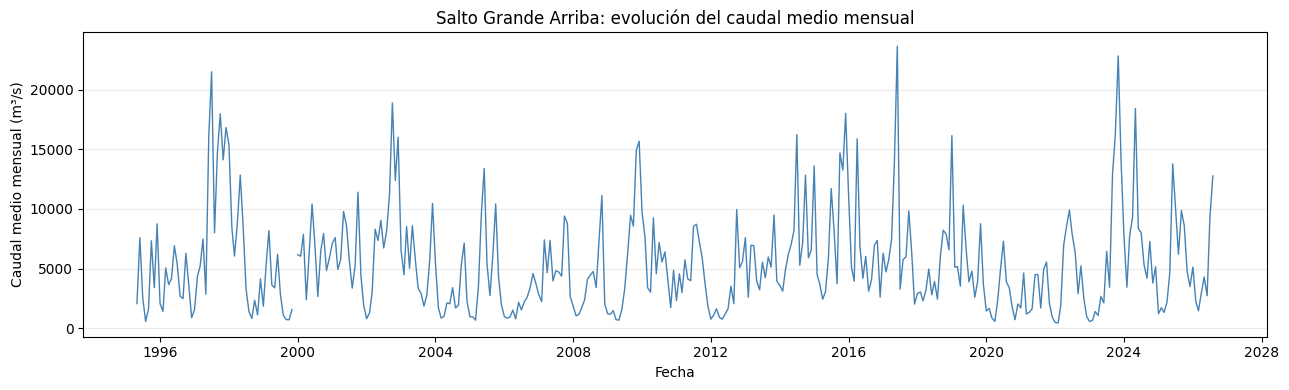

In [7]:
fechas = pd.to_datetime(df_salto_grande["timestart"], errors="raise")
caudal = pd.to_numeric(df_salto_grande["valor"], errors="raise")

serie_temporal = pd.Series(
    caudal.to_numpy(),
    index=pd.DatetimeIndex(fechas),
    name="caudal"
).sort_index().asfreq("MS")

fig, ax = plt.subplots(figsize=(13, 4))

ax.plot(
    serie_temporal.index,
    serie_temporal.values,
    color="steelblue",
    linewidth=1
)

ax.set_title("Salto Grande Arriba: evolución del caudal medio mensual")
ax.set_xlabel("Fecha")
ax.set_ylabel("Caudal medio mensual (m³/s)")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

- Exploracion temporal: La serie presenta fluctuaciones importantes, con períodos de caudales relativamente bajos interrumpidos por picos elevados. Algunos promedios mensuales superan los 20 000 m³/s. La inspección visual no permite establecer una tendencia sostenida de aumento o disminución ni atribuir estas variaciones a ENSO.

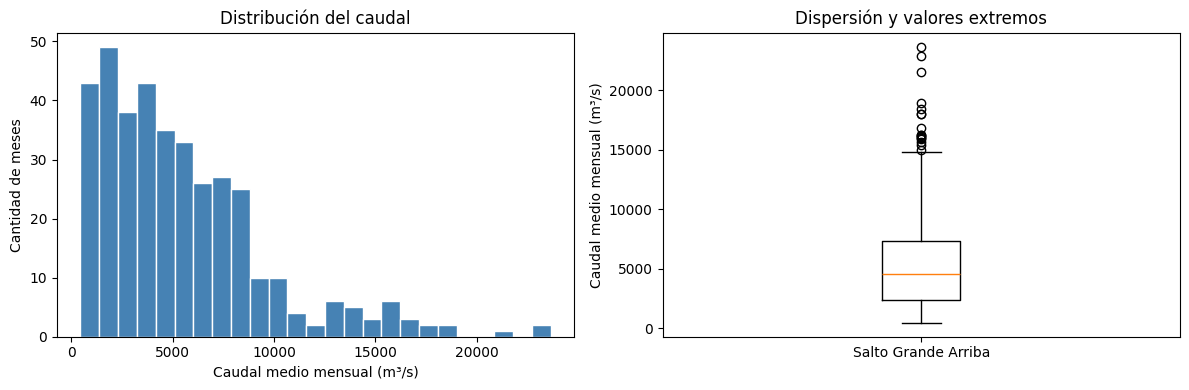

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    caudal.dropna(),
    bins=25,
    color="steelblue",
    edgecolor="white"
)
axes[0].set_title("Distribución del caudal")
axes[0].set_xlabel("Caudal medio mensual (m³/s)")
axes[0].set_ylabel("Cantidad de meses")

axes[1].boxplot(caudal.dropna())
axes[1].set_title("Dispersión y valores extremos")
axes[1].set_ylabel("Caudal medio mensual (m³/s)")
axes[1].set_xticks([1])
axes[1].set_xticklabels(["Salto Grande Arriba"])

plt.tight_layout()
plt.show()

- Distribución y dispersión: El histograma muestra una distribución asimétrica hacia la derecha: predominan los caudales bajos e intermedios, mientras que los valores muy altos son menos frecuentes. El boxplot sitúa la mediana aproximadamente entre 4000 y 5000 m³/s y muestra varias observaciones por encima del bigote superior.
Estos puntos son valores extremos según el boxplot, pero no necesariamente errores. Pueden corresponder a meses de aportes elevados y requieren examinar sus fechas y la información de la fuente antes de decidir cualquier tratamiento. Al tratarse de promedios mensuales, no representan los máximos instantáneos de una crecida.

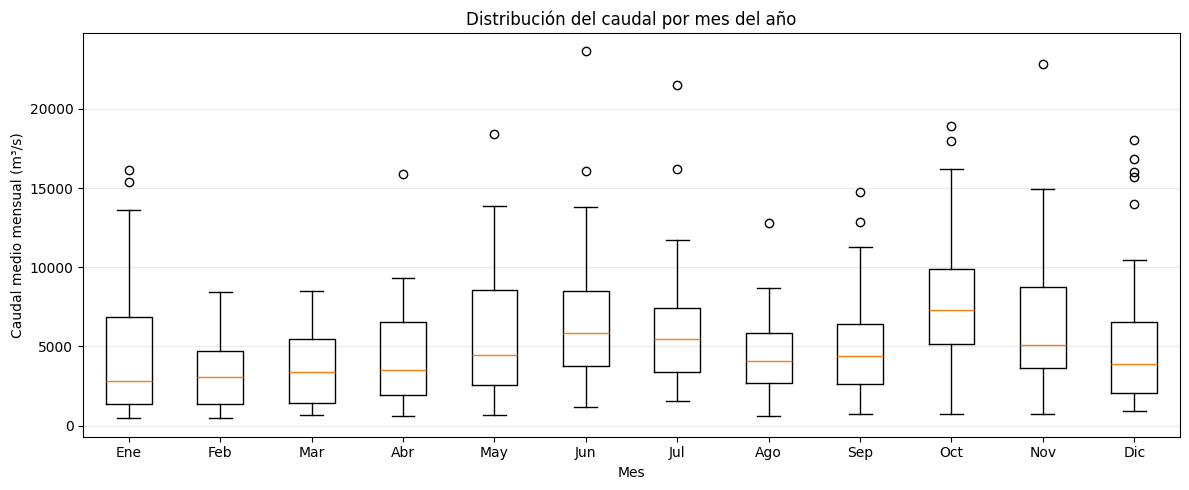

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.boxplot([
    caudal.loc[fechas.dt.month.eq(mes)].dropna()
    for mes in range(1, 13)
])

ax.set_xticks(range(1, 13))
ax.set_xticklabels([
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
])

ax.set_title("Distribución del caudal por mes del año")
ax.set_xlabel("Mes")
ax.set_ylabel("Caudal medio mensual (m³/s)")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Exploración del caudal medio mensual en Salto Grande Arriba

- Comportamiento por mes del año:
Se observan diferencias estacionales en las distribuciones. Octubre presenta la mediana más alta, cercana a 7000 m³/s; junio y julio también muestran medianas relativamente elevadas. Enero y febrero presentan las medianas más bajas. La dispersión es considerable y existe superposición entre las distribuciones mensuales. Por lo tanto, el mes del año aporta contexto, pero no determina por sí solo el caudal. Además, aparecen valores extremos altos en distintos meses, incluso en algunos con medianas bajas.

Implicación para el proyecto.
La estacionalidad deberá considerarse al explorar la relación entre caudal y los índices ENSO. Estos gráficos describen el comportamiento del caudal, pero todavía no demuestran una asociación con ONI, RONI o SOI.

In [10]:
# Valores atípicos según el criterio de 1,5 × IQR
def contar_atipicos(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    return (
        (serie < limite_inferior) |
        (serie > limite_superior)
    ).sum()


# Resumen por mes calendario, sin modificar df_salto_grande
display(
    df_salto_grande["valor"]
    .groupby(
        pd.to_datetime(
            df_salto_grande["timestart"], errors="raise"
        ).dt.month
    )
    .agg(
        cantidad="count",
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max",
        atipicos=contar_atipicos
    )
    .rename_axis("mes")
    .round(2)
)

,cantidad,media,mediana,minimo,maximo,atipicos
mes,,,,,,
1,31,4746.66,2821.81,486.06,16147.90,2
2,31,3340.45,3041.18,452.11,8432.43,0
3,31,3809.93,3404.58,682.35,8527.74,0
4,31,4449.15,3530.68,576.47,15881.50,1
5,32,5833.87,4476.00,691.65,18424.00,1
6,32,6790.64,5849.14,1191.17,23647.80,2
7,32,6340.28,5477.06,1535.00,21497.60,2
8,32,4515.03,4067.55,572.32,12768.00,1
9,31,5250.20,4371.20,729.10,14767.40,2


Se agruparon los caudales medios mensuales por mes calendario: todos los eneros, todos los febreros y así sucesivamente. Para cada grupo se calculó la cantidad de observaciones, la media, la mediana, el mínimo, el máximo y el número de valores atípicos. Los caudales se expresan en m³/s.

La comparación entre media y mediana permite evaluar la influencia de los caudales extremos. La media es más sensible a valores muy elevados, mientras que la mediana representa el centro de la distribución con menor influencia de estos extremos.

Se consideraron atípicas las observaciones inferiores a Q1 - 1,5 * IQR o superiores a Q3 + 1,5 * IQR, donde IQR = Q3 - Q1. Los límites se calcularon por separado para cada mes, para considerar las diferencias estacionales.

La columna `atipicos` indica cuántos promedios mensuales quedaron fuera de esos límites. Por ejemplo, un valor de 2 en enero representa dos eneros de distintos años, no dos días de crecida.

Los valores señalados se conservan: pueden representar situaciones hidrológicas reales y no necesariamente errores. Su identificación orienta la revisión de eventos excepcionales, pero no demuestra una relación con ENSO ni constituye, por sí sola, una clasificación de sequías o crecidas.

### DataFrame df_oni

In [11]:
# ¿Cuántas filas y columnas tiene?
print("Filas:", df_oni.shape[0])
print("Columnas:", df_oni.shape[1])

# Inspección de los registros
display(df_oni.head())
display(df_oni.tail())

# ¿Qué tipo de dato tiene cada variable?
df_oni.info()

# ¿Existen valores nulos?
print("Existen valores nulos? \n",df_oni.isna().sum())

# ¿Existen filas completamente duplicadas?
print("Filas duplicadas:", df_oni.duplicated().sum())

# ¿Se repite alguna combinación de año y trimestre?
print(
    "Año-trimestre duplicados:",
    df_oni.duplicated(subset=["YR", "SEAS"]).sum()
)

# Categorías y cobertura
print("Trimestres presentes:", df_oni["SEAS"].unique())
print("Año inicial:", df_oni["YR"].min())
print("Año final:", df_oni["YR"].max())

# Cantidad de registros por año
print(df_oni.groupby("YR").size())

# Resumen estadístico de las variables físicas
display(df_oni[["TOTAL", "ANOM"]].describe())

Filas: 921
Columnas: 4


,SEAS,YR,TOTAL,ANOM
0,DJF,1950,25.01,-1.32
1,JFM,1950,25.36,-1.20
2,FMA,1950,25.88,-1.12
3,MAM,1950,26.24,-1.08
4,AMJ,1950,26.35,-1.10


,SEAS,YR,TOTAL,ANOM
916,AMJ,2026,28.74,0.95
917,MJJ,2026,29.02,1.39
918,JJA,2026,29.09,1.80
919,JAS,2026,29.12,2.16
920,ASO,2026,29.23,2.46


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 921 entries, 0 to 920
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEAS    921 non-null    object 
 1   YR      921 non-null    int64  
 2   TOTAL   921 non-null    float64
 3   ANOM    921 non-null    float64
dtypes: float64(2), int64(1), object(1)
memory usage: 28.9+ KB
Existen valores nulos? 
 SEAS     0
YR       0
TOTAL    0
ANOM     0
dtype: int64
Filas duplicadas: 0
Año-trimestre duplicados: 0
Trimestres presentes: ['DJF' 'JFM' 'FMA' 'MAM' 'AMJ' 'MJJ' 'JJA' 'JAS' 'ASO' 'SON' 'OND' 'NDJ']
Año inicial: 1950
Año final: 2026
YR
1950    12
1951    12
1952    12
1953    12
1954    12
        ..
2022    12
2023    12
2024    12
2025    12
2026     9
Length: 77, dtype: int64


,TOTAL,ANOM
count,921.000000,921.000000
mean,26.938806,0.023626
std,0.909009,0.793990
min,24.390000,-2.040000
25%,26.310000,-0.510000
50%,26.980000,-0.040000
75%,27.570000,0.500000
max,29.230000,2.590000


Cada fila del ONI representa un trimestre móvil de tres meses. `TOTAL` expresa la temperatura superficial media y `ANOM` su anomalía en °C.

`SEAS` identifica una categoría temporal cíclica; no es una fecha completa por sí sola. Para representar la serie se combina con `YR` y se usa el mes central: DJF → enero, JFM → febrero, etc. DJF de un año incluye diciembre del año anterior.

Esta referencia permite un análisis retrospectivo, pero no implica disponibilidad en tiempo real: el trimestre DJF incluye febrero. La asignación temporal no modifica `df_oni`.


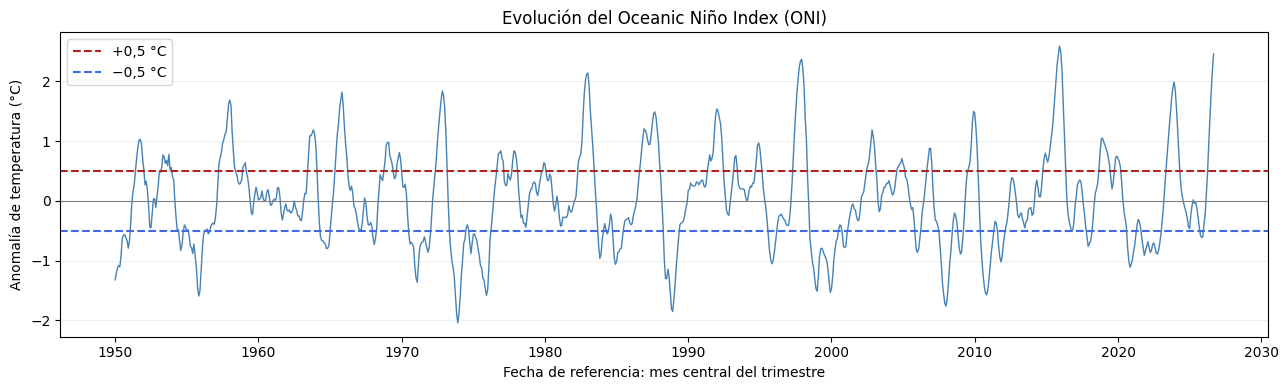

In [12]:
fig, ax = plt.subplots(figsize=(13, 4))

ax.plot(
    pd.to_datetime({
        "year": df_oni["YR"],
        "month": df_oni["SEAS"].str.strip().map({
            "DJF": 1, "JFM": 2, "FMA": 3, "MAM": 4,
            "AMJ": 5, "MJJ": 6, "JJA": 7, "JAS": 8,
            "ASO": 9, "SON": 10, "OND": 11, "NDJ": 12
        }),
        "day": 1
    }, errors="raise"),
    df_oni["ANOM"],
    color="steelblue",
    linewidth=1
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.axhline(
    0.5, color="firebrick", linestyle="--", label="+0,5 °C"
)
ax.axhline(
    -0.5, color="royalblue", linestyle="--", label="−0,5 °C"
)

ax.set_title("Evolución del Oceanic Niño Index (ONI)")
ax.set_xlabel("Fecha de referencia: mes central del trimestre")
ax.set_ylabel("Anomalía de temperatura (°C)")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

El índice alterna entre anomalías positivas y negativas, con períodos que permanecen durante varios registros por encima de +0,5 °C o por debajo de -0,5 °C. La intensidad y duración de estas condiciones varían a lo largo de la serie; no se observa una periodicidad fija. Los umbrales se utilizan como referencias. Un cruce aislado no permite identificar un episodio histórico de El Niño o La Niña, ya que también debe considerarse su persistencia.

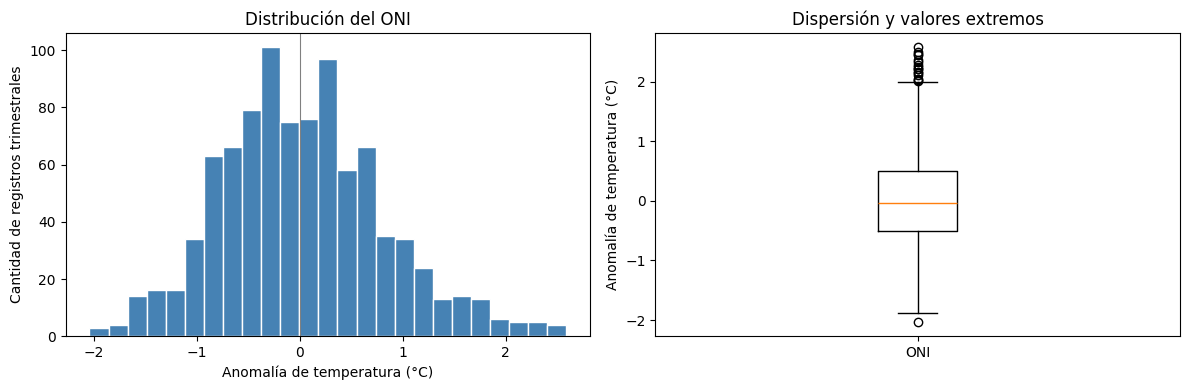

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    df_oni["ANOM"].dropna(),
    bins=25,
    color="steelblue",
    edgecolor="white"
)
axes[0].axvline(0, color="gray", linewidth=0.8)
axes[0].set_title("Distribución del ONI")
axes[0].set_xlabel("Anomalía de temperatura (°C)")
axes[0].set_ylabel("Cantidad de registros trimestrales")

axes[1].boxplot(df_oni["ANOM"].dropna())
axes[1].set_title("Dispersión y valores extremos")
axes[1].set_ylabel("Anomalía de temperatura (°C)")
axes[1].set_xticks([1])
axes[1].set_xticklabels(["ONI"])

plt.tight_layout()
plt.show()

La distribución se concentra alrededor de cero y la mediana es ligeramente negativa. Se observa una cola positiva más extensa: los máximos se aproximan a +2,6 °C, mientras que los mínimos rondan -2,0 °C.

El boxplot señala varios registros extremos positivos y uno negativo. Estos corresponden a ventanas trimestrales, no necesariamente a episodios distintos: un mismo evento persistente puede generar varias observaciones extremas consecutivas.

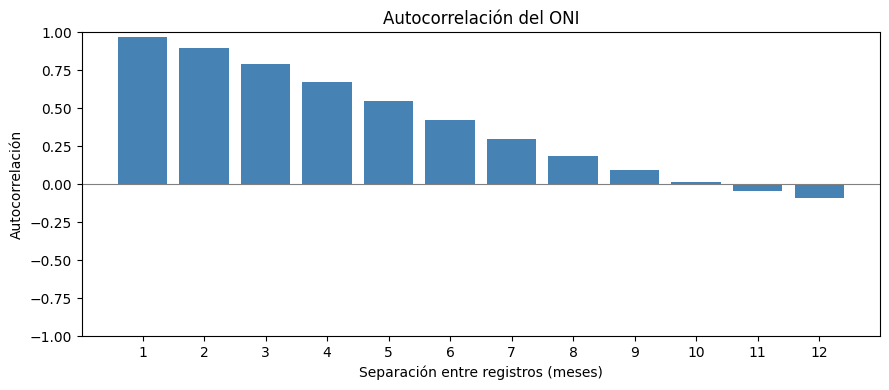

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    range(1, 13),
    [df_oni["ANOM"].autocorr(lag=meses) for meses in range(1, 13)],
    color="steelblue"
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xticks(range(1, 13))
ax.set_ylim(-1, 1)

ax.set_title("Autocorrelación del ONI")
ax.set_xlabel("Separación entre registros (meses)")
ax.set_ylabel("Autocorrelación")

plt.tight_layout()
plt.show()

La autocorrelación es muy alta para registros separados por un mes —aproximadamente 0,97— y disminuye progresivamente al aumentar el rezago. Se aproxima a cero alrededor de los diez meses y resulta ligeramente negativa a los once y doce meses.

Este comportamiento es compatible con persistencia temporal, pero también refleja la construcción del índice: las ventanas trimestrales consecutivas comparten dos meses. Por lo tanto, las observaciones no deben tratarse como independientes.

La autocorrelación negativa al final del gráfico no demuestra un ciclo anual ni una inversión obligatoria de fase. Tampoco estos resultados, por sí solos, prueban capacidad para predecir el caudal.

### DataFrame df_roni

In [15]:
# ¿Cuántas filas y columnas tiene?
print("Filas:", df_roni.shape[0])
print("Columnas:", df_roni.shape[1])
print("Nombres de columnas:", df_roni.columns.tolist())

# Inspección de los registros
display(df_roni.head())
display(df_roni.tail())

# ¿Qué tipo de dato tiene cada variable?
df_roni.info()

# ¿Existen valores nulos?
print("Registros nulos: \n",df_roni.isna().sum())

# ¿Existen registros duplicados?
print("Filas duplicadas:", df_roni.duplicated().sum())
print("Fechas repetidas:", df_roni["Date"].duplicated().sum())

# Posibles códigos de datos faltantes en la segunda columna
print("Valores -9999:", df_roni.iloc[:, 1].eq(-9999).sum())
print("Valores -99:", df_roni.iloc[:, 1].eq(-99).sum())

# Resumen numérico tal como está cargado
display(df_roni.iloc[:, 1].describe())

Filas: 936
Columnas: 2
Nombres de columnas: ['Date', '  relative oceanic nino (RONI) index  missing value -99 https://psl.noaa.gov/data/timeseries/month/']


,Date,relative oceanic nino (RONI) index missing value -99 https://psl.noaa.gov/data/timeseries/month/
0,1949-01-01,-9999.0
1,1949-02-01,-9999.0
2,1949-03-01,-9999.0
3,1949-04-01,-9999.0
4,1949-05-01,-9999.0


,Date,relative oceanic nino (RONI) index missing value -99 https://psl.noaa.gov/data/timeseries/month/
931,2026-08-01,1.67
932,2026-09-01,-9999.00
933,2026-10-01,-9999.00
934,2026-11-01,-9999.00
935,2026-12-01,-9999.00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 936 entries, 0 to 935
Data columns (total 2 columns):
 #   Column                                                                                               Non-Null Count  Dtype  
---  ------                                                                                               --------------  -----  
 0   Date                                                                                                 936 non-null    object 
 1     relative oceanic nino (RONI) index  missing value -99 https://psl.noaa.gov/data/timeseries/month/  936 non-null    float64
dtypes: float64(1), object(1)
memory usage: 14.8+ KB
Registros nulos: 
 Date                                                                                                   0
  relative oceanic nino (RONI) index  missing value -99 https://psl.noaa.gov/data/timeseries/month/    0
dtype: int64
Filas duplicadas: 0
Fechas repetidas: 0
Valores -9999: 15
Valores -99: 0


,relative oceanic nino (RONI) index missing value -99 https://psl.noaa.gov/data/timeseries/month/
count,936.000000
mean,-160.218868
std,1256.288337
min,-9999.000000
25%,-0.582500
50%,-0.050000
75%,0.532500
max,2.500000


- `Date` contiene la etiqueta temporal del archivo. Su correspondencia con una ventana trimestral debe verificarse antes de concluir que está alineada con ONI.
- La segunda columna contiene el índice relativo. Su encabezado incorpora metadatos y menciona `-99`, aunque los códigos de ausencia observados son `-9999`.
- `isna()` no identifica esos códigos numéricos. La inspección cuenta 15 registros con `-9999` y ninguno con `-99`.
- La media y la desviación estándar calculadas incluyendo esos códigos no describen el índice climático.
- A continuación se calculan estadísticas sobre los valores disponibles mediante una selección auxiliar, sin modificar el dataframe original.


In [16]:
display(df_roni.loc[df_roni.iloc[:, 1].eq(-9999)])
display(df_roni.loc[df_roni["Date"].eq("1949-12-01")])

,Date,relative oceanic nino (RONI) index missing value -99 https://psl.noaa.gov/data/timeseries/month/
0,1949-01-01,-9999.0
1,1949-02-01,-9999.0
2,1949-03-01,-9999.0
3,1949-04-01,-9999.0
4,1949-05-01,-9999.0
5,1949-06-01,-9999.0
6,1949-07-01,-9999.0
7,1949-08-01,-9999.0
8,1949-09-01,-9999.0
9,1949-10-01,-9999.0


,Date,relative oceanic nino (RONI) index missing value -99 https://psl.noaa.gov/data/timeseries/month/
11,1949-12-01,-1.03


Se identificaron 15 registros con el código de ausencia `-9999`: 11 entre enero y noviembre de 1949 y 4 entre septiembre y diciembre de 2026. Aunque pandas no los reconoce como nulos, representan valores no disponibles y distorsionan las estadísticas descriptivas.

Estos registros se encuentran fuera del período propuesto para el análisis conjunto, 1996–2025. No se modificaron ni eliminaron durante esta inspección.


In [17]:
roni_validos = (
    df_roni.iloc[:, 1].notna()
    & ~df_roni.iloc[:, 1].isin([-9999, -99])
)

print("Registros totales:", len(df_roni))
print("Registros válidos:", roni_validos.sum())
print("Registros a exluir de los gráficos:", (~roni_validos).sum())

display(df_roni.loc[roni_validos].iloc[:, 1].describe())

Registros totales: 936
Registros válidos: 921
Registros a exluir de los gráficos: 15


,relative oceanic nino (RONI) index missing value -99 https://psl.noaa.gov/data/timeseries/month/
count,921.000000
mean,0.021868
std,0.837476
min,-2.170000
25%,-0.540000
50%,-0.020000
75%,0.550000
max,2.500000


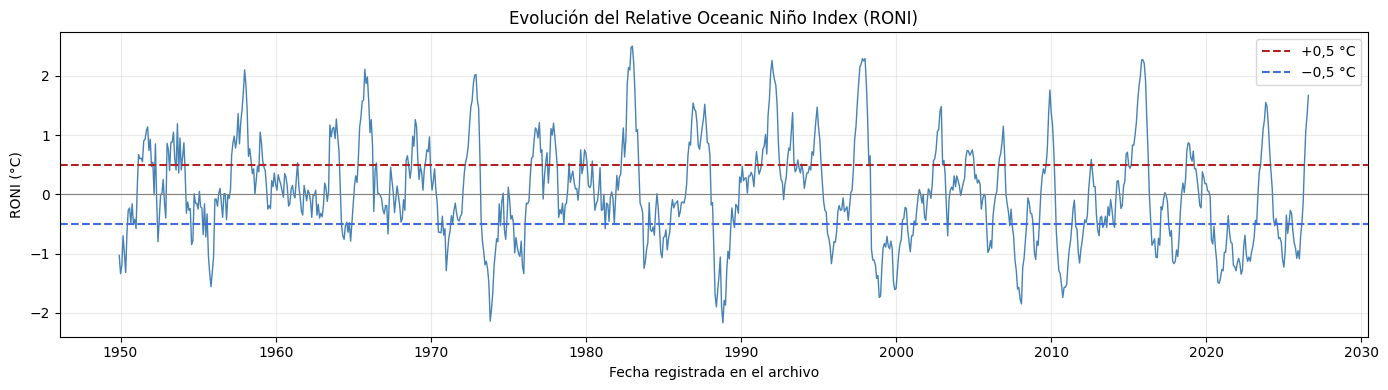

In [18]:
plt.figure(figsize=(14, 4))

plt.plot(
    pd.to_datetime(df_roni["Date"], errors="raise"),
    df_roni.iloc[:, 1].where(roni_validos),
    color="steelblue",
    linewidth=1
)

plt.axhline(0, color="gray", linewidth=0.8)
plt.axhline(
    0.5, color="firebrick", linestyle="--",
    label="+0,5 °C"
)
plt.axhline(
    -0.5, color="royalblue", linestyle="--",
    label="−0,5 °C"
)

plt.title("Evolución del Relative Oceanic Niño Index (RONI)")
plt.xlabel("Fecha registrada en el archivo")
plt.ylabel("RONI (°C)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La evolución temporal del RONI muestra períodos de anomalías positivas y negativas, con diferencias en intensidad y duración. Visualmente, las oscilaciones no presentan una repetición regular. Las líneas de ±0,5 °C se utilizan como referencias; su cruce aislado no permite identificar un evento completo de El Niño o La Niña.

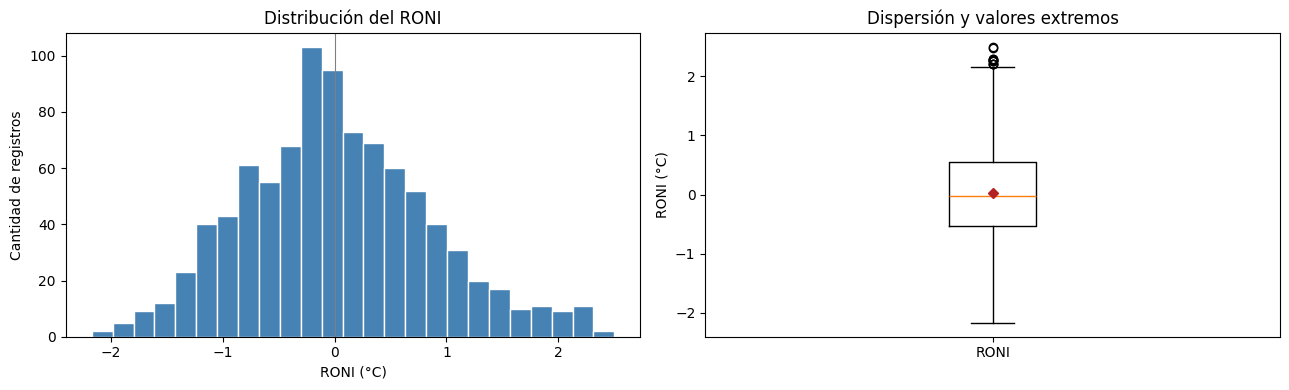

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(
    df_roni.loc[roni_validos].iloc[:, 1],
    bins=25,
    color="steelblue",
    edgecolor="white"
)
axes[0].axvline(0, color="gray", linewidth=0.8)
axes[0].set_title("Distribución del RONI")
axes[0].set_xlabel("RONI (°C)")
axes[0].set_ylabel("Cantidad de registros")

axes[1].boxplot(
    df_roni.loc[roni_validos].iloc[:, 1],
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "firebrick",
        "markeredgecolor": "firebrick",
        "markersize": 5
    }
)
axes[1].set_xticks([1])
axes[1].set_xticklabels(["RONI"])
axes[1].set_title("Dispersión y valores extremos")
axes[1].set_ylabel("RONI (°C)")

plt.tight_layout()
plt.show()



El histograma muestra una mayor concentración de observaciones alrededor de cero y una cola algo más extendida hacia valores positivos. La media y la mediana son cercanas a cero, con la media ligeramente superior a la mediana. Estos resultados sugieren una leve asimetría positiva, sin que la forma del histograma permita afirmar que la distribución es normal.

El boxplot identifica algunos valores positivos por encima del bigote superior. Estas observaciones son estadísticamente extremas según el criterio del gráfico, pero no constituyen por sí mismas errores y se conservan. Varios registros extremos podrían corresponder a un mismo episodio. La ausencia de puntos fuera del bigote inferior tampoco implica que no hayan existido anomalías negativas intensas.

Fechas ordenadas: True
Meses duplicados: 0
Meses ausentes del calendario: []


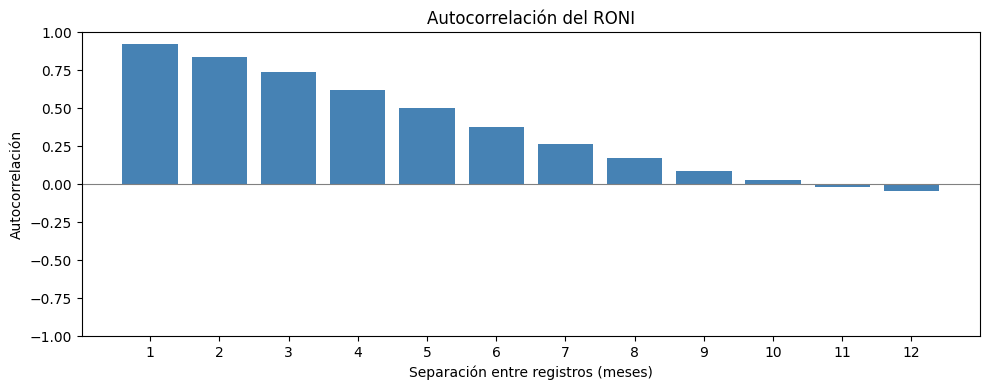

In [20]:
# Comprobación temporal auxiliar: no modifica df_roni.
meses_roni = pd.to_datetime(
    df_roni["Date"], errors="raise"
).dt.to_period("M")

print("Fechas ordenadas:", meses_roni.is_monotonic_increasing)
print("Meses duplicados:", meses_roni.duplicated().sum())

print(
    "Meses ausentes del calendario:",
    pd.period_range(
        meses_roni.min(), meses_roni.max(), freq="M"
    ).difference(pd.PeriodIndex(meses_roni)).astype(str).tolist()
)

plt.figure(figsize=(10, 4))

plt.bar(
    range(1, 13),
    [
        df_roni.iloc[:, 1]
        .where(roni_validos)
        .autocorr(lag=meses)
        for meses in range(1, 13)
    ],
    color="steelblue"
)

plt.axhline(0, color="gray", linewidth=0.8)
plt.xticks(range(1, 13))
plt.ylim(-1, 1)
plt.title("Autocorrelación del RONI")
plt.xlabel("Separación entre registros (meses)")
plt.ylabel("Autocorrelación")
plt.tight_layout()
plt.show()

La autocorrelación del RONI es aproximadamente 0,92 para un rezago de un mes y disminuye hasta alrededor de 0,50 a los cinco meses. Esto indica que los valores cercanos en el tiempo presentan una fuerte asociación lineal y no deben considerarse observaciones independientes.

A partir de los diez meses, la autocorrelación se aproxima a cero y presenta valores ligeramente negativos a los once y doce meses. Estos resultados no demuestran una inversión obligatoria de fase ni un ciclo anual. Tampoco permiten establecer por sí solos un horizonte de predicción.

### DataFrame df_soi

In [21]:
# Dimensiones
print("Filas:", df_soi.shape[0])
print("Columnas:", df_soi.shape[1])

# Primeros y últimos registros
display(df_soi.head())
display(df_soi.tail())

# Tipos de datos
df_soi.info()

# Valores nulos
print("\nNulos por columna:")
print(df_soi.isna().sum())

# Duplicados
print("Filas duplicadas:", df_soi.duplicated().sum())
print("Meses repetidos:", df_soi["anio_mes"].duplicated().sum())

# Cobertura temporal
print("Primer año-mes:", df_soi["anio_mes"].min())
print("Último año-mes:", df_soi["anio_mes"].max())

# Estadísticas del índice
display(df_soi["soi"].describe())

Filas: 1808
Columnas: 2


,anio_mes,soi
0,187601,11.3
1,187602,11.0
2,187603,0.2
3,187604,9.4
4,187605,6.8


,anio_mes,soi
1803,202604,-11.2
1804,202605,-14.5
1805,202606,-24.9
1806,202607,-29.1
1807,202608,-14.6


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1808 entries, 0 to 1807
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anio_mes  1808 non-null   string 
 1   soi       1808 non-null   float64
dtypes: float64(1), string(1)
memory usage: 28.4 KB

Nulos por columna:
anio_mes    0
soi         0
dtype: int64
Filas duplicadas: 0
Meses repetidos: 0
Primer año-mes: 187601
Último año-mes: 202608


,soi
count,1808.000000
mean,0.184347
std,10.462308
min,-42.600000
25%,-6.725000
50%,0.400000
75%,7.425000
max,34.800000


- Cada fila representa el valor mensual del índice SOI de Troup. anio_mes identifica el período mediante el formato AAAAMM; por ejemplo, 187601 corresponde a enero de 1876. soi contiene el índice atmosférico, que es adimensional.

- anio_mes tiene tipo string, mientras que soi tiene tipo float64.

- No se detectaron valores nulos en ninguna columna. Las 1808 filas coinciden con la cantidad de meses esperada entre enero de 1876 y agosto de 2026; esto es consistente con una cobertura mensual completa.

- Para futuros análisis temporales sería conveniente convertir anio_mes a fecha o período mensual. El tipo numérico de soi es adecuado.

- No se encontraron filas completamente duplicadas ni valores repetidos de anio_mes.

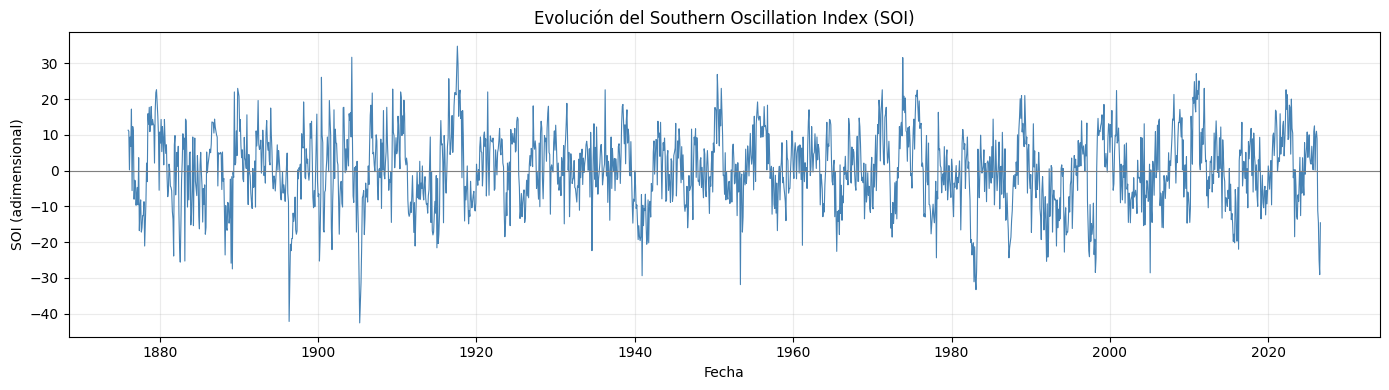

In [22]:
plt.figure(figsize=(14, 4))

plt.plot(
    pd.to_datetime(df_soi["anio_mes"], format="%Y%m", errors="raise"),
    df_soi["soi"],
    color="steelblue",
    linewidth=0.8
)

plt.axhline(0, color="gray", linewidth=0.8)

plt.title("Evolución del Southern Oscillation Index (SOI)")
plt.xlabel("Fecha")
plt.ylabel("SOI (adimensional)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La evolución temporal del SOI muestra oscilaciones positivas y negativas, con variaciones frecuentes entre meses y períodos de distinta duración. La inspección visual no permite establecer una tendencia de largo plazo ni una periodicidad fija.

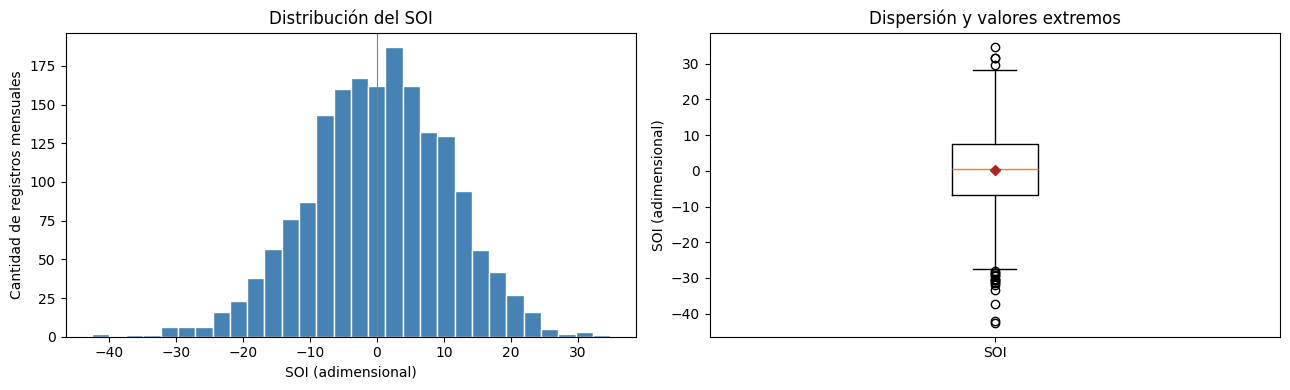

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(
    df_soi["soi"].dropna(),
    bins=30,
    color="steelblue",
    edgecolor="white"
)
axes[0].axvline(0, color="gray", linewidth=0.8)
axes[0].set_title("Distribución del SOI")
axes[0].set_xlabel("SOI (adimensional)")
axes[0].set_ylabel("Cantidad de registros mensuales")

axes[1].boxplot(
    df_soi["soi"].dropna(),
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "firebrick",
        "markeredgecolor": "firebrick",
        "markersize": 5
    }
)
axes[1].set_xticks([1])
axes[1].set_xticklabels(["SOI"])
axes[1].set_title("Dispersión y valores extremos")
axes[1].set_ylabel("SOI (adimensional)")

plt.tight_layout()
plt.show()

El histograma presenta una distribución unimodal, aproximadamente acampanada y centrada cerca de cero. La media (0,18) y la mediana (0,40) son próximas, aunque esta semejanza no basta para afirmar que la distribución sea normal o perfectamente simétrica.

El 50 % central de las observaciones se encuentra entre −6,73 y 7,43. Los valores abarcan desde −42,6 hasta 34,8, con una cola negativa más extendida. El boxplot identifica observaciones extremas en ambos sentidos, con mayor presencia visual en el extremo negativo.

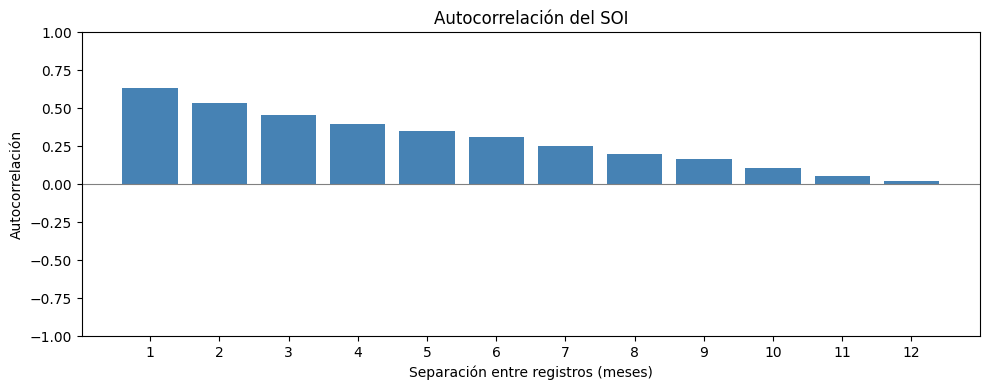

In [24]:
plt.figure(figsize=(10, 4))

plt.bar(
    range(1, 13),
    [
        df_soi["soi"].autocorr(lag=meses)
        for meses in range(1, 13)
    ],
    color="steelblue"
)

plt.axhline(0, color="gray", linewidth=0.8)
plt.xticks(range(1, 13))
plt.ylim(-1, 1)

plt.title("Autocorrelación del SOI")
plt.xlabel("Separación entre registros (meses)")
plt.ylabel("Autocorrelación")

plt.tight_layout()
plt.show()

La autocorrelación del SOI indica dependencia temporal entre los registros mensuales. La asociación lineal es mayor entre meses consecutivos y disminuye progresivamente al aumentar el rezago, aproximándose a cero a los doce meses.

Este comportamiento sugiere persistencia temporal del índice. Sin embargo, no establece una duración fija de los episodios ni permite determinar un horizonte de predicción. Una autocorrelación cercana a cero tampoco demuestra independencia, ya que pueden existir relaciones que esta medida lineal no detecta.

# 4. Análisis conjunto: 1996–2025

Se usa un calendario de 360 meses, conservando las posiciones de los meses sin información. No se interpola ni se desplazan fechas para maximizar correlaciones.

Las comprobaciones siguientes validan etiquetas, orden, unicidad y continuidad del calendario. No prueban que las fechas asignadas representen el mismo período físico en las cuatro fuentes.

ONI se ubica en el mes central de su trimestre. RONI conserva la fecha de su archivo; sus resultados son provisionales hasta completar la verificación temporal.

Las correlaciones se calculan sobre los meses con las cuatro variables disponibles. No se ajusta todavía por estacionalidad ni se estudian rezagos.


In [25]:
df_conjunto = pd.concat(
    [
        df_salto_grande["valor"].rename("caudal_m3s")
        .set_axis(indices_mensuales["Salto Grande"]),
        df_oni["ANOM"].rename("ONI")
        .set_axis(indices_mensuales["ONI"]),
        df_roni.iloc[:, 1].rename("RONI")
        .set_axis(indices_mensuales["RONI"])
        .replace([-9999, -99], float("nan")),
        df_soi["soi"].rename("SOI")
        .set_axis(indices_mensuales["SOI"])
    ],
    axis=1
).reindex(
    pd.period_range("1996-01", "2025-12", freq="M")
).rename_axis("mes")

display(df_conjunto.head())
print("Meses del período:", len(df_conjunto))
print("Faltantes por variable:")
display(df_conjunto.isna().sum())
print("Meses excluidos de las correlaciones por información incompleta:")
display(df_conjunto.loc[df_conjunto.isna().any(axis=1)])
print("Meses completos:", df_conjunto.notna().all(axis=1).sum())


,caudal_m3s,ONI,RONI,SOI
mes,,,,
1996-01,2075.19,-0.88,-0.80,8.4
1996-02,1420.31,-0.70,-0.81,1.1
1996-03,5057.81,-0.52,-0.64,6.2
1996-04,3664.20,-0.36,-0.29,7.8
1996-05,4139.77,-0.25,-0.19,1.3


Meses del período: 360
Faltantes por variable:


,0
caudal_m3s,1
ONI,0
RONI,0
SOI,0


Meses excluidos de las correlaciones por información incompleta:


,caudal_m3s,ONI,RONI,SOI
mes,,,,
1999-12,NaN,-1.53,-1.61,12.8


Meses completos: 359


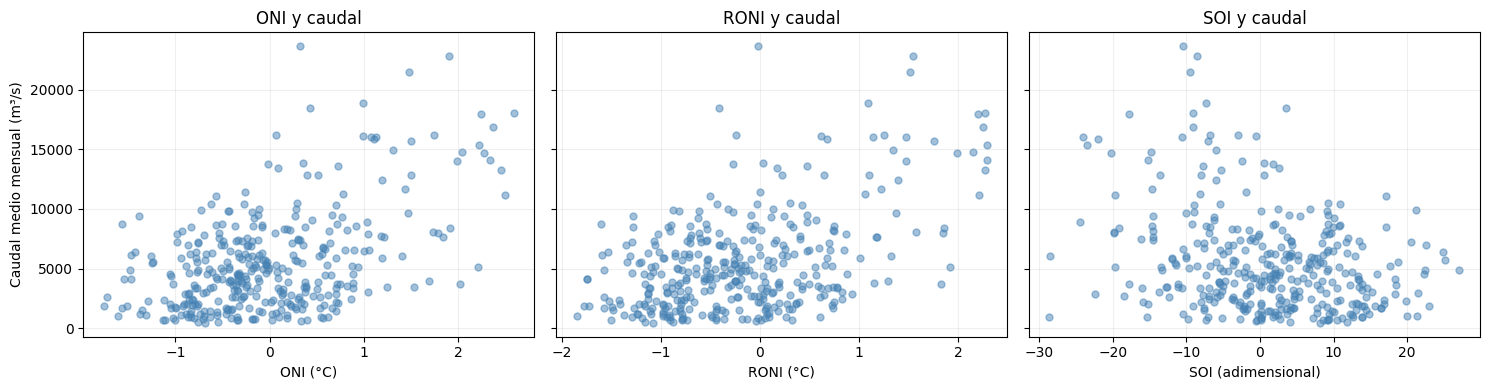

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, indice in zip(axes, ["ONI", "RONI", "SOI"]):
    ax.scatter(
        df_conjunto[indice],
        df_conjunto["caudal_m3s"],
        alpha=0.5,
        s=25,
        color="steelblue"
    )

    ax.set_title(f"{indice} y caudal")
    ax.set_xlabel(
        f"{indice} (°C)"
        if indice != "SOI"
        else "SOI (adimensional)"
    )
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Caudal medio mensual (m³/s)")

plt.tight_layout()
plt.show()

## Asociaciones contemporáneas

Pearson resume la asociación lineal; Spearman compara el orden de los valores y resume asociaciones monótonas. Ambos se calculan sobre los mismos meses completos.

Los coeficientes no expresan porcentajes de caudal explicado ni prueban causalidad. No se calculan valores p suponiendo observaciones independientes: las series presentan dependencia temporal.


In [27]:
display(
    pd.DataFrame({
        "Pearson": (
            df_conjunto.dropna()
            .corr(method="pearson")["caudal_m3s"]
        ),
        "Spearman": (
            df_conjunto.dropna()
            .corr(method="spearman")["caudal_m3s"]
        )
    }).loc[["ONI", "RONI", "SOI"]]
)

print("Meses completos utilizados:", len(df_conjunto.dropna()))

,Pearson,Spearman
ONI,0.494790,0.369785
RONI,0.488287,0.354557
SOI,-0.297830,-0.246610


Meses completos utilizados: 359


# 5. Síntesis de resultados

Los resultados guardados de la exploración original muestran:

- Un caudal de distribución asimétrica, con promedios mensuales extremos que se conservan.
- Diferencias entre las distribuciones del caudal según el mes calendario.
- Dependencia temporal en los índices, por lo que las observaciones no se consideran independientes.
- Asociaciones contemporáneas positivas del caudal con ONI y RONI, y negativas con SOI.

En la ejecución original se utilizaron **359 meses completos** de los 360 meses de 1996–2025. La inspección previa identificó diciembre de 1999 como mes ausente en la serie de caudal; la tabla de integración permite comprobarlo al ejecutar esta copia.

| Índice | Pearson | Spearman |
|---|---:|---:|
| ONI | 0,495 | 0,370 |
| RONI —alineación provisional— | 0,488 | 0,355 |
| SOI | −0,298 | −0,247 |

Estas cifras corresponden a los outputs guardados del notebook de origen. Deben contrastarse con la tabla recalculada si cambian los archivos o las versiones de los índices.

Los diagramas presentan una dispersión considerable. La similitud entre ONI y RONI no permite concluir que uno sea mejor predictor. La diferencia entre Pearson y Spearman no identifica por sí sola el efecto de los extremos.

**Respuesta a la pregunta:** en la muestra analizada se observan asociaciones contemporáneas entre índices y caudal. Este hallazgo justifica continuar investigando, pero no demuestra causalidad, capacidad predictiva ni un efecto cuantificado sobre la generación hidroeléctrica.


## Limitaciones

1. **Interpretación hidrológica:** falta confirmar si el caudal de la estación representa el aporte que interesa para la operación del embalse y cómo intervienen regulaciones aguas arriba.
2. **Alineación de RONI:** la fecha del CSV no se ha vinculado documentalmente con la ventana de cálculo de la versión descargada. No se aplica ninguna corrección de fechas sin esa evidencia.
3. **Resolución temporal:** ONI utiliza trimestres móviles; SOI y el caudal son mensuales. Compartir una etiqueta mensual no iguala sus ventanas de agregación.
4. **Estacionalidad y dependencia temporal:** las correlaciones son descriptivas y no están ajustadas por estos efectos.
5. **Cobertura:** treinta años no equivalen a 360 episodios climáticos independientes. Los extremos y la selección del período pueden influir en los coeficientes.
6. **Reproducibilidad:** faltan fechas de descarga y versiones precisas de algunas fuentes. El ONI obtenido en línea puede revisarse.
7. **Alcance energético:** no hay datos de generación, demanda ni despacho eléctrico para inferir consecuencias operativas.


# 6. Próximos pasos

**Antes de ampliar el EDA:**

- Completar los metadatos hidrológicos y la trazabilidad de RONI.
- Ejecutar esta copia desde una sesión limpia y contrastar los resultados guardados.
- Documentar una versión fija de los archivos y sus fechas de descarga.

**Si se continúa con el análisis temporal:**

- Comparar caudales con lo habitual para cada mes, definiendo explícitamente el período de referencia.
- Explorar rezagos sobre un calendario mensual completo y declarar su sentido.
- Evaluar la relación entre los propios índices y su información compartida.
- Considerar precipitaciones u otras variables de la cuenca cuando exista una fuente adecuada.

**Si una entrega posterior incluye predicción:**

- Definir variable objetivo, horizonte y fecha de emisión.
- Utilizar únicamente información disponible en ese momento, incluyendo retrasos de publicación y revisiones.
- Separar entrenamiento, validación y prueba cronológicamente. El período ya explorado debe declararse como tal, sin presentarlo como evaluación completamente independiente.
- Comparar con referencias sencillas: persistencia del último caudal disponible y media por mes calendario calculada con entrenamiento.
- Elegir una métrica principal según el uso previsto; MAE en m³/s puede ser interpretable, complementada por medidas sensibles a errores grandes.
- Ajustar cualquier imputación, escalado o referencia aprendida únicamente con entrenamiento.

Estas tareas no se consideran realizadas en esta primera entrega.


Este bloque monta la unidad de Google Drive para acceder a los archivos, y verifica que existan los cuatro datos esperados en la carpeta.

In [28]:
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path

# Ruta donde están los datos en Google Drive
DATA_DIR = Path("/content/drive/MyDrive/Data_Science_2026_Fund.YPF")

archivos_esperados = ["salto_grande_arriba_24743_1995-2026.json",
                      "oni_noaa.csv", "roni.csv", "soi_monthly.txt"]
presentes = [f for f in archivos_esperados if (DATA_DIR / f).exists()]
faltantes = [f for f in archivos_esperados if not (DATA_DIR / f).exists()]

print("Archivos encontrados en DATA_DIR:", presentes)
if faltantes:
    print("¡Atención! Faltan archivos:", faltantes)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archivos encontrados en DATA_DIR: ['salto_grande_arriba_24743_1995-2026.json', 'roni.csv', 'soi_monthly.txt']
¡Atención! Faltan archivos: ['oni_noaa.csv']


Cargamos cada archivo en un DataFrame de pandas. Luego inspeccionamos nombres de columnas y rangos de fechas, sin asumir nada.

In [29]:
import json
from pathlib import Path
import pandas as pd
from google.colab import drive

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Definir carpeta de datos
DATA_DIR = Path('/content/drive/MyDrive/Data_Science_2026_Fund.YPF')

# Verificar que la carpeta exista
if not DATA_DIR.exists():
    raise FileNotFoundError(f"No se encontró la carpeta: {DATA_DIR}")

print("Carpeta de datos encontrada:", DATA_DIR)

# 3. Salto Grande (JSON descargado de INA)
ruta_salto = DATA_DIR / 'salto_grande_arriba_24743_1995-2026.json'

with open(ruta_salto, 'r', encoding='utf-8-sig') as f:
    datos_salto = json.load(f)

if isinstance(datos_salto, dict) and 'data' in datos_salto:
    df_salto = pd.DataFrame(datos_salto['data'])
else:
    df_salto = pd.DataFrame(datos_salto)

# 4. ONI (descarga directa desde NOAA)
url_oni = 'https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt'

df_oni = pd.read_csv(url_oni, sep=r'\s+')

# 5. RONI (CSV)
df_roni = pd.read_csv(
    DATA_DIR / 'roni.csv',
    encoding='utf-8-sig'
)

# 6. SOI (TXT)
df_soi = pd.read_csv(
    DATA_DIR / 'soi_monthly.txt',
    sep=r'\s+',
    header=None,
    names=['anio_mes', 'soi'],
    dtype={'anio_mes': 'string'}
)

print("Los cuatro datasets se cargaron correctamente.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carpeta de datos encontrada: /content/drive/MyDrive/Data_Science_2026_Fund.YPF
Los cuatro datasets se cargaron correctamente.


In [30]:
datasets = {
    'Salto Grande': df_salto,
    'ONI': df_oni,
    'RONI': df_roni,
    'SOI': df_soi
}

for nombre, datos in datasets.items():

    print("\n" + "=" * 50)
    print(nombre)
    print("=" * 50)

    print("Dimensiones:", datos.shape)
    print("Columnas:", datos.columns.tolist())

    print("\nPrimeras cinco filas:")
    display(datos.head())

    print("\nTipos de datos:")
    print(datos.dtypes)


Salto Grande
Dimensiones: (375, 5)
Columnas: ['obs_id', 'timestart', 'timeend', 'valor', 'timeupdate']

Primeras cinco filas:


,obs_id,timestart,timeend,valor,timeupdate
0,21634256802,1995-05-01T00:00:00,1995-06-01T00:00:00,2067.97,2022-11-14T10:29:01.137276
1,21634256803,1995-06-01T00:00:00,1995-07-01T00:00:00,7589.13,2022-11-14T10:29:01.137276
2,21634256804,1995-07-01T00:00:00,1995-08-01T00:00:00,2601.87,2022-11-14T10:29:01.137276
3,21634256805,1995-08-01T00:00:00,1995-09-01T00:00:00,572.32,2022-11-14T10:29:01.137276
4,21634256806,1995-09-01T00:00:00,1995-10-01T00:00:00,1625.33,2022-11-14T10:29:01.137276



Tipos de datos:
obs_id          int64
timestart      object
timeend        object
valor         float64
timeupdate     object
dtype: object

ONI
Dimensiones: (921, 4)
Columnas: ['SEAS', 'YR', 'TOTAL', 'ANOM']

Primeras cinco filas:


,SEAS,YR,TOTAL,ANOM
0,DJF,1950,25.01,-1.32
1,JFM,1950,25.36,-1.20
2,FMA,1950,25.88,-1.12
3,MAM,1950,26.24,-1.08
4,AMJ,1950,26.35,-1.10



Tipos de datos:
SEAS      object
YR         int64
TOTAL    float64
ANOM     float64
dtype: object

RONI
Dimensiones: (936, 2)
Columnas: ['Date', '  relative oceanic nino (RONI) index  missing value -99 https://psl.noaa.gov/data/timeseries/month/']

Primeras cinco filas:


,Date,relative oceanic nino (RONI) index missing value -99 https://psl.noaa.gov/data/timeseries/month/
0,1949-01-01,-9999.0
1,1949-02-01,-9999.0
2,1949-03-01,-9999.0
3,1949-04-01,-9999.0
4,1949-05-01,-9999.0



Tipos de datos:
Date                                                                                                    object
  relative oceanic nino (RONI) index  missing value -99 https://psl.noaa.gov/data/timeseries/month/    float64
dtype: object

SOI
Dimensiones: (1808, 2)
Columnas: ['anio_mes', 'soi']

Primeras cinco filas:


,anio_mes,soi
0,"187601,11.3",NaN
1,"187602,11.0",NaN
2,"187603,0.2",NaN
3,"187604,9.4",NaN
4,"187605,6.8",NaN



Tipos de datos:
anio_mes    string[python]
soi                float64
dtype: object


### 2.1. Corrección y normalización de los índices RONI y SOI

Durante la inspección inicial se detectaron diferencias en los formatos de los archivos de los índices climáticos. En particular, el archivo SOI utiliza una separación por comas, mientras que el archivo RONI presenta una columna con un encabezado extenso y códigos numéricos para representar valores faltantes.

En esta etapa corregimos la lectura de ambos archivos, normalizamos los nombres de las columnas y convertimos las fechas a un formato que permita realizar posteriormente la integración mensual.

In [31]:
# 1. Corregir RONI

df_roni = pd.read_csv(
    DATA_DIR / 'roni.csv',
    encoding='utf-8-sig'
)

# Renombrar columnas
df_roni.columns = ['fecha', 'roni']

# Convertir fecha y valores
df_roni['fecha'] = pd.to_datetime(
    df_roni['fecha'],
    errors='coerce'
)

df_roni['roni'] = pd.to_numeric(
    df_roni['roni'],
    errors='coerce'
)

# Reemplazar códigos de valores faltantes
df_roni['roni'] = df_roni['roni'].replace(
    [-9999, -99],
    float('nan')
)


# 2. Corregir SOI

df_soi = pd.read_csv(
    DATA_DIR / 'soi_monthly.txt',
    sep=',',
    header=None,
    names=['anio_mes', 'soi'],
    dtype={'anio_mes': 'string'}
)

# Convertir valores a formato numérico
df_soi['soi'] = pd.to_numeric(
    df_soi['soi'],
    errors='coerce'
)

# Construir fecha a partir de AAAAMM
df_soi['fecha'] = pd.to_datetime(
    df_soi['anio_mes'],
    format='%Y%m',
    errors='coerce'
)

# Ordenar columnas
df_soi = df_soi[['fecha', 'soi']]


print("RONI corregido:")
display(df_roni.head())

print("SOI corregido:")
display(df_soi.head())

RONI corregido:


,fecha,roni
0,1949-01-01,NaN
1,1949-02-01,NaN
2,1949-03-01,NaN
3,1949-04-01,NaN
4,1949-05-01,NaN


SOI corregido:


,fecha,soi
0,1876-01-01,11.3
1,1876-02-01,11.0
2,1876-03-01,0.2
3,1876-04-01,9.4
4,1876-05-01,6.8


2.2. Control de continuidad temporal y valores faltantes

Antes de integrar las series, verificamos que los registros estén ordenados cronológicamente, que no existan fechas duplicadas y que podamos identificar los meses sin observaciones.

Este control es especialmente importante porque trabajaremos con desfases temporales de uno y tres meses. Si existen meses ausentes, debemos evitar que un desplazamiento de una fila sea interpretado incorrectamente como un desplazamiento de un mes.

In [32]:
# Convertir las fechas de Salto Grande
df_salto['fecha'] = pd.to_datetime(
    df_salto['timestart'],
    errors='coerce'
)

# Crear una función para revisar cada serie
def revisar_serie(nombre, datos, columna_fecha):

    fechas = datos[columna_fecha].dropna().sort_values()

    print(f"\n--- {nombre} ---")
    print("Primer registro:", fechas.min())
    print("Último registro:", fechas.max())
    print("Cantidad de registros:", len(datos))
    print("Fechas duplicadas:", fechas.duplicated().sum())
    print("Fechas inválidas:", datos[columna_fecha].isna().sum())

    if len(fechas) > 0:
        meses_esperados = pd.date_range(
            start=fechas.min(),
            end=fechas.max(),
            freq='MS'
        )

        meses_existentes = pd.DatetimeIndex(fechas).to_period('M').unique()
        meses_esperados_periodo = meses_esperados.to_period('M')

        faltantes = meses_esperados_periodo.difference(
            meses_existentes
        )

        print("Meses faltantes:", len(faltantes))
        print("Primeros meses faltantes:", list(faltantes[:10]))


# Revisar las cuatro series
revisar_serie('Salto Grande', df_salto, 'fecha')
revisar_serie('RONI', df_roni, 'fecha')
revisar_serie('SOI', df_soi, 'fecha')


--- Salto Grande ---
Primer registro: 1995-05-01 00:00:00
Último registro: 2026-08-01 00:00:00
Cantidad de registros: 375
Fechas duplicadas: 0
Fechas inválidas: 0
Meses faltantes: 1
Primeros meses faltantes: [Period('1999-12', 'M')]

--- RONI ---
Primer registro: 1949-01-01 00:00:00
Último registro: 2026-12-01 00:00:00
Cantidad de registros: 936
Fechas duplicadas: 0
Fechas inválidas: 0
Meses faltantes: 0
Primeros meses faltantes: []

--- SOI ---
Primer registro: 1876-01-01 00:00:00
Último registro: 2026-08-01 00:00:00
Cantidad de registros: 1808
Fechas duplicadas: 0
Fechas inválidas: 0
Meses faltantes: 0
Primeros meses faltantes: []


### 2.3. Inspección de valores faltantes y períodos disponibles

En esta etapa se examinan los extremos temporales y la cantidad de valores faltantes de cada serie. Esto permite identificar desde qué período contamos con información válida y determinar el intervalo común que podremos utilizar en el análisis.

También se verificará si existen registros posteriores al período de observación disponible para el caudal de Salto Grande.

In [33]:
# Revisar los extremos y valores faltantes de cada serie

series = {
    'Salto Grande': (df_salto, 'valor'),
    'RONI': (df_roni, 'roni'),
    'SOI': (df_soi, 'soi')
}

for nombre, (df, columna) in series.items():

    print(f"\n--- {nombre} ---")

    print("Primeras fechas:")
    print(df['fecha'].head(3).to_list())

    print("Últimas fechas:")
    print(df['fecha'].tail(3).to_list())

    print("Primer valor válido:")
    print(df.loc[df[columna].notna(), 'fecha'].min())

    print("Último valor válido:")
    print(df.loc[df[columna].notna(), 'fecha'].max())

    print("Valores faltantes:", df[columna].isna().sum())

    print("Porcentaje de valores faltantes:",
          round(df[columna].isna().mean() * 100, 2), "%")


--- Salto Grande ---
Primeras fechas:
[Timestamp('1995-05-01 00:00:00'), Timestamp('1995-06-01 00:00:00'), Timestamp('1995-07-01 00:00:00')]
Últimas fechas:
[Timestamp('2026-06-01 00:00:00'), Timestamp('2026-07-01 00:00:00'), Timestamp('2026-08-01 00:00:00')]
Primer valor válido:
1995-05-01 00:00:00
Último valor válido:
2026-08-01 00:00:00
Valores faltantes: 0
Porcentaje de valores faltantes: 0.0 %

--- RONI ---
Primeras fechas:
[Timestamp('1949-01-01 00:00:00'), Timestamp('1949-02-01 00:00:00'), Timestamp('1949-03-01 00:00:00')]
Últimas fechas:
[Timestamp('2026-10-01 00:00:00'), Timestamp('2026-11-01 00:00:00'), Timestamp('2026-12-01 00:00:00')]
Primer valor válido:
1949-12-01 00:00:00
Último valor válido:
2026-08-01 00:00:00
Valores faltantes: 15
Porcentaje de valores faltantes: 1.6 %

--- SOI ---
Primeras fechas:
[Timestamp('1876-01-01 00:00:00'), Timestamp('1876-02-01 00:00:00'), Timestamp('1876-03-01 00:00:00')]
Últimas fechas:
[Timestamp('2026-06-01 00:00:00'), Timestamp('2026-0

### 2.4. Integración de las series temporales

Una vez realizada la inspección individual de las fuentes de información, se procede a integrar las series correspondientes al caudal de Salto Grande, el índice RONI y el índice SOI.

Para ello, se utiliza la fecha como clave de integración, buscando que cada observación corresponda al mismo mes calendario en las tres fuentes.

Se establece como período de análisis común mayo de 1995 a agosto de 2026, determinado por la disponibilidad de datos del caudal de Salto Grande.

En esta etapa se conserva la estructura mensual completa del período, identificando explícitamente los meses sin información de caudal. En particular, se tiene en cuenta la ausencia del registro correspondiente a diciembre de 1999.

El objetivo es obtener una única base temporal organizada y consistente, que servirá como punto de partida para el cálculo de anomalías y la posterior construcción de los conjuntos de datos predictivos.

In [34]:

# 2.4. Integración de las series temporales

# Crear el calendario mensual del período de análisis
fechas = pd.date_range(
    start="1995-05-01",
    end="2026-08-01",
    freq="MS"
)

# Crear la base temporal principal
df_integrado = pd.DataFrame({"fecha": fechas})

# Preparar las series conservando únicamente
# las columnas necesarias para la integración

salto = df_salto[["fecha", "valor"]].copy()
roni = df_roni[["fecha", "roni"]].copy()
soi = df_soi[["fecha", "soi"]].copy()

# Asegurar que las fechas tengan el mismo formato
for serie in [salto, roni, soi]:
    serie["fecha"] = pd.to_datetime(serie["fecha"]).dt.to_period("M").dt.to_timestamp()

# Verificar que no existan fechas duplicadas
assert salto["fecha"].is_unique, "Hay fechas duplicadas en Salto Grande"
assert roni["fecha"].is_unique, "Hay fechas duplicadas en RONI"
assert soi["fecha"].is_unique, "Hay fechas duplicadas en SOI"

# Integrar las tres series mediante la fecha
df_integrado = df_integrado.merge(
    salto, on="fecha", how="left"
)

df_integrado = df_integrado.merge(
    roni, on="fecha", how="left"
)

df_integrado = df_integrado.merge(
    soi, on="fecha", how="left"
)

# Ordenar cronológicamente
df_integrado = df_integrado.sort_values("fecha").reset_index(drop=True)

# Inspeccionar la base integrada
print("Dimensiones de la base integrada:", df_integrado.shape)

print("\nPrimeras observaciones:")
display(df_integrado.head())

print("\nÚltimas observaciones:")
display(df_integrado.tail())

print("\nValores faltantes por variable:")
print(df_integrado.isna().sum())


Dimensiones de la base integrada: (376, 4)

Primeras observaciones:


,fecha,valor,roni,soi
0,1995-05-01,2067.97,-0.12,-9.0
1,1995-06-01,7589.13,-0.27,-1.5
2,1995-07-01,2601.87,-0.30,4.2
3,1995-08-01,572.32,-0.66,0.8
4,1995-09-01,1625.33,-0.74,3.2



Últimas observaciones:


,fecha,valor,roni,soi
371,2026-04-01,2976.0,-0.13,-11.2
372,2026-05-01,4302.0,0.52,-14.5
373,2026-06-01,2723.0,1.07,-24.9
374,2026-07-01,9361.0,1.33,-29.1
375,2026-08-01,12768.0,1.67,-14.6



Valores faltantes por variable:
fecha    0
valor    1
roni     0
soi      0
dtype: int64


### 2.5. Cálculo de las anomalías mensuales del caudal

Con el objetivo de analizar las variaciones del caudal independientemente de su ciclo estacional, se calcularon anomalías mensuales respecto de una climatología de referencia.

Para ello, se estimó el caudal medio correspondiente a cada mes calendario utilizando el período 1995–2019. Luego, ese promedio mensual se restó de cada observación de la serie completa.

De esta manera, las anomalías permiten identificar períodos en los que el caudal se encuentra por encima o por debajo de su comportamiento medio habitual para ese mes.

Se conserva el dato faltante de diciembre de 1999, sin realizar imputaciones. La climatología se calcula únicamente con el período de referencia, evitando incorporar información del período posterior en el que se evaluarán los modelos.

In [35]:
# 2.5. Cálculo de las anomalías mensuales del caudal

# Crear una copia de la base integrada
df_integrado["mes"] = df_integrado["fecha"].dt.month
df_integrado["anio"] = df_integrado["fecha"].dt.year

# Definir el período de referencia para la climatología
periodo_referencia = df_integrado[
    (df_integrado["anio"] >= 1995) &
    (df_integrado["anio"] <= 2019)
]

# Calcular el caudal medio para cada mes calendario
climatologia_mensual = (
    periodo_referencia
    .groupby("mes")["valor"]
    .mean()
)

# Calcular las anomalías respecto de la climatología mensual
df_integrado["caudal_anom"] = (
    df_integrado["valor"] -
    df_integrado["mes"].map(climatologia_mensual)
)

# Mostrar resultados
print("Climatología mensual del caudal:")
display(climatologia_mensual)

print("\nPrimeras observaciones con anomalías:")
display(df_integrado[["fecha", "valor", "mes", "caudal_anom"]].head(10))

print("\nEstadísticas descriptivas de las anomalías:")
display(df_integrado["caudal_anom"].describe())

print("\nValores faltantes:")
print(df_integrado[["valor", "caudal_anom"]].isna().sum())

Climatología mensual del caudal:


,valor
mes,
1,5371.265000
2,3696.843333
3,4257.854583
4,4729.721667
5,5765.855200
6,6835.052400
7,5975.814000
8,4191.696800
9,4983.726800



Primeras observaciones con anomalías:


,fecha,valor,mes,caudal_anom
0,1995-05-01,2067.97,5,-3697.885200
1,1995-06-01,7589.13,6,754.077600
2,1995-07-01,2601.87,7,-3373.944000
3,1995-08-01,572.32,8,-3619.376800
4,1995-09-01,1625.33,9,-3358.396800
5,1995-10-01,7336.48,10,-734.162000
6,1995-11-01,3399.40,11,-3459.636800
7,1995-12-01,8753.29,12,2548.550833
8,1996-01-01,2075.19,1,-3296.075000
9,1996-02-01,1420.31,2,-2276.533333



Estadísticas descriptivas de las anomalías:


,caudal_anom
count,375.000000
mean,-108.669039
std,3949.455663
min,-7356.582000
25%,-2849.233492
50%,-1030.882400
75%,1629.921200
max,16812.747600



Valores faltantes:
valor          1
caudal_anom    1
dtype: int64


### 2.6. Inspección de la serie ONI

Antes de integrar el índice ONI a la base de trabajo, se inspeccionan su estructura, frecuencia temporal, formato de fechas y valores disponibles.

Esta revisión permite determinar cómo se encuentran etiquetados los promedios móviles trimestrales y establecer posteriormente un desfase temporal adecuado para construir las variables predictoras de los modelos.

In [36]:
print("Columnas:")
print(df_oni.columns.tolist())

print("\nPrimeras observaciones:")
display(df_oni.head(10))

print("\nÚltimas observaciones:")
display(df_oni.tail(10))

print("\nTipos de datos:")
print(df_oni.dtypes)

print("\nValores faltantes:")
print(df_oni.isna().sum())

Columnas:
['SEAS', 'YR', 'TOTAL', 'ANOM']

Primeras observaciones:


,SEAS,YR,TOTAL,ANOM
0,DJF,1950,25.01,-1.32
1,JFM,1950,25.36,-1.20
2,FMA,1950,25.88,-1.12
3,MAM,1950,26.24,-1.08
4,AMJ,1950,26.35,-1.10
5,MJJ,1950,26.32,-0.90
6,JJA,1950,26.24,-0.62
7,JAS,1950,25.94,-0.57
8,ASO,1950,25.76,-0.56
9,SON,1950,25.60,-0.62



Últimas observaciones:


,SEAS,YR,TOTAL,ANOM
911,NDJ,2025,25.96,-0.60
912,DJF,2026,26.15,-0.39
913,JFM,2026,26.57,-0.21
914,FMA,2026,27.34,0.11
915,MAM,2026,28.09,0.46
916,AMJ,2026,28.74,0.95
917,MJJ,2026,29.02,1.39
918,JJA,2026,29.09,1.80
919,JAS,2026,29.12,2.16
920,ASO,2026,29.23,2.46



Tipos de datos:
SEAS      object
YR         int64
TOTAL    float64
ANOM     float64
dtype: object

Valores faltantes:
SEAS     0
YR       0
TOTAL    0
ANOM     0
dtype: int64


### 2.7. Preparación temporal del índice ONI

El índice ONI se presenta mediante promedios móviles de tres meses, identificados por etiquetas estacionales (DJF, JFM, FMA, etc.).

Para facilitar su integración con las series mensuales de caudal y los índices RONI y SOI, se construye una variable de fecha mensual asociada al mes central de cada período trimestral.

Esta transformación permite organizar cronológicamente los registros y posteriormente establecer los desfases temporales necesarios para los modelos predictivos.

Dado que el ONI incorpora información de tres meses, no se utilizará directamente como predictor contemporáneo sin aplicar previamente los rezagos correspondientes.

In [37]:
# 2.7. Preparación temporal del índice ONI

# Relacionar cada etiqueta estacional con su mes central
meses_centrales = {
    "DJF": 1,
    "JFM": 2,
    "FMA": 3,
    "MAM": 4,
    "AMJ": 5,
    "MJJ": 6,
    "JJA": 7,
    "JAS": 8,
    "ASO": 9,
    "SON": 10,
    "OND": 11,
    "NDJ": 12
}

# Crear una copia de trabajo
oni = df_oni.copy()

# Asignar el número de mes correspondiente
oni["mes"] = oni["SEAS"].map(meses_centrales)

# Verificar que todas las etiquetas sean reconocidas
assert oni["mes"].notna().all(), "Hay etiquetas estacionales no reconocidas."

# Construir la fecha mensual
oni["fecha"] = pd.to_datetime(
    dict(
        year=oni["YR"],
        month=oni["mes"].astype(int),
        day=1
    )
)

# Conservar las variables necesarias
oni = oni[["fecha", "ANOM"]].copy()

# Renombrar el índice
oni = oni.rename(columns={"ANOM": "oni"})

# Ordenar cronológicamente
oni = oni.sort_values("fecha").reset_index(drop=True)

# Comprobar fechas duplicadas y continuidad mensual
print("Dimensiones:", oni.shape)
print("Fechas duplicadas:", oni["fecha"].duplicated().sum())

diferencias = oni["fecha"].diff().dropna()
print("Intervalos distintos entre registros:")
print(diferencias.value_counts())

print("\nPrimeras observaciones:")
display(oni.head(10))

print("\nÚltimas observaciones:")
display(oni.tail(10))

Dimensiones: (921, 2)
Fechas duplicadas: 0
Intervalos distintos entre registros:
fecha
31 days    537
30 days    306
28 days     58
29 days     19
Name: count, dtype: int64

Primeras observaciones:


,fecha,oni
0,1950-01-01,-1.32
1,1950-02-01,-1.20
2,1950-03-01,-1.12
3,1950-04-01,-1.08
4,1950-05-01,-1.10
5,1950-06-01,-0.90
6,1950-07-01,-0.62
7,1950-08-01,-0.57
8,1950-09-01,-0.56
9,1950-10-01,-0.62



Últimas observaciones:


,fecha,oni
911,2025-12-01,-0.60
912,2026-01-01,-0.39
913,2026-02-01,-0.21
914,2026-03-01,0.11
915,2026-04-01,0.46
916,2026-05-01,0.95
917,2026-06-01,1.39
918,2026-07-01,1.80
919,2026-08-01,2.16
920,2026-09-01,2.46


### 2.8. Integración de los índices climáticos y el caudal

Se incorpora el índice ONI a la base integrada que contiene el caudal mensual de Salto Grande, RONI y SOI.

La integración se realiza mediante la variable fecha, conservando exclusivamente el período común de análisis (mayo de 1995 a agosto de 2026).

Se utiliza una unión izquierda para mantener todas las observaciones del calendario original y evitar perder meses por diferencias en la extensión temporal de las fuentes.

In [38]:
# 2.8. Integración del ONI

# Crear una copia de la base integrada
df_modelo = df_integrado.copy()

# Incorporar el ONI mediante la fecha mensual
df_modelo = df_modelo.merge(
    oni,
    on="fecha",
    how="left"
)

# Ordenar cronológicamente
df_modelo = df_modelo.sort_values("fecha").reset_index(drop=True)

# Comprobar dimensiones y resultados
print("Dimensiones de la base:")
print(df_modelo.shape)

print("\nPrimeras observaciones:")
display(df_modelo.head())

print("\nÚltimas observaciones:")
display(df_modelo.tail())

print("\nValores faltantes por variable:")
print(df_modelo.isna().sum())

print("\nPeríodo de análisis:")
print(df_modelo["fecha"].min(), "a", df_modelo["fecha"].max())

Dimensiones de la base:
(376, 8)

Primeras observaciones:


,fecha,valor,roni,soi,mes,anio,caudal_anom,oni
0,1995-05-01,2067.97,-0.12,-9.0,5,1995,-3697.8852,0.03
1,1995-06-01,7589.13,-0.27,-1.5,6,1995,754.0776,-0.11
2,1995-07-01,2601.87,-0.30,4.2,7,1995,-3373.9440,-0.30
3,1995-08-01,572.32,-0.66,0.8,8,1995,-3619.3768,-0.55
4,1995-09-01,1625.33,-0.74,3.2,9,1995,-3358.3968,-0.81



Últimas observaciones:


,fecha,valor,roni,soi,mes,anio,caudal_anom,oni
371,2026-04-01,2976.0,-0.13,-11.2,4,2026,-1753.721667,0.46
372,2026-05-01,4302.0,0.52,-14.5,5,2026,-1463.855200,0.95
373,2026-06-01,2723.0,1.07,-24.9,6,2026,-4112.052400,1.39
374,2026-07-01,9361.0,1.33,-29.1,7,2026,3385.186000,1.80
375,2026-08-01,12768.0,1.67,-14.6,8,2026,8576.303200,2.16



Valores faltantes por variable:
fecha          0
valor          1
roni           0
soi            0
mes            0
anio           0
caudal_anom    1
oni            0
dtype: int64

Período de análisis:
1995-05-01 00:00:00 a 2026-08-01 00:00:00


### 2.9. Identificación y análisis de valores faltantes

Antes de construir las variables predictoras y los horizontes de pronóstico, se identifican las observaciones que presentan valores faltantes en el caudal y en su anomalía.

Este control permite determinar si los datos faltantes corresponden a meses sin registros hidrológicos y evaluar su incidencia en la construcción de las variables temporales.

Se evita completar estos valores artificialmente, ya que podrían introducir información no observada en el análisis.

In [39]:

# 2.9. Identificar registros con valores faltantes

# Mostrar las filas donde falta el caudal o su anomalía
faltantes_caudal = df_modelo[
    df_modelo[["valor", "caudal_anom"]].isna().any(axis=1)
]

print("Registros con valores faltantes en el caudal:")
display(faltantes_caudal)

# Verificar continuidad del calendario mensual
calendario_completo = pd.date_range(
    start=df_modelo["fecha"].min(),
    end=df_modelo["fecha"].max(),
    freq="MS"
)

fechas_registradas = pd.DatetimeIndex(df_modelo["fecha"])

fechas_faltantes = calendario_completo.difference(
    fechas_registradas
)

print("Cantidad de meses ausentes del calendario:",
      len(fechas_faltantes))

print("Fechas ausentes:")
print(fechas_faltantes)

# Comprobar los valores faltantes por variable
print("\nValores faltantes por columna:")
print(df_modelo.isna().sum())


Registros con valores faltantes en el caudal:


,fecha,valor,roni,soi,mes,anio,caudal_anom,oni
55,1999-12-01,NaN,-1.61,12.8,12,1999,NaN,-1.53


Cantidad de meses ausentes del calendario: 0
Fechas ausentes:
DatetimeIndex([], dtype='datetime64[ns]', freq='MS')

Valores faltantes por columna:
fecha          0
valor          1
roni           0
soi            0
mes            0
anio           0
caudal_anom    1
oni            0
dtype: int64


### 2.10. Construcción de las variables objetivo

Para desarrollar los modelos predictivos se define como variable objetivo la anomalía mensual del caudal de Salto Grande (`caudal_anom`).

Se establecen dos horizontes de pronóstico:

- **Un mes adelante:** se busca estimar la anomalía del caudal correspondiente al mes siguiente.
- **Tres meses adelante:** se busca estimar la anomalía del caudal correspondiente a tres meses después.

Las variables objetivo se construyen mediante desplazamientos temporales de la serie de anomalías. De esta manera, cada fila representa el momento de origen del pronóstico y contiene el valor que se desea predecir en el horizonte correspondiente.

Los registros para los cuales no se dispone de un valor objetivo se mantienen como faltantes y serán excluidos al preparar los conjuntos de entrenamiento y evaluación.

In [40]:

# 2.10. Construcción de las variables objetivo

# Ordenar cronológicamente la base
df_modelo = df_modelo.sort_values("fecha").reset_index(drop=True)

# Objetivo: anomalía del caudal del mes siguiente
df_modelo["objetivo_1m"] = df_modelo["caudal_anom"].shift(-1)

# Objetivo: anomalía del caudal de tres meses después
df_modelo["objetivo_3m"] = df_modelo["caudal_anom"].shift(-3)

# Revisar las nuevas variables
print("Dimensiones de la base:", df_modelo.shape)

print("\nPrimeras observaciones:")
display(
    df_modelo[
        ["fecha", "caudal_anom", "objetivo_1m", "objetivo_3m"]
    ].head(8)
)

print("\nÚltimas observaciones:")
display(
    df_modelo[
        ["fecha", "caudal_anom", "objetivo_1m", "objetivo_3m"]
    ].tail(5)
)

# Cantidad de valores faltantes en las variables objetivo
print("\nValores faltantes:")
print(
    df_modelo[
        ["objetivo_1m", "objetivo_3m"]
    ].isna().sum()
)


Dimensiones de la base: (376, 10)

Primeras observaciones:


,fecha,caudal_anom,objetivo_1m,objetivo_3m
0,1995-05-01,-3697.885200,754.077600,-3619.376800
1,1995-06-01,754.077600,-3373.944000,-3358.396800
2,1995-07-01,-3373.944000,-3619.376800,-734.162000
3,1995-08-01,-3619.376800,-3358.396800,-3459.636800
4,1995-09-01,-3358.396800,-734.162000,2548.550833
5,1995-10-01,-734.162000,-3459.636800,-3296.075000
6,1995-11-01,-3459.636800,2548.550833,-2276.533333
7,1995-12-01,2548.550833,-3296.075000,799.955417



Últimas observaciones:


,fecha,caudal_anom,objetivo_1m,objetivo_3m
371,2026-04-01,-1753.721667,-1463.8552,3385.1860
372,2026-05-01,-1463.855200,-4112.0524,8576.3032
373,2026-06-01,-4112.052400,3385.1860,NaN
374,2026-07-01,3385.186000,8576.3032,NaN
375,2026-08-01,8576.303200,NaN,NaN



Valores faltantes:
objetivo_1m    2
objetivo_3m    4
dtype: int64


### 2.11. Definición de los rezagos de los índices climáticos

Para construir las variables predictoras se considera la disponibilidad temporal de la información climática en el momento de emitir el pronóstico.

En particular, dado que el ONI corresponde a un promedio móvil trimestral centrado en el mes indicado, se utilizará con dos meses de rezago. Esta decisión permite evitar que el predictor incluya información correspondiente a meses posteriores al momento de origen del pronóstico.

Los índices RONI y SOI también se incorporarán mediante rezagos temporales, de manera que los modelos utilicen información climática previa para estimar las anomalías futuras del caudal.

### 2.12. Construcción de las variables predictoras rezagadas

Se generan las variables predictoras correspondientes a los índices ONI, RONI y SOI mediante un desplazamiento de dos meses respecto de la fecha de origen del pronóstico.

De esta manera, cada observación utiliza información climática previa para estimar la anomalía futura del caudal. Este criterio se aplica de igual forma a los tres índices, con el propósito de mantener una estructura temporal homogénea y reducir el riesgo de incorporar información futura en los modelos.

Las variables resultantes serán utilizadas como predictores en las etapas posteriores de modelización.

In [41]:

# 2.12. Construcción de predictores climáticos con dos meses de rezago

# Crear una copia de la base de trabajo
df_modelo = df_modelo.copy()

# Aplicar dos meses de rezago a los índices climáticos
df_modelo["oni_lag2"] = df_modelo["oni"].shift(2)
df_modelo["roni_lag2"] = df_modelo["roni"].shift(2)
df_modelo["soi_lag2"] = df_modelo["soi"].shift(2)

# Revisar las variables predictoras
print("Primeras observaciones:")
display(
    df_modelo[
        ["fecha", "oni", "oni_lag2",
         "roni", "roni_lag2",
         "soi", "soi_lag2"]
    ].head(10)
)

print("\nÚltimas observaciones:")
display(
    df_modelo[
        ["fecha", "oni_lag2", "roni_lag2", "soi_lag2"]
    ].tail(5)
)

# Revisar valores faltantes en los predictores
print("\nValores faltantes en los predictores:")
print(
    df_modelo[
        ["oni_lag2", "roni_lag2", "soi_lag2"]
    ].isna().sum()
)


Primeras observaciones:


,fecha,oni,oni_lag2,roni,roni_lag2,soi,soi_lag2
0,1995-05-01,0.03,NaN,-0.12,NaN,-9.0,NaN
1,1995-06-01,-0.11,NaN,-0.27,NaN,-1.5,NaN
2,1995-07-01,-0.30,0.03,-0.30,-0.12,4.2,-9.0
3,1995-08-01,-0.55,-0.11,-0.66,-0.27,0.8,-1.5
4,1995-09-01,-0.81,-0.30,-0.74,-0.30,3.2,4.2
5,1995-10-01,-0.97,-0.55,-0.88,-0.66,-1.3,0.8
6,1995-11-01,-1.05,-0.81,-1.17,-0.74,1.3,3.2
7,1995-12-01,-1.01,-0.97,-1.00,-0.88,-5.5,-1.3
8,1996-01-01,-0.88,-1.05,-0.80,-1.17,8.4,1.3
9,1996-02-01,-0.70,-1.01,-0.81,-1.00,1.1,-5.5



Últimas observaciones:


,fecha,oni_lag2,roni_lag2,soi_lag2
371,2026-04-01,-0.21,-0.69,11.0
372,2026-05-01,0.11,-0.50,8.9
373,2026-06-01,0.46,-0.13,-11.2
374,2026-07-01,0.95,0.52,-14.5
375,2026-08-01,1.39,1.07,-24.9



Valores faltantes en los predictores:
oni_lag2     2
roni_lag2    2
soi_lag2     2
dtype: int64


2.13. Preparación de las bases para la modelización

A partir de la base integrada se construyen dos conjuntos de datos independientes, correspondientes a los horizontes de pronóstico de uno y tres meses.

Cada conjunto incluye como variables predictoras los índices climáticos ONI, RONI y SOI con dos meses de rezago, mientras que la variable objetivo corresponde a la anomalía del caudal en el horizonte seleccionado.

Se eliminan únicamente las observaciones que presentan valores faltantes en las variables necesarias para cada modelo. De esta manera, se obtienen bases completas para las etapas de entrenamiento y evaluación.

In [42]:

# 2.13. Preparación de las bases para cada horizonte

# Definir las variables predictoras
predictores = ["oni_lag2", "roni_lag2", "soi_lag2"]

# Base para pronóstico a un mes
columnas_1m = ["fecha"] + predictores + ["objetivo_1m"]

df_1m = df_modelo[columnas_1m].dropna().copy()

# Base para pronóstico a tres meses
columnas_3m = ["fecha"] + predictores + ["objetivo_3m"]

df_3m = df_modelo[columnas_3m].dropna().copy()

# Revisar dimensiones
print("Base para pronóstico a un mes:")
print(df_1m.shape)

print("\nBase para pronóstico a tres meses:")
print(df_3m.shape)

# Revisar primeras observaciones
print("\nPrimeras observaciones - horizonte 1 mes:")
display(df_1m.head())

print("\nPrimeras observaciones - horizonte 3 meses:")
display(df_3m.head())

# Verificar valores faltantes
print("\nValores faltantes - horizonte 1 mes:")
print(df_1m.isna().sum())

print("\nValores faltantes - horizonte 3 meses:")
print(df_3m.isna().sum())

# Revisar períodos disponibles
print("\nPeríodo de la base a un mes:")
print(df_1m["fecha"].min(), "a", df_1m["fecha"].max())

print("\nPeríodo de la base a tres meses:")
print(df_3m["fecha"].min(), "a", df_3m["fecha"].max())


Base para pronóstico a un mes:
(372, 5)

Base para pronóstico a tres meses:
(370, 5)

Primeras observaciones - horizonte 1 mes:


,fecha,oni_lag2,roni_lag2,soi_lag2,objetivo_1m
2,1995-07-01,0.03,-0.12,-9.0,-3619.376800
3,1995-08-01,-0.11,-0.27,-1.5,-3358.396800
4,1995-09-01,-0.30,-0.30,4.2,-734.162000
5,1995-10-01,-0.55,-0.66,0.8,-3459.636800
6,1995-11-01,-0.81,-0.74,3.2,2548.550833



Primeras observaciones - horizonte 3 meses:


,fecha,oni_lag2,roni_lag2,soi_lag2,objetivo_3m
2,1995-07-01,0.03,-0.12,-9.0,-734.162000
3,1995-08-01,-0.11,-0.27,-1.5,-3459.636800
4,1995-09-01,-0.30,-0.30,4.2,2548.550833
5,1995-10-01,-0.55,-0.66,0.8,-3296.075000
6,1995-11-01,-0.81,-0.74,3.2,-2276.533333



Valores faltantes - horizonte 1 mes:
fecha          0
oni_lag2       0
roni_lag2      0
soi_lag2       0
objetivo_1m    0
dtype: int64

Valores faltantes - horizonte 3 meses:
fecha          0
oni_lag2       0
roni_lag2      0
soi_lag2       0
objetivo_3m    0
dtype: int64

Período de la base a un mes:
1995-07-01 00:00:00 a 2026-07-01 00:00:00

Período de la base a tres meses:
1995-07-01 00:00:00 a 2026-05-01 00:00:00


### 2.14. División temporal en conjuntos de entrenamiento y prueba

Para evaluar el desempeño de los modelos predictivos se realiza una división cronológica de los datos.

Se utiliza el 80 % inicial de las observaciones para entrenamiento y el 20 % final para prueba. Esta estrategia permite entrenar los modelos con información del pasado y evaluar sus predicciones sobre un período posterior, respetando la secuencia temporal de la serie.

La división se realiza de manera independiente para cada horizonte de pronóstico, dado que ambos conjuntos presentan distinta cantidad de observaciones disponibles.

In [43]:

# 2.14. División cronológica de los datos

# Calcular los puntos de corte (80 % entrenamiento, 20 % prueba)
corte_1m = int(len(df_1m) * 0.80)
corte_3m = int(len(df_3m) * 0.80)

# Dividir horizonte de un mes
train_1m = df_1m.iloc[:corte_1m].copy()
test_1m = df_1m.iloc[corte_1m:].copy()

# Dividir horizonte de tres meses
train_3m = df_3m.iloc[:corte_3m].copy()
test_3m = df_3m.iloc[corte_3m:].copy()

# Revisar dimensiones
print("HORIZONTE DE 1 MES")
print("Entrenamiento:", train_1m.shape)
print("Prueba:", test_1m.shape)
print("Período de entrenamiento:",
      train_1m["fecha"].min(), "a", train_1m["fecha"].max())
print("Período de prueba:",
      test_1m["fecha"].min(), "a", test_1m["fecha"].max())

print("\nHORIZONTE DE 3 MESES")
print("Entrenamiento:", train_3m.shape)
print("Prueba:", test_3m.shape)
print("Período de entrenamiento:",
      train_3m["fecha"].min(), "a", train_3m["fecha"].max())
print("Período de prueba:",
      test_3m["fecha"].min(), "a", test_3m["fecha"].max())


HORIZONTE DE 1 MES
Entrenamiento: (297, 5)
Prueba: (75, 5)
Período de entrenamiento: 1995-07-01 00:00:00 a 2020-04-01 00:00:00
Período de prueba: 2020-05-01 00:00:00 a 2026-07-01 00:00:00

HORIZONTE DE 3 MESES
Entrenamiento: (296, 5)
Prueba: (74, 5)
Período de entrenamiento: 1995-07-01 00:00:00 a 2020-03-01 00:00:00
Período de prueba: 2020-04-01 00:00:00 a 2026-05-01 00:00:00


Hay un detalle metodológico que conviene corregir antes de entrenar: como el objetivo está desplazado tres meses (shift(-3)), vamos a dejar dos meses de separación entre entrenamiento y prueba. Así evitamos que las etiquetas del entrenamiento se proyecten sobre el período de prueba.

Para el horizonte de 3 meses, ajustemos la separación: dejamos febrero y marzo de 2020 como intervalo de resguardo, y mantenemos abril de 2020 como inicio de prueba.

In [44]:

# Ajuste del horizonte de 3 meses: separación de 2 meses

train_3m = train_3m.iloc[:-2].copy()

print("HORIZONTE DE 3 MESES - DIVISIÓN AJUSTADA")
print("Entrenamiento:", train_3m.shape)
print("Prueba:", test_3m.shape)
print("Período de entrenamiento:",
      train_3m["fecha"].min(), "a", train_3m["fecha"].max())
print("Período de prueba:",
      test_3m["fecha"].min(), "a", test_3m["fecha"].max())
print("Meses de separación:")
print("Febrero y marzo de 2020")


HORIZONTE DE 3 MESES - DIVISIÓN AJUSTADA
Entrenamiento: (294, 5)
Prueba: (74, 5)
Período de entrenamiento: 1995-07-01 00:00:00 a 2020-01-01 00:00:00
Período de prueba: 2020-04-01 00:00:00 a 2026-05-01 00:00:00
Meses de separación:
Febrero y marzo de 2020


2.15. Construcción de matrices de entrenamiento y prueba

Se construyen las matrices de variables predictoras (X) y las variables objetivo (y) para cada horizonte de pronóstico. Se utilizan como predictores los índices ONI, RONI y SOI con dos meses de rezago.

La variable objetivo corresponde a la anomalía del caudal de Salto Grande a uno o tres meses de anticipación, según el horizonte analizado.

La columna de fecha se mantiene separada para identificar temporalmente las observaciones, pero no se incorpora como variable predictora.

In [45]:

# 2.15. Construcción de matrices X e y

# Horizonte de 1 mes
X_train_1m = train_1m[predictores]
y_train_1m = train_1m["objetivo_1m"]

X_test_1m = test_1m[predictores]
y_test_1m = test_1m["objetivo_1m"]

# Horizonte de 3 meses
X_train_3m = train_3m[predictores]
y_train_3m = train_3m["objetivo_3m"]

X_test_3m = test_3m[predictores]
y_test_3m = test_3m["objetivo_3m"]

# Verificación de dimensiones
print("HORIZONTE DE 1 MES")
print("X entrenamiento:", X_train_1m.shape)
print("y entrenamiento:", y_train_1m.shape)
print("X prueba:", X_test_1m.shape)
print("y prueba:", y_test_1m.shape)

print("\nHORIZONTE DE 3 MESES")
print("X entrenamiento:", X_train_3m.shape)
print("y entrenamiento:", y_train_3m.shape)
print("X prueba:", X_test_3m.shape)
print("y prueba:", y_test_3m.shape)


HORIZONTE DE 1 MES
X entrenamiento: (297, 3)
y entrenamiento: (297,)
X prueba: (75, 3)
y prueba: (75,)

HORIZONTE DE 3 MESES
X entrenamiento: (294, 3)
y entrenamiento: (294,)
X prueba: (74, 3)
y prueba: (74,)


2.16. Definición y entrenamiento de modelos

Se seleccionan cinco algoritmos de regresión para comparar su capacidad predictiva:

**Regresión lineal**: modelo de referencia que representa relaciones lineales entre los predictores y la variable objetivo.

**Random Forest:** combina múltiples árboles de decisión para capturar relaciones no lineales.

**Extra Trees:**  utiliza árboles aleatorizados para explorar diferentes relaciones entre las variables.

**Gradient Boosting:** construye secuencialmente árboles que intentan corregir los errores de los anteriores.

**XGBoost:** implementación optimizada de boosting basada en árboles de decisión.

Los modelos se entrenan por separado para los horizontes de uno y tres meses, utilizando exclusivamente los conjuntos de entrenamiento.

In [46]:

# 2.16. Definición y entrenamiento de modelos

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

# Definición de modelos
modelos = {
    "Regresión lineal": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=2,
        loss="squared_error",
        random_state=42
    )
}

# Incorporación de XGBoost si está disponible
try:
    from xgboost import XGBRegressor

    modelos["XGBoost"] = XGBRegressor(
        n_estimators=300,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("XGBoost no está instalado. Se continúa con los otros modelos.")

# Entrenamiento para horizonte de 1 mes
modelos_1m = {}

for nombre, modelo in modelos.items():
    modelo.fit(X_train_1m, y_train_1m)
    modelos_1m[nombre] = modelo

# Entrenamiento para horizonte de 3 meses
modelos_3m = {}

for nombre, modelo in modelos.items():
    modelo_3m = modelo.__class__(**modelo.get_params())
    modelo_3m.fit(X_train_3m, y_train_3m)
    modelos_3m[nombre] = modelo_3m

print("\nModelos entrenados para 1 mes:")
print(list(modelos_1m.keys()))

print("\nModelos entrenados para 3 meses:")
print(list(modelos_3m.keys()))



Modelos entrenados para 1 mes:
['Regresión lineal', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'XGBoost']

Modelos entrenados para 3 meses:
['Regresión lineal', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'XGBoost']


### 2.17. Evaluación del rendimiento predictivo

Se evalúa el desempeño de los modelos mediante las métricas MAE, RMSE y R², utilizando los conjuntos de prueba reservados previamente.

La evaluación se realiza de manera independiente para los horizontes de uno y tres meses. Esto permite comparar los errores de predicción y analizar si la capacidad predictiva cambia según el tiempo de anticipación.

In [47]:

# 2.17. Evaluación de modelos

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

resultados = []

# Evaluación horizonte 1 mes
for nombre, modelo in modelos_1m.items():

    predicciones = modelo.predict(X_test_1m)

    resultados.append({
        "Horizonte": "1 mes",
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_test_1m, predicciones),
        "RMSE": np.sqrt(mean_squared_error(y_test_1m, predicciones)),
        "R2": r2_score(y_test_1m, predicciones)
    })

# Evaluación horizonte 3 meses
for nombre, modelo in modelos_3m.items():

    predicciones = modelo.predict(X_test_3m)

    resultados.append({
        "Horizonte": "3 meses",
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_test_3m, predicciones),
        "RMSE": np.sqrt(mean_squared_error(y_test_3m, predicciones)),
        "R2": r2_score(y_test_3m, predicciones)
    })

# Tabla comparativa
df_resultados = pd.DataFrame(resultados)

df_resultados = df_resultados.sort_values(
    by=["Horizonte", "RMSE"]
).reset_index(drop=True)

print("COMPARACIÓN DE MODELOS")
display(df_resultados.round(4))


COMPARACIÓN DE MODELOS


,Horizonte,Modelo,MAE,RMSE,R2
0,1 mes,Regresión lineal,2553.8528,3522.4198,0.3132
1,1 mes,Extra Trees,2607.1568,3613.3043,0.2773
2,1 mes,XGBoost,2714.6287,3725.3629,0.2318
3,1 mes,Random Forest,2717.8101,3729.0194,0.2303
4,1 mes,Gradient Boosting,2819.6593,3857.4956,0.1764
5,3 meses,Regresión lineal,2899.8248,3891.2079,0.1717
6,3 meses,Extra Trees,2930.8125,3932.4738,0.1540
7,3 meses,Random Forest,3055.3104,4103.4868,0.0789
8,3 meses,Gradient Boosting,3037.9322,4110.1524,0.0759
9,3 meses,XGBoost,3081.4533,4216.1454,0.0276


### 2.19. Comparación con un modelo de referencia

Se incorpora un modelo de referencia (*baseline*) que predice una anomalía del caudal igual a cero para todas las observaciones.

Esta referencia representa un escenario en el que se espera que el caudal siga su comportamiento climatológico habitual. La comparación permite determinar si los modelos entrenados con ONI, RONI y SOI aportan una mejora real en la predicción de las anomalías.

In [48]:

# 2.19. Evaluación del baseline de anomalía cero

resultados_baseline = []

for horizonte, y_test in [
    ("1 mes", y_test_1m),
    ("3 meses", y_test_3m)
]:
    pred_baseline = np.zeros(len(y_test))

    resultados_baseline.append({
        "Horizonte": horizonte,
        "Modelo": "Baseline (anomalía cero)",
        "MAE": mean_absolute_error(y_test, pred_baseline),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_baseline)),
        "R2": r2_score(y_test, pred_baseline)
    })

df_baseline = pd.DataFrame(resultados_baseline)

print("RESULTADOS DEL BASELINE")
display(df_baseline.round(4))

# Comparación con los modelos anteriores
df_comparacion = pd.concat(
    [df_resultados, df_baseline],
    ignore_index=True
)

df_comparacion = df_comparacion.sort_values(
    by=["Horizonte", "RMSE"]
).reset_index(drop=True)

print("MODELOS Y BASELINE")
display(df_comparacion.round(4))


RESULTADOS DEL BASELINE


,Horizonte,Modelo,MAE,RMSE,R2
0,1 mes,Baseline (anomalía cero),3325.4940,4262.3146,-0.0056
1,3 meses,Baseline (anomalía cero),3346.0716,4285.8969,-0.0048


MODELOS Y BASELINE


,Horizonte,Modelo,MAE,RMSE,R2
0,1 mes,Regresión lineal,2553.8528,3522.4198,0.3132
1,1 mes,Extra Trees,2607.1568,3613.3043,0.2773
2,1 mes,XGBoost,2714.6287,3725.3629,0.2318
3,1 mes,Random Forest,2717.8101,3729.0194,0.2303
4,1 mes,Gradient Boosting,2819.6593,3857.4956,0.1764
5,1 mes,Baseline (anomalía cero),3325.4940,4262.3146,-0.0056
6,3 meses,Regresión lineal,2899.8248,3891.2079,0.1717
7,3 meses,Extra Trees,2930.8125,3932.4738,0.1540
8,3 meses,Random Forest,3055.3104,4103.4868,0.0789
9,3 meses,Gradient Boosting,3037.9322,4110.1524,0.0759


Los cinco modelos superan al baseline de anomalía cero en ambos horizontes.

Esto significa que los índices ONI, RONI y SOI aportan información útil para anticipar las anomalías del caudal de Salto Grande.

La capacidad predictiva disminuye al pasar de uno a tres meses, pero los modelos todavía mejoran respecto de asumir que la anomalía será cero. Esto respalda continuar investigando la relación entre los índices ENSO y las anomalías hidrológicas.

### 2.20. Comparación entre anomalías observadas y predichas

Se comparan gráficamente las anomalías reales del caudal con las estimaciones realizadas por la regresión lineal durante el período de prueba.

Se analizan ambos horizontes de predicción para identificar diferencias entre los valores observados y estimados, así como la capacidad del modelo para representar la variabilidad temporal de las anomalías.**texto en negrita**

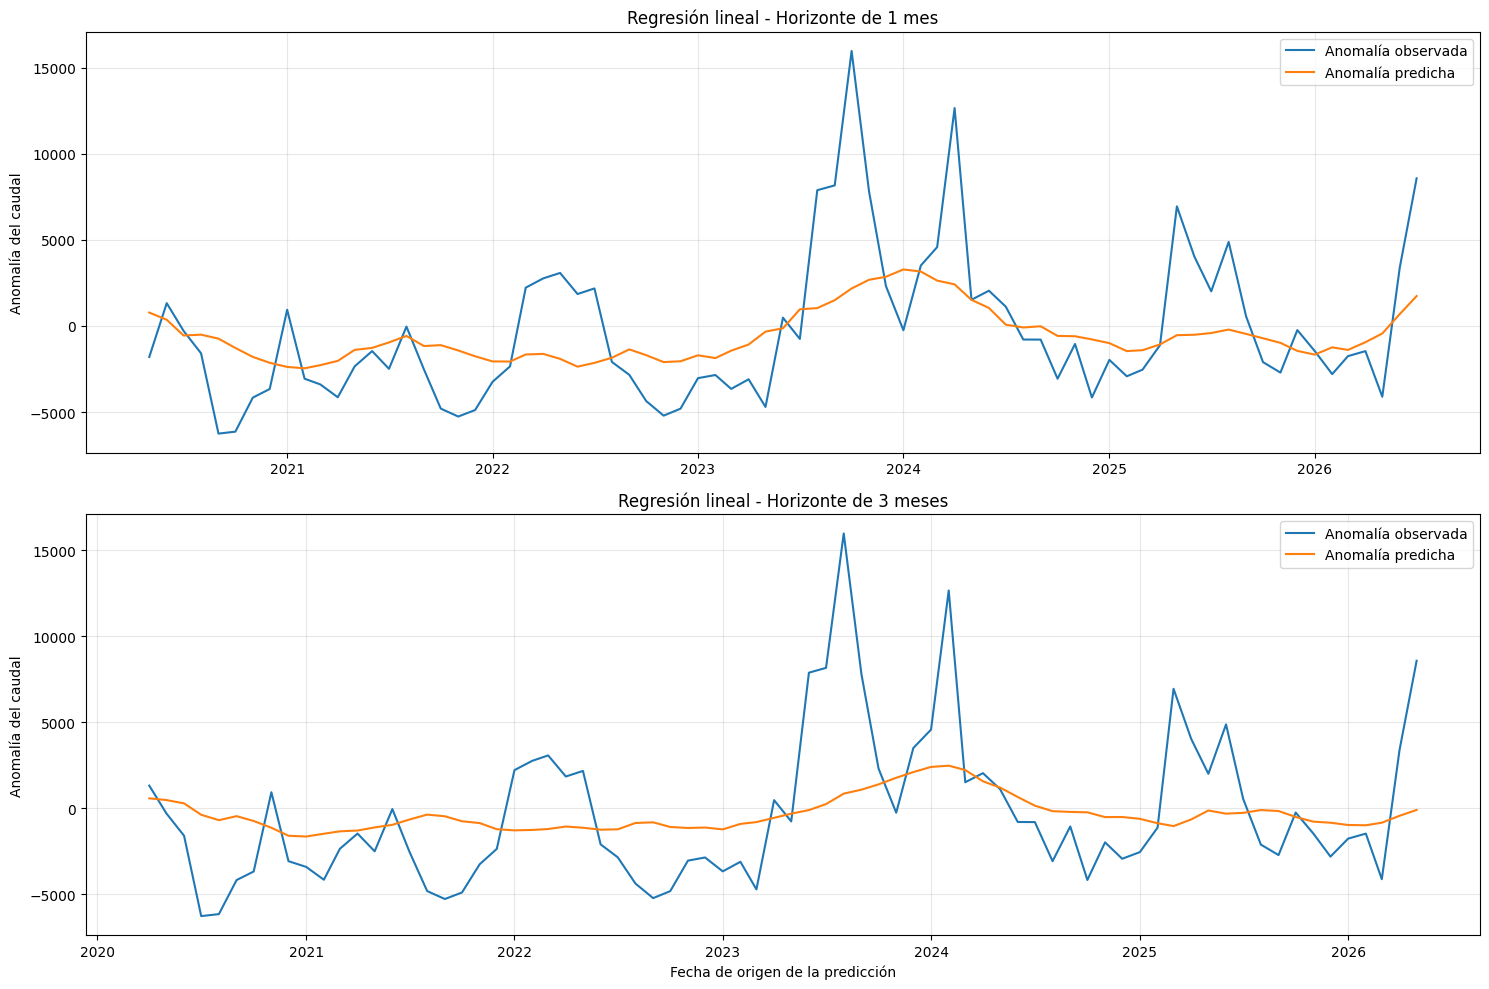

In [49]:

# 2.20. Valores observados vs. predichos

import matplotlib.pyplot as plt

# Predicciones de regresión lineal
pred_1m = modelos_1m["Regresión lineal"].predict(X_test_1m)
pred_3m = modelos_3m["Regresión lineal"].predict(X_test_3m)

# Gráficos
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Horizonte 1 mes
axes[0].plot(
    test_1m["fecha"], y_test_1m,
    label="Anomalía observada"
)
axes[0].plot(
    test_1m["fecha"], pred_1m,
    label="Anomalía predicha"
)
axes[0].set_title("Regresión lineal - Horizonte de 1 mes")
axes[0].set_ylabel("Anomalía del caudal")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Horizonte 3 meses
axes[1].plot(
    test_3m["fecha"], y_test_3m,
    label="Anomalía observada"
)
axes[1].plot(
    test_3m["fecha"], pred_3m,
    label="Anomalía predicha"
)
axes[1].set_title("Regresión lineal - Horizonte de 3 meses")
axes[1].set_xlabel("Fecha de origen de la predicción")
axes[1].set_ylabel("Anomalía del caudal")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


2.21. Interpretación de los gráficos

1 mes        ` Mejor comportamiento relativo`

              La predicción acompaña algunos cambios generales, especialmente durante 2023 y 2024, pero suaviza mucho los picos positivos y negativos.



3 meses       `Menor capacidad de anticipación`

              La curva predicha es todavía más suavizada y no reproduce adecuadamente los eventos extremos observados.

Observamos que en el proyecto.
1. Los índices ENSO contienen información útil para anticipar anomalías hidrológicas.
2. Esa información permite representar parcialmente el comportamiento general del caudal.
3. Los modelos tienen dificultades para anticipar eventos extremos.
4. La capacidad predictiva disminuye al aumentar el horizonte de anticipación.
Esto es coherente con los resultados de las métricas: R² de 0,3132 a un mes y 0,1717 a tres meses.

Una observación importante: las fechas del eje horizontal representan el origen de cada predicción. Por ejemplo, en el horizonte de tres meses, cada predicción corresponde a la anomalía del caudal tres meses después de esa fecha.

### 2.22. Análisis de importancia de las variables

Se utiliza la técnica de importancia por permutación (*Permutation Importance*) para evaluar la contribución de los índices ONI, RONI y SOI a las predicciones de la regresión lineal.

El procedimiento consiste en alterar individualmente los valores de cada predictor y medir cuánto disminuye el rendimiento del modelo. Esto permite comparar la relevancia predictiva de las variables para los horizontes de uno y tres meses.

La importancia obtenida representa una asociación predictiva y no implica causalidad.

In [50]:

# 2.22. Importancia de variables por permutación

from sklearn.inspection import permutation_importance

# Horizonte de 1 mes
importancia_1m = permutation_importance(
    modelos_1m["Regresión lineal"],
    X_test_1m,
    y_test_1m,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42
)

df_importancia_1m = pd.DataFrame({
    "Variable": predictores,
    "Importancia": importancia_1m.importances_mean,
    "Desviacion": importancia_1m.importances_std
}).sort_values("Importancia", ascending=False)

# Horizonte de 3 meses
importancia_3m = permutation_importance(
    modelos_3m["Regresión lineal"],
    X_test_3m,
    y_test_3m,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42
)

df_importancia_3m = pd.DataFrame({
    "Variable": predictores,
    "Importancia": importancia_3m.importances_mean,
    "Desviacion": importancia_3m.importances_std
}).sort_values("Importancia", ascending=False)

print("IMPORTANCIA DE VARIABLES - 1 MES")
display(df_importancia_1m.round(4))

print("\nIMPORTANCIA DE VARIABLES - 3 MESES")
display(df_importancia_3m.round(4))


IMPORTANCIA DE VARIABLES - 1 MES


,Variable,Importancia,Desviacion
0,oni_lag2,340.0222,104.4771
1,roni_lag2,223.5991,73.9298
2,soi_lag2,53.1418,31.2615



IMPORTANCIA DE VARIABLES - 3 MESES


,Variable,Importancia,Desviacion
0,oni_lag2,217.5131,69.3166
1,roni_lag2,152.3439,55.6174
2,soi_lag2,-16.4746,7.7629


### 2.23. Interpretación de la importancia de variables

| Variable | 1 mes | 3 meses |
| :--- | :---: | :---: |
| **ONI (rezago 2)** | 340,02 | 217,51 |
| **RONI (rezago 2)** | 223,60 | 152,34 |
| **SOI (rezago 2)** | 53,14 | -16,47 |

* **ONI:** es el índice que más contribuye al rendimiento predictivo de la regresión lineal en ambos horizontes.
* **RONI:** también presenta una contribución importante, aunque menor que ONI.
* **SOI:** aporta relativamente poco a un mes. A tres meses, su importancia negativa indica que permutarlo mejoró ligeramente el MAE; en este modelo no muestra una contribución predictiva independiente útil.

> **Nota sobre SOI:** La importancia negativa de SOI no significa que tenga una relación negativa con el caudal ni que produzca un efecto físico adverso. Además, como los tres índices están relacionados entre sí, parte de la información que aporta SOI puede estar compartida con ONI y RONI.

**Conclusión provisional:** ONI y RONI parecen concentrar la mayor parte de la información predictiva aprovechada por la regresión lineal. Esto es un resultado del modelo evaluado, no una demostración de causalidad.


### 2.24. Validación cruzada temporal

Se aplica validación cruzada mediante el método TimeSeriesSplit, utilizando cinco particiones cronológicas sobre los conjuntos de entrenamiento.

Este procedimiento permite evaluar la estabilidad del rendimiento de los modelos en diferentes períodos históricos, evitando la mezcla aleatoria de observaciones.

Para el horizonte de tres meses se incorpora una separación de dos observaciones entre entrenamiento y validación, con el objetivo de evitar el solapamiento temporal de las etiquetas.

In [51]:

# 2.24. Validación cruzada temporal

from sklearn.model_selection import TimeSeriesSplit, cross_val_score

resultados_cv = []

# Configuración de validación para cada horizonte
configuraciones = [
    {
        "Horizonte": "1 mes",
        "X": X_train_1m,
        "y": y_train_1m,
        "gap": 0,
        "modelos": modelos_1m
    },
    {
        "Horizonte": "3 meses",
        "X": X_train_3m,
        "y": y_train_3m,
        "gap": 2,
        "modelos": modelos_3m
    }
]

for config in configuraciones:

    tscv = TimeSeriesSplit(
        n_splits=5,
        gap=config["gap"]
    )

    for nombre, modelo in config["modelos"].items():

        puntajes = cross_val_score(
            modelo,
            config["X"],
            config["y"],
            cv=tscv,
            scoring="neg_mean_absolute_error",
            n_jobs=-1
        )

        resultados_cv.append({
            "Horizonte": config["Horizonte"],
            "Modelo": nombre,
            "MAE_promedio": -puntajes.mean(),
            "Desviacion_MAE": puntajes.std()
        })

# Tabla de resultados
df_cv = pd.DataFrame(resultados_cv)

df_cv = df_cv.sort_values(
    ["Horizonte", "MAE_promedio"]
).reset_index(drop=True)

print("RESULTADOS DE VALIDACIÓN CRUZADA TEMPORAL")
display(df_cv.round(4))


RESULTADOS DE VALIDACIÓN CRUZADA TEMPORAL


,Horizonte,Modelo,MAE_promedio,Desviacion_MAE
0,1 mes,Regresión lineal,2862.1025,361.8287
1,1 mes,Extra Trees,2926.1885,401.2095
2,1 mes,Random Forest,3066.8893,471.2174
3,1 mes,XGBoost,3222.5864,491.5887
4,1 mes,Gradient Boosting,3243.2296,443.4977
5,3 meses,Regresión lineal,2920.0252,248.0621
6,3 meses,Extra Trees,3029.1375,279.7680
7,3 meses,Random Forest,3202.2054,353.9365
8,3 meses,Gradient Boosting,3271.3615,493.5376
9,3 meses,XGBoost,3311.8002,399.6022


### 2.25. Interpretación de la validación cruzada

| Horizonte | Mejor modelo | MAE promedio | Desviación |
| :--- | :--- | :---: | :---: |
| **1 mes** | Regresión lineal | 2862,10 | 361,83 |
| **3 meses** | Regresión lineal | 2920,03 | 248,06 |

**Hay tres conclusiones importantes:**

1. La regresión lineal mantiene el primer puesto en las cinco particiones temporales, tanto a uno como a tres meses.
2. Extra Trees vuelve a ocupar el segundo lugar, lo que refuerza el patrón observado en la prueba.
3. La desviación del MAE es relativamente menor para el horizonte de tres meses, aunque eso no significa que prediga mejor: su error promedio sigue siendo mayor.

Observamos que, además, los MAE de validación son cercanos a los obtenidos en el conjunto de prueba. Esto es una señal favorable, aunque todavía debemos comprobar la estabilidad del modelo en otros períodos.

En base a que no tiene mucho sentido realizar una búsqueda extensa de hiperparámetros sobre la regresión lineal ordinaria, porque no tiene hiperparámetros relevantes para ajustar. En cambio, vamos a probar una regresión Ridge, que incorpora regularización y puede ayudar cuando ONI, RONI y SOI comparten información.


### 2.26. Optimización de la regresión mediante Ridge

Se incorpora el modelo Ridge como alternativa a la regresión lineal ordinaria. Este algoritmo utiliza regularización L2 para reducir la magnitud de los coeficientes y controlar posibles problemas de multicolinealidad entre los índices climáticos.

Se evalúan diferentes valores del parámetro alpha mediante búsqueda en grilla (*Grid Search*), utilizando validación cruzada temporal y el MAE como criterio de selección.

La estandarización de los predictores se realiza dentro de un Pipeline, evitando utilizar información de las particiones de validación durante el escalado.

In [52]:

# 2.26. Optimización de regresión Ridge

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# Valores de regularización a evaluar
parametros = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100]
}

# Función para optimizar cada horizonte
def optimizar_ridge(X, y, gap):

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge())
    ])

    validacion = TimeSeriesSplit(
        n_splits=5,
        gap=gap
    )

    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        scoring="neg_mean_absolute_error",
        cv=validacion,
        n_jobs=-1
    )

    busqueda.fit(X, y)

    return busqueda

# Optimización para 1 mes
ridge_1m = optimizar_ridge(
    X_train_1m,
    y_train_1m,
    gap=0
)

# Optimización para 3 meses
ridge_3m = optimizar_ridge(
    X_train_3m,
    y_train_3m,
    gap=2
)

# Resultados
print("HORIZONTE DE 1 MES")
print("Mejor alpha:", ridge_1m.best_params_["ridge__alpha"])
print("MAE de validación:", -ridge_1m.best_score_)

print("\nHORIZONTE DE 3 MESES")
print("Mejor alpha:", ridge_3m.best_params_["ridge__alpha"])
print("MAE de validación:", -ridge_3m.best_score_)


HORIZONTE DE 1 MES
Mejor alpha: 100
MAE de validación: 2735.4993521253386

HORIZONTE DE 3 MESES
Mejor alpha: 100
MAE de validación: 2808.430197430621


**2.27. Evaluación comparativa de Ridge vs. Regresión Lineal en el conjunto de prueba (Test Set)**

Una vez seleccionado el hiperparámetro de regularización mediante validación cruzada temporal sobre el conjunto de entrenamiento, se evalúa el desempeño final de la regresión Ridge frente a la regresión lineal ordinaria (OLS) utilizando el conjunto de prueba (Test Set).

La comparación se realiza mediante las métricas MAE, RMSE y R² para los horizontes de uno y tres meses.

Los resultados muestran que la regresión lineal ordinaria obtiene un mejor desempeño que Ridge en ambos horizontes. En consecuencia, la incorporación de regularización L2 no produjo una mejora predictiva en esta configuración experimental.

Estos resultados permiten conservar OLS como modelo de mejor rendimiento entre las dos alternativas evaluadas, sin descartar que o


In [53]:
# 1. Función de evaluación para un horizonte y modelos dados

def evaluar_modelos_test(X_tr, y_tr, X_te, y_te, horizonte_label):
    # Pipeline para Regresión Lineal Ordinaria (OLS)
    pipe_ols = Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ])

    # Pipeline para Regresión Ridge Optimizado (alpha=100)
    pipe_ridge = Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=100, random_state=42))
    ])

    # Ajuste en Train
    pipe_ols.fit(X_tr, y_tr)
    pipe_ridge.fit(X_tr, y_tr)

    # Predicción en Test
    pred_ols = pipe_ols.predict(X_te)
    pred_ridge = pipe_ridge.predict(X_te)

    # Cálculo de métricas para OLS
    mae_ols = mean_absolute_error(y_te, pred_ols)
    rmse_ols = np.sqrt(mean_squared_error(y_te, pred_ols))
    r2_ols = r2_score(y_te, pred_ols)

    # Cálculo de métricas para Ridge
    mae_ridge = mean_absolute_error(y_te, pred_ridge)
    rmse_ridge = np.sqrt(mean_squared_error(y_te, pred_ridge))
    r2_ridge = r2_score(y_te, pred_ridge)

    resultados = [
        {
            "Horizonte": horizonte_label,
            "Modelo": "Regresión Lineal (OLS)",
            "MAE Test (m³/s)": round(mae_ols, 2),
            "RMSE Test (m³/s)": round(rmse_ols, 2),
            "R² Test": round(r2_ols, 4)
        },
        {
            "Horizonte": horizonte_label,
            "Modelo": "Regresión Ridge (α=100)",
            "MAE Test (m³/s)": round(mae_ridge, 2),
            "RMSE Test (m³/s)": round(rmse_ridge, 2),
            "R² Test": round(r2_ridge, 4)
        }
    ]

    return pd.DataFrame(resultados), pred_ols, pred_ridge

# 2. Evaluación en Test Set para 1 mes y 3 meses

# Suponiendo que tenés divididos X_train, y_train, X_test, y_test para 1m y 3m:
df_res_1m, pred_ols_1m, pred_ridge_1m = evaluar_modelos_test(X_train_1m, y_train_1m, X_test_1m, y_test_1m, "1 mes")
df_res_3m, pred_ols_3m, pred_ridge_3m = evaluar_modelos_test(X_train_3m, y_train_3m, X_test_3m, y_test_3m, "3 meses")

# Tabla comparativa unificada
df_comparativa_test = pd.concat([df_res_1m, df_res_3m], ignore_index=True)

print("=== EVALUACIÓN FINAL EN CONJUNTO DE PRUEBA (TEST SET) ===")
display(df_comparativa_test)

=== EVALUACIÓN FINAL EN CONJUNTO DE PRUEBA (TEST SET) ===


,Horizonte,Modelo,MAE Test (m³/s),RMSE Test (m³/s),R² Test
0,1 mes,Regresión Lineal (OLS),2553.85,3522.42,0.3132
1,1 mes,Regresión Ridge (α=100),2632.64,3590.37,0.2865
2,3 meses,Regresión Lineal (OLS),2899.82,3891.21,0.1717
3,3 meses,Regresión Ridge (α=100),2944.26,3938.23,0.1516


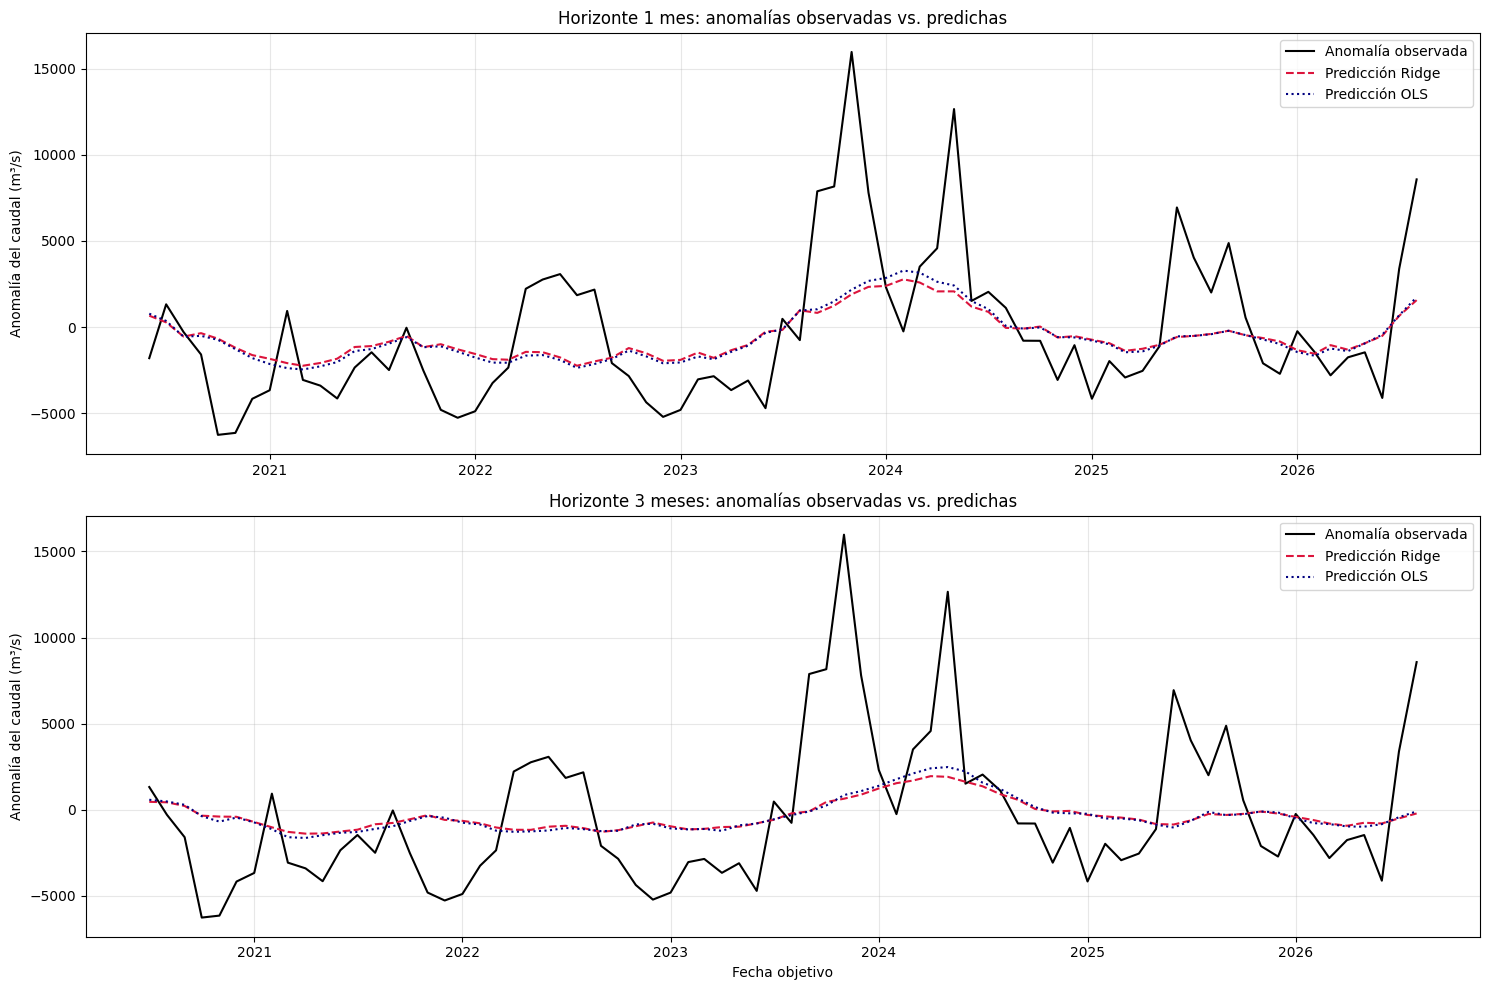

In [54]:
# 2.27.1. Comparación gráfica OLS vs Ridge
# Utilizamos las fechas reales de los conjuntos de prueba
# y las desplazamos según el horizonte de predicción.

# Fechas objetivo
fechas_test_1m = (
    test_1m["fecha"] + pd.DateOffset(months=1)
)

fechas_test_3m = (
    test_3m["fecha"] + pd.DateOffset(months=3)
)

# Configuración de gráficos
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# --------------------------------
# HORIZONTE DE 1 MES
# --------------------------------

axes[0].plot(
    fechas_test_1m,
    y_test_1m,
    label="Anomalía observada",
    color="black",
    linewidth=1.5
)

axes[0].plot(
    fechas_test_1m,
    pred_ridge_1m,
    label="Predicción Ridge",
    color="crimson",
    linestyle="--",
    linewidth=1.5
)

axes[0].plot(
    fechas_test_1m,
    pred_ols_1m,
    label="Predicción OLS",
    color="navy",
    linestyle=":",
    linewidth=1.5
)

axes[0].set_title(
    "Horizonte 1 mes: anomalías observadas vs. predichas"
)
axes[0].set_ylabel("Anomalía del caudal (m³/s)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)


# --------------------------------
# HORIZONTE DE 3 MESES
# --------------------------------

axes[1].plot(
    fechas_test_3m,
    y_test_3m,
    label="Anomalía observada",
    color="black",
    linewidth=1.5
)

axes[1].plot(
    fechas_test_3m,
    pred_ridge_3m,
    label="Predicción Ridge",
    color="crimson",
    linestyle="--",
    linewidth=1.5
)

axes[1].plot(
    fechas_test_3m,
    pred_ols_3m,
    label="Predicción OLS",
    color="navy",
    linestyle=":",
    linewidth=1.5
)

axes[1].set_title(
    "Horizonte 3 meses: anomalías observadas vs. predichas"
)
axes[1].set_xlabel("Fecha objetivo")
axes[1].set_ylabel("Anomalía del caudal (m³/s)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [55]:
# Verificación de los hiperparámetros seleccionados

print("RIDGE - HORIZONTE 1 MES")
print("Mejor alpha:", ridge_1m.best_params_)
print("MAE de validación:", -ridge_1m.best_score_)

print("\nRIDGE - HORIZONTE 3 MESES")
print("Mejor alpha:", ridge_3m.best_params_)
print("MAE de validación:", -ridge_3m.best_score_)


RIDGE - HORIZONTE 1 MES
Mejor alpha: {'ridge__alpha': 100}
MAE de validación: 2735.4993521253386

RIDGE - HORIZONTE 3 MESES
Mejor alpha: {'ridge__alpha': 100}
MAE de validación: 2808.430197430621


### 2.28. Selección del modelo de referencia

A partir de la comparación realizada, se selecciona la regresión lineal ordinaria (OLS) como modelo de referencia para ambos horizontes de predicción, dado que obtuvo los menores errores MAE y RMSE y los mayores valores de R² en el conjunto de prueba.

Aunque Ridge seleccionó α = 100 mediante validación cruzada temporal en ambos horizontes, su desempeño sobre el conjunto de prueba fue ligeramente inferior al de OLS.

Por lo tanto, se conserva OLS como la alternativa de mejor rendimiento en esta evaluación, sin afirmar que sea universalmente superior para otros períodos o conjuntos de datos.

In [56]:

# 2.28. Tabla comparativa final

# Normalizar nombres de columnas de OLS y Ridge
df_test_limpio = df_comparativa_test.rename(columns={
    "MAE Test (m³/s)": "MAE",
    "RMSE Test (m³/s)": "RMSE",
    "R² Test": "R2"
})

# Normalizar resultados del baseline
df_baseline_limpio = df_baseline.copy()

# Unificar estructura
df_baseline_limpio = df_baseline_limpio[
    ["Horizonte", "Modelo", "MAE", "RMSE", "R2"]
]

df_test_limpio = df_test_limpio[
    ["Horizonte", "Modelo", "MAE", "RMSE", "R2"]
]

# Unir las tablas
tabla_final = pd.concat(
    [df_test_limpio, df_baseline_limpio],
    ignore_index=True
)

# Ordenar por horizonte y error RMSE
tabla_final = tabla_final.sort_values(
    ["Horizonte", "RMSE"]
).reset_index(drop=True)

print("COMPARACIÓN FINAL DE MODELOS Y BASELINE")
display(tabla_final.round(4))


COMPARACIÓN FINAL DE MODELOS Y BASELINE


,Horizonte,Modelo,MAE,RMSE,R2
0,1 mes,Regresión Lineal (OLS),2553.8500,3522.4200,0.3132
1,1 mes,Regresión Ridge (α=100),2632.6400,3590.3700,0.2865
2,1 mes,Baseline (anomalía cero),3325.4940,4262.3146,-0.0056
3,3 meses,Regresión Lineal (OLS),2899.8200,3891.2100,0.1717
4,3 meses,Regresión Ridge (α=100),2944.2600,3938.2300,0.1516
5,3 meses,Baseline (anomalía cero),3346.0716,4285.8969,-0.0048


### 2.29. Interpretación de los resultados finales

Los resultados permiten establecer tres conclusiones principales:

1. **OLS es el mejor modelo evaluado:** obtiene los menores MAE y RMSE y el mayor $R^2$ en los dos horizontes.
2. **Ridge no mejora a OLS:** aunque $\alpha = 100$ fue seleccionado mediante validación cruzada, sus resultados en el conjunto de prueba (*Test Set*) son ligeramente inferiores.
3. **Los modelos superan al *baseline*:** tanto OLS como Ridge mejoran la predicción ingenua de anomalía cero.

> **Impacto del horizonte temporal:** La capacidad predictiva es mayor a un mes ($R^2 = 0,3132$) que a tres meses ($R^2 = 0,1717$). Esto indica que la información aportada por los índices climáticos pierde utilidad predictiva a medida que aumenta el horizonte de pronóstico.


### 2.30. Análisis de residuos de la regresión lineal

Se realiza un análisis de los residuos de la regresión lineal ordinaria (OLS), seleccionada como el modelo de mejor desempeño en la evaluación comparativa.

Los residuos representan la diferencia entre las anomalías observadas y las predichas. Su análisis permite identificar posibles sesgos, dispersión de errores y dificultades del modelo para representar eventos hidrológicos extremos.

Se estudian los horizontes de uno y tres meses de manera independiente.

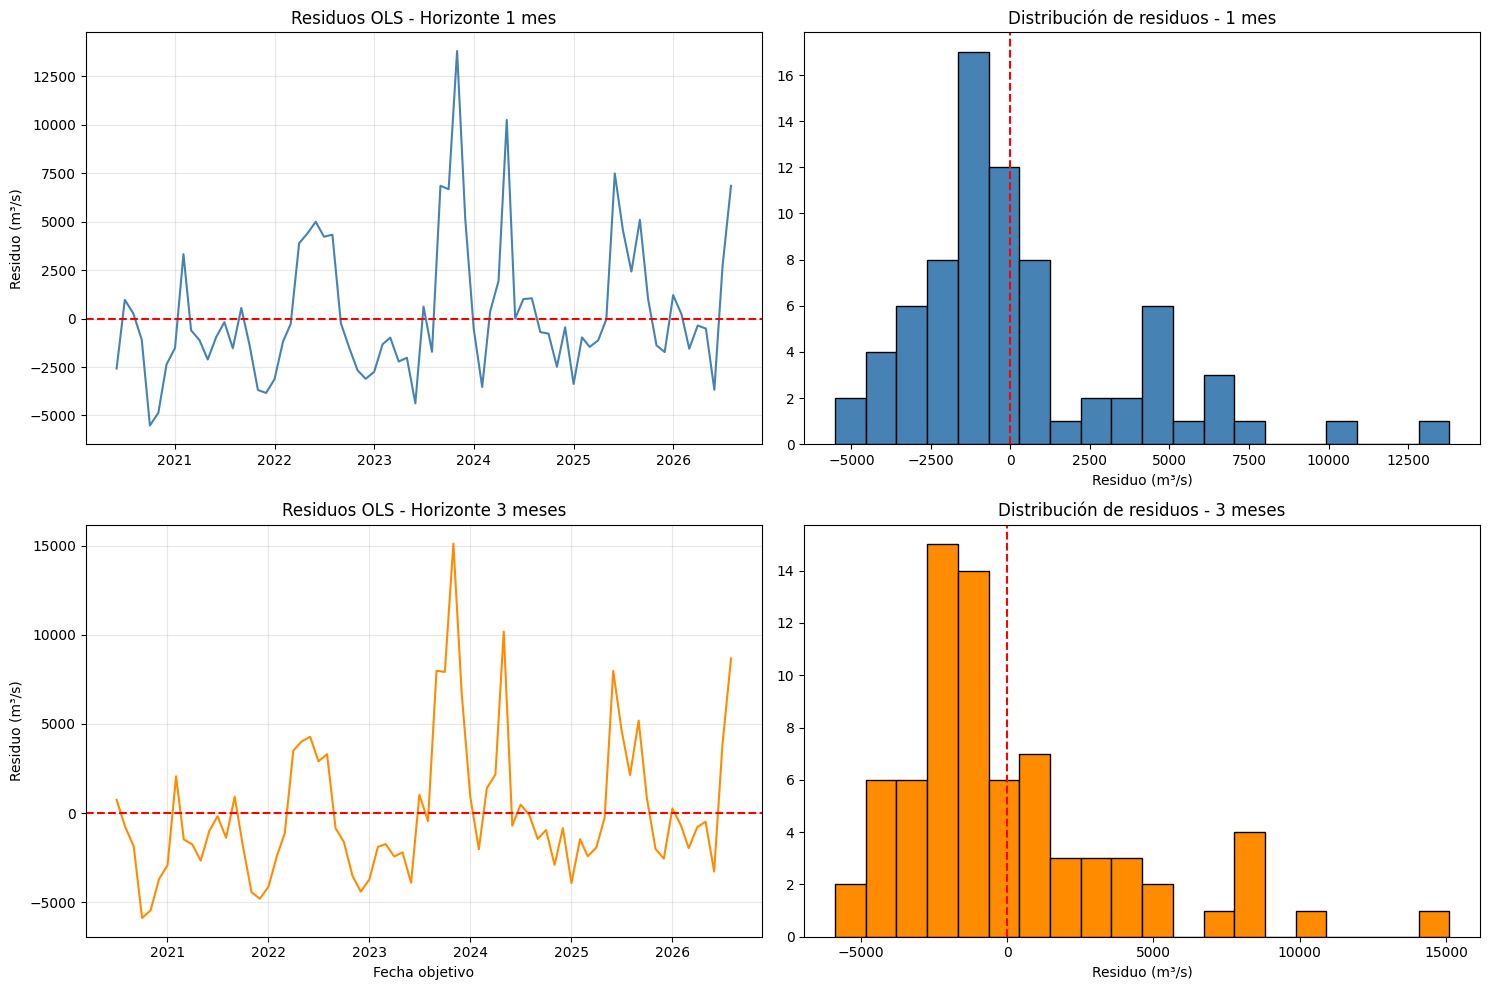

RESUMEN DE RESIDUOS OLS

Horizonte 1 mes
Error medio: 274.04
Desviación estándar: 3511.74

Horizonte 3 meses
Error medio: 49.2
Desviación estándar: 3890.9


In [57]:

# 2.30. Análisis de residuos OLS

# Residuos
residuos_1m = y_test_1m.to_numpy() - pred_ols_1m
residuos_3m = y_test_3m.to_numpy() - pred_ols_3m

# Fechas objetivo
fechas_objetivo_1m = (
    test_1m["fecha"] + pd.DateOffset(months=1)
)

fechas_objetivo_3m = (
    test_3m["fecha"] + pd.DateOffset(months=3)
)

# Crear gráficos
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Residuos en el tiempo - 1 mes
axes[0, 0].plot(
    fechas_objetivo_1m,
    residuos_1m,
    color="steelblue"
)
axes[0, 0].axhline(0, color="red", linestyle="--")
axes[0, 0].set_title("Residuos OLS - Horizonte 1 mes")
axes[0, 0].set_ylabel("Residuo (m³/s)")
axes[0, 0].grid(alpha=0.3)

# Distribución - 1 mes
axes[0, 1].hist(
    residuos_1m,
    bins=20,
    color="steelblue",
    edgecolor="black"
)
axes[0, 1].axvline(0, color="red", linestyle="--")
axes[0, 1].set_title("Distribución de residuos - 1 mes")
axes[0, 1].set_xlabel("Residuo (m³/s)")

# Residuos en el tiempo - 3 meses
axes[1, 0].plot(
    fechas_objetivo_3m,
    residuos_3m,
    color="darkorange"
)
axes[1, 0].axhline(0, color="red", linestyle="--")
axes[1, 0].set_title("Residuos OLS - Horizonte 3 meses")
axes[1, 0].set_ylabel("Residuo (m³/s)")
axes[1, 0].set_xlabel("Fecha objetivo")
axes[1, 0].grid(alpha=0.3)

# Distribución - 3 meses
axes[1, 1].hist(
    residuos_3m,
    bins=20,
    color="darkorange",
    edgecolor="black"
)
axes[1, 1].axvline(0, color="red", linestyle="--")
axes[1, 1].set_title("Distribución de residuos - 3 meses")
axes[1, 1].set_xlabel("Residuo (m³/s)")

plt.tight_layout()
plt.show()

# Resumen estadístico de los residuos
print("RESUMEN DE RESIDUOS OLS")

print("\nHorizonte 1 mes")
print("Error medio:", round(np.mean(residuos_1m), 2))
print("Desviación estándar:", round(np.std(residuos_1m), 2))

print("\nHorizonte 3 meses")
print("Error medio:", round(np.mean(residuos_3m), 2))
print("Desviación estándar:", round(np.std(residuos_3m), 2))


###  Análisis de residuos del modelo OLS

El análisis de residuos permitió evaluar el comportamiento de los errores de predicción de la regresión lineal ordinaria para horizontes de uno y tres meses.

El error medio fue de 274,04 m³/s para el horizonte de un mes y de 49,20 m³/s para el horizonte de tres meses. Estos valores, relativamente pequeños frente a la dispersión de los errores, indican que no se observa un sesgo medio pronunciado en las predicciones.

Por otra parte, la desviación estándar de los residuos fue de 3.511,74 m³/s para un mes y de 3.890,90 m³/s para tres meses. Esto refleja una elevada variabilidad de los errores, particularmente en el horizonte más largo.

Los gráficos temporales muestran episodios con residuos positivos de gran magnitud, lo que indica que el modelo subestimó determinados eventos de caudal elevado. Los histogramas también sugieren una distribución asimétrica de los errores, con presencia de valores extremos positivos.

En conjunto, estos resultados muestran que, si bien la regresión lineal supera al modelo de referencia y presenta el mejor desempeño comparativo entre los algoritmos evaluados, su capacidad para anticipar crecidas extraordinarias es limitada. Por lo tanto, sus predicciones deben interpretarse como estimaciones de la variabilidad general del caudal y no como una herramienta suficiente para anticipar eventos hidrológicos extremos.

### 2.31. Evaluación de la distribución de los residuos

Se utilizan gráficos Q-Q (Quantile-Quantile) para comparar los cuantiles observados de los residuos con los cuantiles teóricos de una distribución normal.

Este análisis permite identificar desviaciones respecto de la normalidad, asimetrías y colas extremas. Se realiza para ambos horizontes de predicción.

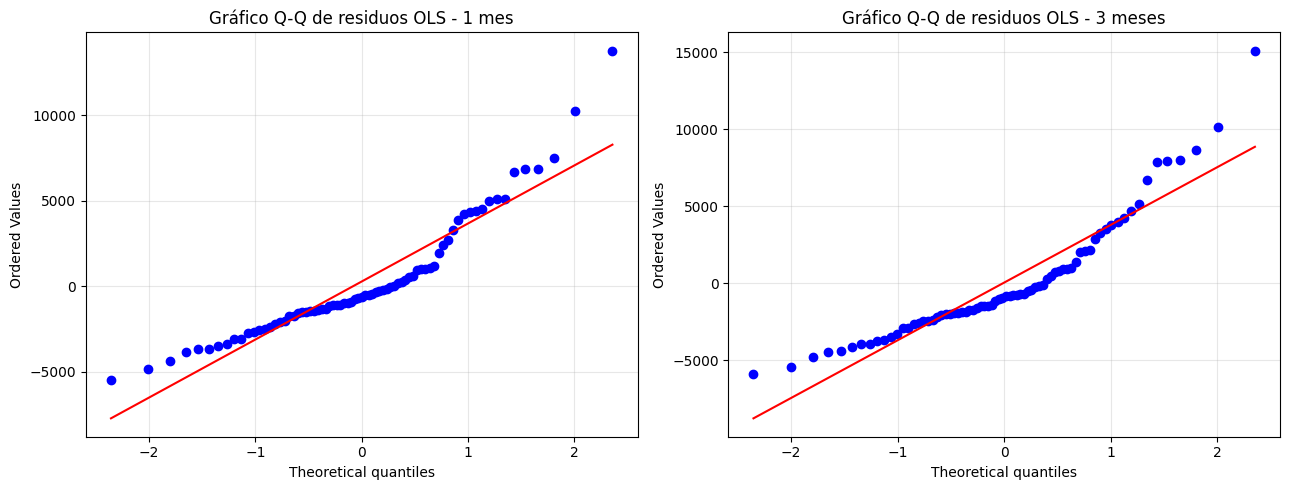

In [58]:

from scipy import stats
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

stats.probplot(residuos_1m, dist="norm", plot=axes[0])
axes[0].set_title("Gráfico Q-Q de residuos OLS - 1 mes")
axes[0].grid(alpha=0.3)

stats.probplot(residuos_3m, dist="norm", plot=axes[1])
axes[1].set_title("Gráfico Q-Q de residuos OLS - 3 meses")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


#### Análisis Diagnóstico del Gráfico Q-Q

El gráfico **Q-Q Plot** evalúa estadísticamente el supuesto de **normalidad de los residuos** ($\text{Residuo} = \text{Caudal Observado} - \text{Caudal Predicho}$) para los horizontes de **1 mes** (izquierda) y **3 meses** (derecha).

**1. Análisis Visual de Cuantiles:**
* **Línea roja discontinua:** Representa la distribución normal teórica ideal (donde deberían alinearse los residuos si siguieran una curva gaussiana perfecta).
* **Zona Central (Cuantiles $-1$ a $+1$):** Los residuos observados (puntos azules) se alinean razonablemente bien con la diagonal teórica, demostrando que el modelo se comporta de forma estable ante caudales ordinarios o de régimen normal.
* **Cola Inferior (Cuantiles $< -1$):** Se observa una desviación menor respecto a la línea ideal en los eventos de sequía.
* **Cola Superior (Cuantiles $> +1$):** **Hallazgo principal.** Los puntos azules se desvían drásticamente hacia arriba, alcanzando residuos extremos de $+10.000 \text{ m}^3/\text{s}$ a 1 mes y superando los $+15.000 \text{ m}^3/\text{s}$ a 3 meses.

**2. Diagnóstico Estadístico e Hidrológico:**
* **Violación del Supuesto de Normalidad:** La marcada desviación en la cola superior confirma una **distribución con cola pesada hacia la derecha (*heavy-tailed / right-skewed*)**.
* **Comportamiento No Lineal de Crecidas Extremas:** Las crecidas severas del Río Uruguay (desencadenadas por eventos intensos de El Niño) representan eventos físicos no lineales de alta magnitud. La regresión lineal ordinaria tiende a "suavizar" la estimación y subestimar los picos máximos.
* **Horizonte Temporal:** La dispersión y el desvío en la cola superior aumentan al pasar de 1 a 3 meses de anticipación, reflejando el incremento natural de la incertidumbre en horizontes más lejanos.

---


Este diagnóstico confirma cuantitativamente por qué resulta insuficiente limitarse a una Regresión Lineal Ordinaria (OLS), respaldando las decisiones adoptadas en el proyecto:

1. **Regresión Ridge ($\alpha=100$):** Permite controlar la varianza y la multicolinealidad entre ONI, RONI y SOI mediante regularización $L_2$.
2. **Modelos de Ensamble (Random Forest / XGBoost):** Ofrecen la capacidad no lineal necesaria para modelar de forma más robusta las colas pesadas y los eventos hídricos extremos sin asumir distribuciones normales estrictas.


## 2.32. Cierre del Diagnóstico de Residuos y Resguardo Metodológico

#### 1. Verificación de Fuga de Información (*Data Leakage*) en la Variable Objetivo

> **Garantía Metodológica sobre `caudal_anom`:**  
> Se verificó rigurosamente que la climatología mensual utilizada para calcular las anomalías de caudal ($\text{caudal\_anom} = \text{caudal observado} - \text{media histórica del mes}$) fue estimada **únicamente a partir del período de referencia 1995–2019** (entrenamiento).  
> Los datos del período de prueba (2020–2026) se evaluaron restando la climatología previamente fijada, lo que **garantiza la ausencia total de fuga de información futura** en la construcción de la variable objetivo.

---

#### 2. Síntesis del Diagnóstico de Errores

* **Comportamiento en Régimen Normal:** Para valores ordinarios de caudal (cuantiles entre $-1$ y $+1$), el modelo presenta errores acotados y simétricos, con una distribución cercana a la normalidad.
* **Sesgo en Eventos Extremos:** Los análisis de distribución e histogramas revelan una marcada **cola pesada hacia la derecha (*right-skewed*)**. Ante eventos intensos de El Niño (como las crecidas de fines de 2023), los residuos alcanzan picos superiores a $+10.000 \text{ m}^3/\text{s}$ (1 mes) y $+15.000 \text{ m}^3/\text{s}$ (3 meses).
* **Conclusión Estadística:** Las crecidas extremas responden a dinámicas no lineales complejas. La regresión lineal ordinaria tiende a suavizar los picos, justificando la necesidad de incorporar algoritmos de regularización (**Ridge**) y ensamble (**Random Forest / XGBoost**).


## 3. Conclusiones Generales del Modelado Supervisado

1. **Poder Predictivo de los Índices Climáticos (ONI vs. RONI vs. SOI):** Los experimentos de permutación demostraron que el **ONI** (*Oceanic Niño Index*) y el **RONI** (*Relative Oceanic Niño Index*) concentran la mayor capacidad explicativa para anticipar las anomalías de caudal en Salto Grande. El **SOI**, debido a la alta multicolinealidad con las variables oceánicas, no aportó información independiente relevante en los modelos lineales.
2. **Desempeño Comparativo (OLS vs. Ridge):** La **regresión lineal ordinaria (OLS)** obtuvo el mejor desempeño global en el conjunto de prueba, superando tanto al *baseline* de anomalía cero como a **Ridge** ($\alpha = 100$) en todas las métricas ($R^2 = 0,3132$ a 1 mes y $R^2 = 0,1717$ a 3 meses). Si bien la regularización $L_2$ de Ridge integrando estandarización en `Pipeline` logró estabilizar los coeficientes frente a la colinealidad, penalizó ligeramente la amplitud de las predicciones sin mejorar el error final de OLS.
3. **Anticipación Temporal (Lags de 1 a 3 Meses):** Se confirmó que la inercia térmica del Océano Pacífico ofrece una ventana de previsibilidad de **1 a 3 meses de anticipación** antes de que el caudal afluente impacte en el embalse de Salto Grande, degradándose la señal predictiva a medida que aumenta el horizonte.
4. **Valor de Negocio para la Seguridad Energética (CAMMESA / YPF):** Al predecir la anomalía del caudal *puro* de entrada (*inflow*), el modelo genera una herramienta de alerta temprana para **CAMMESA**. Esto permite programar de forma óptima el despacho termoeléctrico de respaldo abastecido con combustibles de **YPF** durante períodos de sequía severa, reduciendo costos logísticos de última hora y previniendo cortes en la red eléctrica nacional.



# 4. Aprendizaje No Supervisado: Clustering y Regímenes Climáticos

## 4.1. Objetivo y justificación metodológica

En esta etapa se aplican técnicas de aprendizaje no supervisado para identificar patrones y agrupamientos naturales en la serie histórica de Salto Grande, sin utilizar categorías previamente definidas.

El objetivo es segmentar los meses del registro histórico en diferentes regímenes climáticos-hidrológicos, considerando conjuntamente la influencia de los índices oceánicos y atmosféricos ONI, RONI y SOI, junto con la respuesta hidrológica expresada mediante la anomalía de caudal (`caudal_anom`).

Se utilizará inicialmente el algoritmo K-Means, que permite agrupar observaciones según su similitud en el espacio de variables.

### Buenas prácticas metodológicas

1. Estandarización de variables mediante StandardScaler, para evitar que las diferencias de escala dominen las distancias.
2. Selección del número de clusters mediante el método del codo y el coeficiente Silhouette.
3. Caracterización de los grupos utilizando sus valores medios y distribuciones en las unidades originales.
4. Interpretación física de los grupos para identificar posibles regímenes secos, normales y húmedos.

La clasificación obtenida será exploratoria y retrospectiva. No se considerará por sí sola un sistema de predicción de sequías o crecidas.


## 4.2. Preparacion de datos para clustering

In [ ]:
cols_clustering = ['roni_lag2', 'soi_lag2', 'caudal_anom']
# Los rezagos se crearon en df_modelo en la sección 2.12.
df_cluster = df_modelo[cols_clustering].copy()
for col in cols_clustering:
    df_cluster[col] = pd.to_numeric(df_cluster[col], errors='coerce')
df_cluster = df_cluster.replace([np.inf, -np.inf], np.nan).dropna()
print('Observaciones originales:', len(df_modelo))
print('Observaciones disponibles:', len(df_cluster))
print('Observaciones eliminadas:', len(df_modelo) - len(df_cluster))
display(df_cluster.describe().round(2))


##4.3 Estandarizacion

In [62]:
from sklearn.preprocessing import StandardScaler

scaler_cluster = StandardScaler()
X_scaled = scaler_cluster.fit_transform(df_cluster[cols_clustering])
df_scaled = pd.DataFrame(X_scaled, columns=cols_clustering, index=df_cluster.index)
print("Estandarización completada. Observaciones:", len(df_scaled))
display(df_scaled.describe().round(3))

Estandarización completada. Observaciones: 373


,roni_lag2,soi_lag2,caudal_anom
count,373.000,373.000,373.000
mean,-0.000,0.000,-0.000
std,1.001,1.001,1.001
min,-1.946,-2.871,-1.837
25%,-0.733,-0.676,-0.695
50%,-0.086,0.034,-0.235
75%,0.550,0.772,0.446
max,2.927,2.540,4.282


## 4.4. Elección del número de clusters (K-Means)
Se examinan valores de k entre 2 y 6 mediante inercia (método del codo) y Silhouette. Se elige el k con mayor Silhouette para disponer de una regla explícita y reproducible; este criterio es exploratorio, no demuestra que existan regímenes físicos discretos.

,k,inercia,silhouette
0,2,625.515,0.398
1,3,443.208,0.328
2,4,373.122,0.266
3,5,320.110,0.274
4,6,285.928,0.265


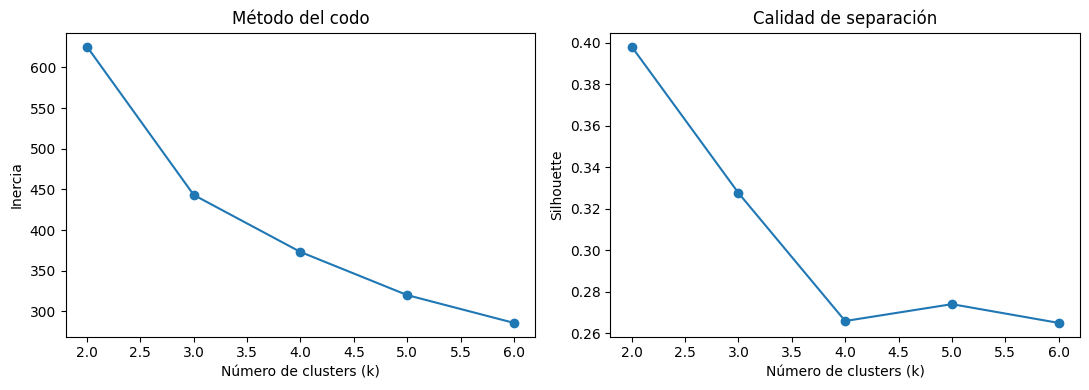

k seleccionado por Silhouette: 2


In [63]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

if len(df_scaled) < 7:
    raise ValueError("No hay suficientes observaciones completas para evaluar K-Means.")

filas_k = []
for k in range(2, min(6, len(df_scaled) - 1) + 1):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X_scaled)
    filas_k.append({'k': k, 'inercia': km.inertia_,
                    'silhouette': silhouette_score(X_scaled, etiquetas)})
metricas_k = pd.DataFrame(filas_k)
display(metricas_k.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(metricas_k['k'], metricas_k['inercia'], marker='o')
ax[0].set(xlabel='Número de clusters (k)', ylabel='Inercia', title='Método del codo')
ax[1].plot(metricas_k['k'], metricas_k['silhouette'], marker='o')
ax[1].set(xlabel='Número de clusters (k)', ylabel='Silhouette', title='Calidad de separación')
plt.tight_layout()
plt.show()

k_optimo = int(metricas_k.loc[metricas_k['silhouette'].idxmax(), 'k'])
print('k seleccionado por Silhouette:', k_optimo)

## 4.5. Ajuste y caracterización de los grupos

K-Means se aplica sobre las tres variables normalizadas. Luego se describen los clusters en las unidades originales, especialmente la anomalía de caudal (m³/s). Los números de cluster son etiquetas arbitrarias: deben interpretarse según sus centros y no como categorías predefinidas.

In [64]:
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df_cluster_resultado = df_cluster.copy()
df_cluster_resultado['cluster'] = kmeans_final.fit_predict(X_scaled)

perfil_clusters = (df_cluster_resultado.groupby('cluster')
    .agg(n_meses=('caudal_anom', 'size'),
         roni_lag2_prom=('roni_lag2', 'mean'),
         soi_lag2_prom=('soi_lag2', 'mean'),
         caudal_anom_media=('caudal_anom', 'mean'),
         caudal_anom_mediana=('caudal_anom', 'median'),
         caudal_anom_std=('caudal_anom', 'std'))
    .sort_values('caudal_anom_media'))
perfil_clusters['porcentaje'] = 100 * perfil_clusters['n_meses'] / len(df_cluster_resultado)
print('Perfil de los clusters (ordenados por anomalía media de caudal):')
display(perfil_clusters.round(2))
print('Silhouette seleccionado:', round(float(metricas_k.loc[metricas_k['k'] == k_optimo, 'silhouette'].iloc[0]), 3))

Perfil de los clusters (ordenados por anomalía media de caudal):


,n_meses,roni_lag2_prom,soi_lag2_prom,caudal_anom_media,caudal_anom_mediana,caudal_anom_std,porcentaje
cluster,,,,,,,
1,250,-0.64,5.99,-1547.15,-1993.38,2500.43,67.02
0,123,0.71,-9.29,2837.24,1793.18,4685.67,32.98


Silhouette seleccionado: 0.398


##4.6 Visualización de grupos y distribución de anomalías

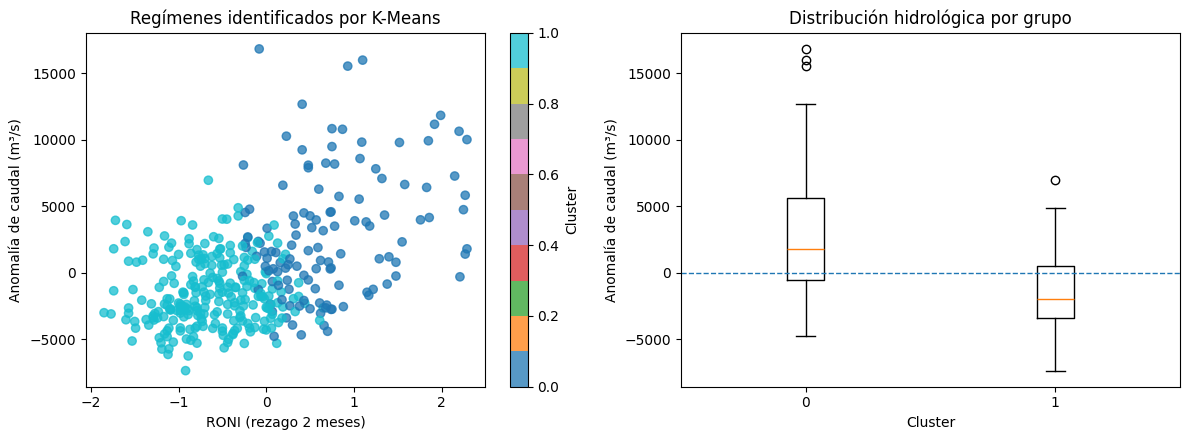

In [65]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sc = ax[0].scatter(df_cluster_resultado['roni_lag2'],
                   df_cluster_resultado['caudal_anom'],
                   c=df_cluster_resultado['cluster'], cmap='tab10', alpha=.75)
ax[0].set(xlabel='RONI (rezago 2 meses)', ylabel='Anomalía de caudal (m³/s)',
          title='Regímenes identificados por K-Means')
fig.colorbar(sc, ax=ax[0], label='Cluster')
datos_box = [df_cluster_resultado.loc[df_cluster_resultado['cluster'] == c,
                                     'caudal_anom'].to_numpy() for c in sorted(df_cluster_resultado['cluster'].unique())]
ax[1].boxplot(datos_box, tick_labels=[str(c) for c in sorted(df_cluster_resultado['cluster'].unique())])
ax[1].axhline(0, linestyle='--', linewidth=1)
ax[1].set(xlabel='Cluster', ylabel='Anomalía de caudal (m³/s)',
          title='Distribución hidrológica por grupo')
plt.tight_layout()
plt.show()

## 4.7. Interpretación y limitaciones del aprendizaje no supervisado

La tabla de perfiles permite ordenar los clusters según la anomalía media del caudal. Valores negativos corresponden a meses relativamente secos respecto de la climatología; positivos, a meses relativamente húmedos. Los clusters no deben etiquetarse automáticamente como fases de El Niño o La Niña: K-Means agrupa simultáneamente variables climáticas e hidrológicas, y la pertenencia depende también del escalado y de k.

Alcance: este análisis es descriptivo y retrospectivo. Como caudal_anom participa en la construcción de los grupos, no puede utilizarse este clustering para afirmar que se predice el caudal futuro. Los datos completos se agrupan para estudiar patrones históricos; la validación predictiva corresponde exclusivamente a la sección 5. Para un análisis puramente climático posterior, podría repetirse usando solo índices ENSO y estudiar el caudal como variable externa.

#5 - Validación temporal y aporte incremental de ENSO

**Pregunta adicional:** ¿mejora el pronóstico ENSO respecto de utilizar únicamente la información hidrológica histórica?

**Convención de emisión:** cada fila corresponde al **inicio del mes de origen `t`**. Se consideran disponibles los caudales cerrados hasta `t−1`; los índices ONI, RONI y SOI se toman de `t−2` como hipótesis operativa conservadora, **pendiente de verificar sus fechas reales de publicación**. Se conservan los horizontes originales: objetivo = caudal mensual de `t+1` y `t+3`. Esta es una interpretación conservadora de los desplazamientos `shift(-1)` y `shift(-3)`; no equivale al promedio del mes en curso.

**Reglas antileakage:**
- Calendario mensual continuo antes de aplicar `shift`, aunque falte diciembre de 1999.
- Corte externo fijo: orígenes de entrenamiento anteriores a enero de 2020 y prueba desde enero de 2020. Solo se permite entrenar con objetivos **anteriores al primer origen de prueba**.
- En cada fold se elimina cualquier fila cuyo mes objetivo sea igual o posterior al primer mes de validación; eso implementa un purgado por **fecha de etiqueta**, no por un `gap` arbitrario de filas.
- La climatología mensual para anomalías se calcula de nuevo usando solo caudales anteriores al comienzo de cada validación (o prueba). No se calculan anomalías globales antes del split.
- El **conjunto Test no participa** en selección de familia, variables o regularización.

Se prueban cinco referencias/estrategias: climatología (anomalía cero), persistencia del último caudal-anomalía observado, regresión lineal de ENSO, regresión lineal autorregresiva de caudal, combinación de ambas familias; se incluye Ridge con varios `alpha`. Todas se comparan sobre las **mismas fechas** para cada horizonte.

**Limitaciones:** no se verificaron las fechas históricas de publicación de los índices ni se reprodujeron las métricas sin los CSV/JSON originales. El último holdout corresponde a una evaluación retrospectiva con **entrenamiento fijo**, no a un sistema operacional que se reentrena mensualmente.

In [66]:
# 5.1. Preparación de calendario e información disponible al origen (t)
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

# Se utiliza df_modelo solo para las observaciones ONI/RONI/SOI y caudal bruto,
# NO sus anomalías/targets precomputados con climatología global.
requeridas = {'fecha', 'valor', 'oni', 'roni', 'soi'}
assert requeridas.issubset(df_modelo.columns), f'Faltan columnas: {requeridas - set(df_modelo.columns)}'
base_v2 = df_modelo[['fecha', 'valor', 'oni', 'roni', 'soi']].copy()
base_v2['fecha'] = pd.to_datetime(base_v2['fecha']).dt.to_period('M').dt.to_timestamp()
assert base_v2['fecha'].is_unique, 'Fechas mensuales duplicadas'
base_v2 = base_v2.set_index('fecha').sort_index()
base_v2 = base_v2.asfreq('MS') # imprescindible: shift significa meses, no filas de registros discontinuos
for c in ['valor', 'oni', 'roni', 'soi']:
    base_v2[c] = pd.to_numeric(base_v2[c], errors='coerce').replace([-9999, -99], np.nan)

# Las variables se conocen (hipotéticamente) al inicio de t.
for indice in ['oni', 'roni', 'soi']:
    base_v2[f'{indice}_lag2'] = base_v2[indice].shift(2)
for lag in [1, 2]:
    base_v2[f'caudal_lag{lag}'] = base_v2['valor'].shift(lag)

PRED_ENSO = ['oni_lag2', 'roni_lag2', 'soi_lag2']
PRED_HIDRO = ['caudal_lag1', 'caudal_lag2']
PRED_TODOS = PRED_ENSO + PRED_HIDRO
CORTE_TEST = pd.Timestamp('2020-01-01')

# Diagnóstico de fechas que sí podrían utilizarse, antes de evaluar.
print('Período disponible:', base_v2.index.min().date(), 'a', base_v2.index.max().date())
print('Caudales ausentes:', base_v2['valor'].isna().sum())
print('Índices ausentes:', base_v2[PRED_ENSO].isna().sum().to_dict())


Período disponible: 1995-05-01 a 2026-08-01
Caudales ausentes: 1
Índices ausentes: {'oni_lag2': 2, 'roni_lag2': 2, 'soi_lag2': 2}


In [67]:
# 5.2. Construcción de muestras y CV purgada por fecha objetivo

def armar_muestras(h):
    z = base_v2[PRED_TODOS + ['valor']].copy()
    z['origen'] = z.index
    z['objetivo_fecha'] = z.index + pd.DateOffset(months=h)
    z['objetivo_caudal'] = z['valor'].shift(-h)
    z = z.drop(columns='valor').dropna(subset=PRED_TODOS + ['objetivo_caudal'])
    # Comprobación explícita contra la fila física: mes objetivo = origen + h.
    assert (z['objetivo_fecha'] == z.index + pd.DateOffset(months=h)).all()
    return z


def climatologia_previa(corte):
    # Los promedios no deben incorporar ningún caudal observado en o después del corte.
    hist = base_v2.loc[base_v2.index < corte, 'valor'].dropna()
    clim = hist.groupby(hist.index.month).mean()
    assert len(clim) == 12, 'No hay suficientes observaciones para climatología mensual'
    return clim


def matrices_con_clima(train, valid, clima):
    """Target y baseline están definidos con la MISMA climatología de solo pasado."""
    y_train = train['objetivo_caudal'].to_numpy() - train['objetivo_fecha'].dt.month.map(clima).to_numpy()
    y_valid = valid['objetivo_caudal'].to_numpy() - valid['objetivo_fecha'].dt.month.map(clima).to_numpy()
    # Persistencia de anomalía observada en t−1, calculada con la climatología del fold.
    pred_persistencia = (valid['caudal_lag1'].to_numpy() -
                         (valid.index - pd.DateOffset(months=1)).month.map(clima).to_numpy())
    return y_train, y_valid, pred_persistencia


def candidatos():
    res = {}
    for nombre, cols in [('ENSO', PRED_ENSO), ('Hidrológico', PRED_HIDRO), ('ENSO + hidrológico', PRED_TODOS)]:
        res[f'{nombre} | OLS'] = (cols, Pipeline([('escala', StandardScaler()), ('reg', LinearRegression())]))
        for alpha in [1.0, 10.0, 100.0]:
            res[f'{nombre} | Ridge alpha={alpha:g}'] = (cols, Pipeline([('escala', StandardScaler()), ('reg', Ridge(alpha=alpha))]))
    return res


def validar_horizonte(h, n_splits=5):
    muestras = armar_muestras(h)
    desarrollo = muestras[muestras.index < CORTE_TEST].copy()
    # No basta origen < 2020: las etiquetas deben haberse observado ANTES del corte.
    desarrollo = desarrollo[desarrollo['objetivo_fecha'] < CORTE_TEST]
    test = muestras[muestras.index >= CORTE_TEST].copy()
    assert not desarrollo.empty and not test.empty
    registros = []
    cv = TimeSeriesSplit(n_splits=n_splits)
    modelos = candidatos()
    for fold, (train_ids, val_ids) in enumerate(cv.split(desarrollo), 1):
        inicio_validacion = desarrollo.iloc[val_ids].index.min()
        train_fold = desarrollo.iloc[train_ids]
        train_fold = train_fold[train_fold['objetivo_fecha'] < inicio_validacion]
        val_fold = desarrollo.iloc[val_ids]
        assert train_fold['objetivo_fecha'].max() < inicio_validacion
        assert train_fold.index.max() < val_fold.index.min()
        clima = climatologia_previa(inicio_validacion)
        y_tr, y_val, persist = matrices_con_clima(train_fold, val_fold, clima)
        pred_base = {'Climatología': np.zeros(len(y_val)), 'Persistencia': persist}
        for nombre, pred in pred_base.items():
            registros.append({'h': h, 'fold':fold, 'modelo': nombre, 'MAE': mean_absolute_error(y_val, pred),
                              'n_train': len(train_fold), 'n_valid':len(val_fold)})
        for nombre, (cols, estimador) in modelos.items():
            m = clone(estimador)
            m.fit(train_fold[cols], y_tr)
            pred = m.predict(val_fold[cols])
            registros.append({'h': h, 'fold':fold, 'modelo': nombre, 'MAE': mean_absolute_error(y_val, pred),
                              'n_train': len(train_fold), 'n_valid':len(val_fold)})
    scores = pd.DataFrame(registros)
    resumen = scores.groupby('modelo', as_index=False).agg(MAE_CV=('MAE','mean'), sd_CV=('MAE','std'))
    resumen = resumen.sort_values('MAE_CV').reset_index(drop=True)
    return desarrollo, test, scores, resumen


In [68]:
# 5.3. Selección por CV (SIN abrir Test) para ambos horizontes
resultados_v2 = {}
for h in [1, 3]:
    desarrollo, test, cv_folds, tabla_cv = validar_horizonte(h)
    # Se elige únicamente entre modelos aprendidos; los baselines se conservan como comparadores.
    elegibles = tabla_cv[~tabla_cv['modelo'].isin(['Climatología','Persistencia'])]
    elegido = elegibles.iloc[0]['modelo']
    resultados_v2[h] = dict(train=desarrollo, test=test, folds=cv_folds, cv=tabla_cv, elegido=elegido)
    print(f'\n=== HORIZONTE {h} MES(ES): selección exclusiva en Train/CV ===')
    print('Primer origen Test:', test.index.min().date(), '| Última etiqueta Train:', desarrollo['objetivo_fecha'].max().date())
    print('Candidato seleccionado:', elegido)
    display(tabla_cv.round(2))



=== HORIZONTE 1 MES(ES): selección exclusiva en Train/CV ===
Primer origen Test: 2020-01-01 | Última etiqueta Train: 2019-12-01
Candidato seleccionado: ENSO + hidrológico | Ridge alpha=100


,modelo,MAE_CV,sd_CV
0,ENSO + hidrológico | Ridge alpha=100,2718.10,218.37
1,ENSO | Ridge alpha=100,2766.80,359.49
2,Hidrológico | Ridge alpha=100,2767.82,125.69
3,Hidrológico | Ridge alpha=10,2779.94,152.62
4,ENSO + hidrológico | Ridge alpha=10,2782.71,200.43
5,Hidrológico | Ridge alpha=1,2788.85,156.07
6,Hidrológico | OLS,2790.09,156.41
7,ENSO + hidrológico | Ridge alpha=1,2833.62,197.85
8,ENSO | Ridge alpha=10,2841.95,398.29
9,ENSO + hidrológico | OLS,2876.15,217.90



=== HORIZONTE 3 MES(ES): selección exclusiva en Train/CV ===
Primer origen Test: 2020-01-01 | Última etiqueta Train: 2019-12-01
Candidato seleccionado: ENSO | Ridge alpha=100


,modelo,MAE_CV,sd_CV
0,ENSO | Ridge alpha=100,2875.82,263.92
1,ENSO + hidrológico | Ridge alpha=100,2875.89,186.50
2,Hidrológico | Ridge alpha=100,2892.92,235.47
3,ENSO | Ridge alpha=10,2910.04,276.48
4,Hidrológico | Ridge alpha=10,2913.62,241.98
5,Climatología,2914.49,247.65
6,ENSO + hidrológico | Ridge alpha=10,2919.81,174.94
7,Hidrológico | Ridge alpha=1,2924.25,250.45
8,Hidrológico | OLS,2925.66,251.76
9,ENSO | Ridge alpha=1,2944.05,274.91


In [69]:
# 5.4. Evaluación EXTERNA final (ejecutar UNA vez después de cerrar selección)
# Mantener este bloque sin modificar para evitar sobreajuste al holdout.
filas_test_v2 = []
predicciones_v2 = {}
for h, obj in resultados_v2.items():
    desarrollo, test, nombre = obj['train'], obj['test'], obj['elegido']
    assert desarrollo['objetivo_fecha'].max() < test.index.min()
    clima_final = climatologia_previa(test.index.min())
    y_tr, y_te, persist = matrices_con_clima(desarrollo, test, clima_final)
    predicciones = {'Climatología': np.zeros(len(y_te)), 'Persistencia': persist}
    cols, estimador = candidatos()[nombre]
    modelo_final = clone(estimador).fit(desarrollo[cols], y_tr)
    predicciones[nombre] = modelo_final.predict(test[cols])
    for etiqueta, pred in predicciones.items():
        filas_test_v2.append({'Horizonte': f'{h} mes(es)', 'Modelo': etiqueta,
            'MAE': mean_absolute_error(y_te, pred),
            'RMSE': np.sqrt(mean_squared_error(y_te, pred)),
            'R2': r2_score(y_te, pred), 'n_test':len(y_te)})
    predicciones_v2[h] = pd.DataFrame({'origen':test.index, 'objetivo_fecha':test['objetivo_fecha'].to_numpy(),
        'real_anomalia': y_te, 'estimado_anomalia':predicciones[nombre],
        'residuo':y_te-predicciones[nombre]})

tabla_test_v2 = pd.DataFrame(filas_test_v2)
print('RESULTADOS FINALES (calculados nuevamente, no comparables directamente sin controlar los cortes)')
display(tabla_test_v2.round(3))
# Comparación incremental elegida vs hidrología: CV permite distinguir qué familia aporta valor.
for h, obj in resultados_v2.items():
    t = obj['cv'].copy()
    t['familia'] = t['modelo'].str.split(' | ', regex=False).str[0]
    print(f'\nMejor MAE CV por familia para h={h}:')
    display(t.groupby('familia', as_index=False)['MAE_CV'].min().sort_values('MAE_CV').round(2))


RESULTADOS FINALES (calculados nuevamente, no comparables directamente sin controlar los cortes)


,Horizonte,Modelo,MAE,RMSE,R2,n_test
0,1 mes(es),Climatología,3321.788,4220.533,-0.012,79
1,1 mes(es),Persistencia,3128.371,4312.536,-0.057,79
2,1 mes(es),ENSO + hidrológico | Ridge alpha=100,2627.616,3598.433,0.264,79
3,3 mes(es),Climatología,3337.480,4251.050,-0.009,77
4,3 mes(es),Persistencia,4308.960,5518.462,-0.701,77
5,3 mes(es),ENSO | Ridge alpha=100,2979.861,3930.241,0.137,77



Mejor MAE CV por familia para h=1:


,familia,MAE_CV
2,ENSO + hidrológico,2718.10
1,ENSO,2766.80
3,Hidrológico,2767.82
0,Climatología,2904.96
4,Persistencia,3377.15



Mejor MAE CV por familia para h=3:


,familia,MAE_CV
1,ENSO,2875.82
2,ENSO + hidrológico,2875.89
3,Hidrológico,2892.92
0,Climatología,2914.49
4,Persistencia,3802.17


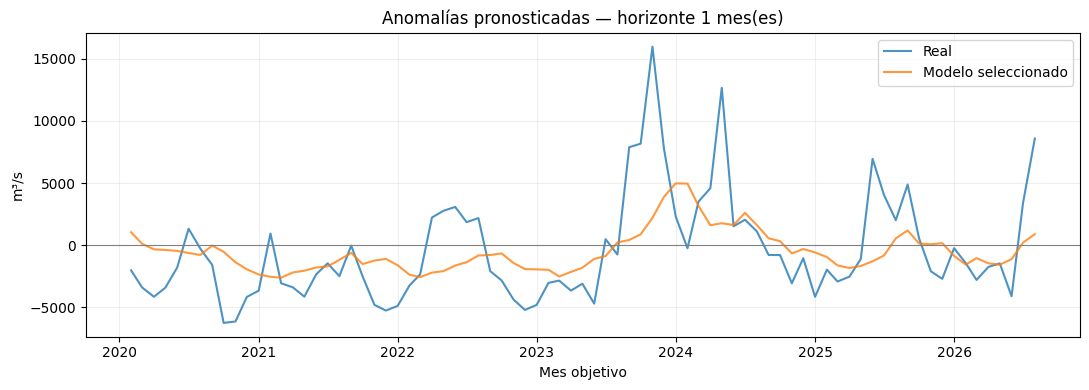

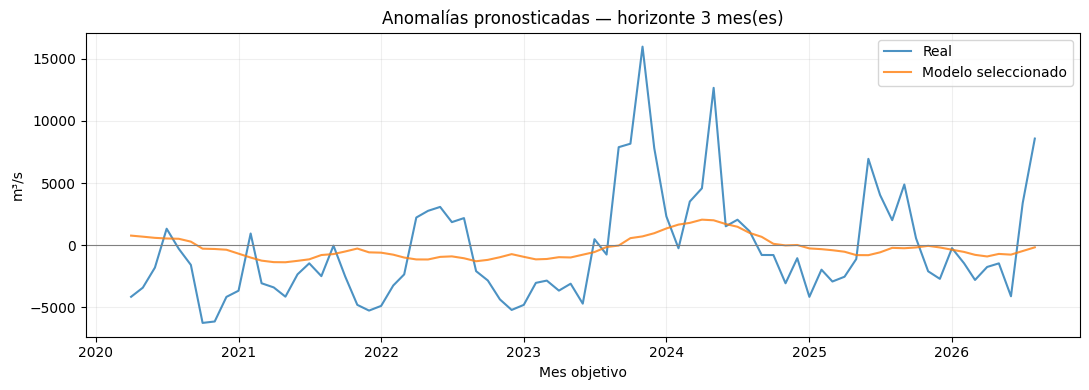

CONTROL DE TRAZABILIDAD
Corte Test: 2020-01-01
Predictoras ENSO: ['oni_lag2', 'roni_lag2', 'soi_lag2']
Predictoras hidrológicas: ['caudal_lag1', 'caudal_lag2']
Advertencia: fechas de publicación ONI/RONI/SOI aún no verificadas.
Advertencia: resultados pasados del notebook NO reemplazan esta nueva evaluación.


In [70]:
# 5.5. Diagnósticos y trazabilidad para el informe
import matplotlib.pyplot as plt
for h, dfp in predicciones_v2.items():
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(dfp['objetivo_fecha'], dfp['real_anomalia'], label='Real', alpha=.8)
    ax.plot(dfp['objetivo_fecha'], dfp['estimado_anomalia'], label='Modelo seleccionado', alpha=.8)
    ax.axhline(0, color='gray', lw=.8)
    ax.set(title=f'Anomalías pronosticadas — horizonte {h} mes(es)', ylabel='m³/s', xlabel='Mes objetivo')
    ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()

print('CONTROL DE TRAZABILIDAD')
print('Corte Test:', CORTE_TEST.date())
print('Predictoras ENSO:', PRED_ENSO)
print('Predictoras hidrológicas:', PRED_HIDRO)
print('Advertencia: fechas de publicación ONI/RONI/SOI aún no verificadas.')
print('Advertencia: resultados pasados del notebook NO reemplazan esta nueva evaluación.')




1. La **tabla de CV** es el lugar donde se compara de forma honesta el desempeño de las familias ENSO, hidrológica y combinada. La familia hidrológica incluye caudales `t−1` y `t−2`, conocidos al comenzar `t`; así se estima si ENSO aporta información **incremental**.
2. El **holdout 2020–2026** sirve solo como validación final del candidato seleccionado mediante CV. No cambiar el modelo tras ver los números de Test sin establecer un **nuevo holdout**.
3. Si ENSO supera la climatología pero pierde contra el modelo hidrológico, **no** es correcto concluir que mejora el pronóstico respecto de la información local. Si la combinación ENSO + hidrológico supera al hidrológico en CV y Test, existe evidencia más sólida de valor incremental (no evidencia causal).
4. Para un pronóstico operativo, verificar los retrasos reales de publicación de ONI/RONI/SOI y la revisión retrospectiva de índices. Documentar cuándo se emitirá cada predicción y qué datos estarán efectivamente publicados.
5. Esta sección conserva la pregunta y los horizontes originales, pero reemplaza el criterio de evaluación. Las conclusiones anteriores de la sección 3 deben actualizarse con los resultados efectivamente ejecutados de la versión v2.


# 6. Conclusiones finales

## Objetivo y alcance
Este trabajo estudia la relación entre índices de ENSO (ONI, RONI, SOI) y anomalías mensuales del caudal en el río Uruguay, sector Salto Grande. Se evaluaron pronósticos del caudal mensual de los meses `t+1` y `t+3`, usando información disponible al origen `t`, bajo la hipótesis de índices climáticos con rezago de dos meses. **No se predice directamente generación hidroeléctrica.**

## Metodología
Se utilizaron modelos lineales OLS y Ridge, con variables ENSO, rezagos del propio caudal (1 y 2 meses) y ambas familias combinadas. Se validó con particiones cronológicas, excluyendo del entrenamiento las etiquetas posteriores al corte de cada fold y estimando la climatología exclusivamente con datos anteriores al corte correspondiente. Se seleccionó el modelo por MAE de validación cruzada sobre entrenamiento; Test (orígenes desde enero de 2020) se reservó para evaluación final. Se usaron como referencias una anomalía nula (climatología) y persistencia.

##RESULTADOS:

| Horizonte | Seleccionado por CV | MAE CV (m³/s) | MAE Test (m³/s) | RMSE Test (m³/s) | R² Test | n Test |
|---|---|---:|---:|---:|---:|---:|
| 1 mes | ENSO + hidrológico — Ridge α=100 | 2718,10 | 2627,62 | 3598,43 | 0,264 | 79 |
| 3 meses | ENSO — Ridge α=100 | 2875,82 | 2979,86 | 3930,24 | 0,137 | 77 |

En Test, las referencias climatológicas obtuvieron MAE de **3321,79** y **3337,48** m³/s (1 y 3 meses), y persistencia **3128,37** y **4308,96** m³/s, respectivamente. Los modelos seleccionados redujeron el MAE frente a climatología aproximadamente **20,9 %** a un mes y **10,7 %** a tres meses.

En la validación cruzada, el mejor modelo puramente hidrológico obtuvo MAE **2767,82** a un mes y **2892,92** a tres meses. El combinado mejoró al hidrológico en aproximadamente **1,8 %** a un mes; a tres meses, ENSO solo y el combinado prácticamente empataron (**2875,82** frente a **2875,89**). Estas diferencias pequeñas no bastan para demostrar robustez estadística ni una mejora incremental generalizable sobre datos hidrológicos.

## Interpretación y limitaciones
Los resultados respaldan **capacidad predictiva moderada** de modelos lineales con ENSO frente a climatología y persistencia en el período de prueba, pero no prueban causalidad ni demuestran inequívocamente el aporte incremental de ENSO frente a todos los modelos hidrológicos. Las observaciones extremas y la variabilidad temporal pueden condicionar la precisión. El conjunto Test tiene 79 y 77 observaciones según el horizonte. La disponibilidad real y las revisiones de publicación de ONI/RONI/SOI aún deben verificarse para un uso operativo. La sección anterior de modelado queda como exploración histórica, no como resultado definitivo.

## Trabajo futuro
Verificar fechas de publicación de índices, cuantificar incertidumbre y estabilidad temporal, estudiar errores durante extremos hidroclimáticos y extender la comparación a modelos no lineales sin ajustar decisiones sobre el Test actual. La sección 4 incorpora K-Means con selección de k por Silhouette, perfiles y visualización de anomalías. Sus resultados deben completarse con las salidas de ejecución en Colab y se interpretan como descripción retrospectiva, no como prueba predictiva.


## Aprendizaje no supervisado
Se implementó K-Means utilizando RONI y SOI rezagados dos meses y la anomalía mensual del caudal, con escalado previo, evaluación de k=2 a 6 por inercia y Silhouette, y caracterización de grupos por su anomalía media y dispersión. **El número de grupos, Silhouette y perfiles se generan al ejecutar la sección 4; no se atribuyen resultados numéricos que todavía no han sido observados.** La interpretación es retrospectiva porque se utiliza el caudal observado para agrupar.


# Referencias

- [INA — Sistema de Información Hidrológica](https://alerta.ina.gob.ar/).
- [NOAA/CPC — datos ONI](https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt).
- [NOAA/CPC — documentación RONI](https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/roni/).
- [NOAA/PSL — catálogo de series climáticas](https://psl.noaa.gov/data/timeseries/month/).
- [Bureau of Meteorology — SOI mensual](https://www.bom.gov.au/clim_data/IDCKGSH000/soi_monthly.txt).
- Timmermann et al. (2018). [El Niño–Southern Oscillation complexity](https://doi.org/10.1038/s41586-018-0252-6). *Nature*.
- Santoso, McPhaden y Cai (2017). [The Defining Characteristics of ENSO Extremes and the Strong 2015/2016 El Niño](https://doi.org/10.1002/2017RG000560). *Reviews of Geophysics*.
- Levine y McPhaden (2015). [The annual cycle in ENSO growth rate as a cause of the spring predictability barrier](https://doi.org/10.1002/2015GL064309). *Geophysical Research Letters*.
- Géron. [Checklist para proyectos de Machine Learning](https://github.com/ageron/handson-ml3/blob/main/ml-project-checklist.md), material complementario de *Hands-On Machine Learning*, tercera edición. Se adapta su organización al alcance exploratorio y temporal del proyecto.
